# Leeds CityFM: background, evidence, embeddings, retraining and a first real test

This notebook brings together where we are in adapting CityFM to Leeds. It has five parts:

| Part | Sections | What it covers | Needs the model? |
|---|---|---|---|
| **Background** | A1-A7 | The problem, how CityFM works in plain terms, where we are, headline results, glossary | No (text only) |
| **Pipeline evidence** | B, C, D | One section per pipeline step for the current model (v1): the data that went in (B), whether training worked (C), downstream results (D) | C3-C4 only |
| **Embedding analysis** | §1-§7 | What the v1 embeddings actually capture | Yes |
| **Next model (v2)** | E1-E3 | The changes made for the retrain and what they do to the inputs (E1-E2), then the retrained models v2, v3a and v3b (E3) | v1, for comparison |
| **Population density** | F1-F5 | The first real test: predicting 2021 Census population density from the embeddings, against simple baselines | No (uses the caches written by `CityFM_pop_eval.py`) |

Results are summarised in **A6**, with links to the cells that produce them. Run the notebook top to bottom. The first run encodes everything (about 25 min on an M2 CPU). After that, results are cached in `Leeds/Analysis/` and a re-run takes a few minutes. Part E also needs `Leeds_v2/Data/`, made by `python CityFM_collapse.py -c Leeds -o Leeds_v2`, and the `train.log` of each retrained model. Part F needs the caches from `python CityFM_pop_eval.py -c Leeds -m Leeds Leeds_v2 Leeds_v3a Leeds_v3b` (see F5).

## ToDo

Roughly in priority order. References in brackets point to the evidence in this notebook.

### [ ] 1. Make road-segment contexts informative (affects stages 1 and 3, and the downstream embeddings)

Lots of roads in Leeds are surrounded mostly by houses. A context holds 55 entities on average, and 44 of them are the identical string `building: house` (B1, B2). The context embeddings of most roads therefore look almost the same, so the model cannot tell different types of road apart. This hurts stage 1 (the random context entity in the quiz is usually a house, C3), stage 3 (C5), and every downstream task that uses context embeddings.

 - [x] Collapse houses into a single summary entry (e.g. `houses: 44` rather than 44 near-identical entries). BERT handles numbers poorly, so a binned word (`houses: many`) may work better than the count. Treat the other residential tags the same way (`building: residential`, `building: semidetached house`, `building: detached`, ...). This makes the non-residential entities (shops, schools, pubs, ...) visible in the context. *Code done 20 Oct (`CityFM_collapse.py`, `Leeds_v2/`; see E1); awaiting retrain.*
 - [ ] Add the road's own description to its context. Pre-processing already stores each segment's OSM tags in `Leeds/Data/data.json` (e.g. `highway: secondary, name: Pudsey Road, ref: B6154`), but training never reads them, and `highway` is not in `osm_strings.use_tags`. Add an entry such as `highway: secondary`. Be careful with the name: in stage 3 the two segments of a pair are often consecutive pieces of the same road, so a shared name would let the model match them on the name alone.
 - [ ] Decide what to do with service roads and paths. `service` (driveways, car-park aisles: 21,282 segments, 38%) and `path` (5,024, 9%) are kept by pre-processing, so almost half the "roads" are not streets. Dropping them, or treating them separately, would focus training on the street network.
 - [x] Before a full retrain, re-run B1/B2 and the C3 quiz on the new contexts to check they are smaller and more varied. *Done in E1f-E1g.*

### [ ] 2. Replace the stage-3 target with a network statistic

 - [ ] Compute local integration / choice (space syntax), or closeness / betweenness, at a few radii (e.g. 400 m, 1,200 m, citywide) with `momepy` or `cityseer`. Unlike bus routes, which cover 5,420 of 55,439 segments (B1), these exist for every segment.
 - [ ] Pair segments by similarity of these values instead of by bus-route count.
 - [ ] Do **not** also write these statistics into the context. If both the input and the target contain them, stage 3 becomes simple text matching and the model learns nothing new.
 - [x] Check whether stage 3 just needed a working learning rate. *No: with the fix (v3a, v3b) it still learns almost nothing (E3).*
 - [ ] Fix the loop at `utils/training.py:497`. It `continue`s without advancing `idx`, so a window with fewer than two pairs would loop forever.

### [ ] 3. Improve the building-footprint branch (stage 2), if building function matters

 - [x] Load ImageNet-pretrained ResNet-18 weights. `config.vision_model_weights` is defined but never used, so the image model currently starts from random weights.
 - [x] Rasterise footprints in metres rather than degrees. Degrees stretch shapes about 1.7× east–west at Leeds' latitude (§6). *Code done 20 Oct (`config.vision_pretrained`, `config.raster_metric`; see E2); awaiting retrain.*
 - [ ] Drop names from the text side of the stage-2 quiz. The sampler (`u_sampling`) gives each 64-way quiz 64 different texts, and 64% of them contain a name (e.g. `name: Halton Medical Practice, amenity: clinic`), which an outline cannot predict. Matching outlines to building *types* is a task the image network can actually learn.
 - [ ] Consider merging residential tags in the stage-2 quiz too. The quiz currently asks the model to tell `building: house` from `building: detached` by outline alone.
 - [ ] Train stage 2 for longer. v3b's loss was still falling steeply at step 625 (E3).

### [ ] 4. Downstream evaluation (part F)

 - [x] Build a Census 2021 population-density task. *Done 23-25 Oct on Output Areas and a 500 m grid (`CityFM_uk_pop.py`, `CityFM_pop_eval.py`; F).*
 - [x] Baselines: simple OSM counts, position and untuned BERT. *Done (F1). The 9 simple counts match every CityFM model, and CityFM adds nothing on top of them (F3).*
 - [x] Compare the current model with the retrained models. *v1, v2, v3a and v3b are within 0.02 of one another (F3).*
 - [ ] Try a task that simple counts cannot solve easily: the Index of Multiple Deprivation (IMD), land use, or DfT traffic flows (AADF) (F5).

### [x] 5. Training schedule

 - [x] Fix the learning-rate schedule. In the original code it reached zero at step 43 of 125 (stage 1) and step 10 of 270 (stage 3). *Fixed in `utils/training.py` (E3).*
 - [x] Try longer training. `CityFM_train.py` now takes `-e` (epochs) and `-m` (samples per epoch); v3b used `-m 32000`, 5× the default (E3).


---
# Background

## A1. The problem and the motivation

Many urban analytics questions need a **numerical description of a place**. What is around this street? What is this building used for? What kind of neighbourhood is this? The usual approach is to hand-craft features for each task (e.g. "number of shops within 500 m") and fit a model to them. This works, but it is redone for every task and every city.

A **foundation model** takes a different route. It is trained once, on a large amount of *unlabelled* data, to turn things into **embeddings**: fixed-length lists of numbers (here 768). Training is set up so that things which are similar in the real world end up with similar numbers. The same embeddings can then be reused for many tasks (population density, land use, traffic speed, ...) by training only a small model on top. Word embeddings are the familiar example: words used in similar contexts, like "tea" and "coffee", end up with similar vectors.

**CityFM** (Balsebre *et al.*, CIKM 2024; this repository is the authors' code) applies the idea to cities using only **OpenStreetMap (OSM)**. OSM is free, global and consistently tagged, so in principle a city model could be built anywhere without labelled data. The authors trained and tested it in Singapore, New York and Seattle.

**Our question:** does CityFM transfer to a UK city, and is what it learns useful for UK urban analytics? This breaks down into:

1. Can it be built for Leeds at all (data volume, compute)? → sections **B** and **C**
2. Did the self-supervised training actually work, i.e. did the model learn the patterns it was asked to learn? → section **C**
3. What do the Leeds embeddings capture? → **§1-§7**
4. Do they help predict real UK outcomes (Census 2021 population density, deprivation, traffic) better than simple baselines? → section **D** (*not done yet*)
5. Do simple fixes to the inputs make training work better? → part **E** (*v2 prepared, retrain pending*)

## A2. The data CityFM sees

CityFM downloads a city from OSM (`CityFM_preprocess.py`) and keeps four kinds of object:

| What | OSM source | Kept if | Leeds |
|---|---|---|---|
| **POIs** (points of interest) | nodes | they have an `amenity`, `shop`, `tourism`, `leisure`, `office`, `healthcare` or `sport` tag. Street furniture such as benches, bins and bike racks is dropped | 9,429 |
| **Buildings** (strictly, tagged polygons: car parks are included too) | closed ways | they have a `building` tag other than `yes`, `roof`, `garage`, `terrace` or `shed`, or an `amenity`/`shop`/`office`/`healthcare` tag | 262,729 |
| **Road segments** | ways with a `highway` tag | they are not footways, cycleways or steps | 55,439 |
| **Bus routes** | `route=bus` relations | they contain at least 7 road segments | 153 |

Two things about this data matter for everything that follows.

* **The model reads tags as text.** Each POI or building becomes a short string built from up to nine tags (`name, amenity, shop, tourism, healthcare, office, leisure, sport, building`), e.g. `name: Greggs, shop: bakery` or just `building: house`. All other tags (cuisine, opening hours, address, levels, ...) are thrown away. The coordinates are *not* part of the string. To the model, two unnamed post boxes are therefore identical, wherever they are.
* **Every road segment gets a "context":** the list of all POIs *and buildings* within 100 m of the points along it (`config.context_d`). Two of the three training stages learn from these contexts. In Leeds, a context holds 55 entities on average, and 80% of them are the identical string `building: house`. That is very different from the paper's cities (section **B**). The next model (v2) replaces all the house-type buildings in a context with one summary entry, which brings Leeds down to 8.8 entries per segment (**E1**).

## A3. How CityFM is trained, in plain terms

**The building blocks.**

* **BERT** (`bert-base-uncased`) is a general-purpose language model, pre-trained by Google on books and Wikipedia. It turns a string into 768 numbers. Out of the box it already "knows" that *cafe* and *coffee* are related, but nothing about Leeds. CityFM **fine-tunes** it, i.e. keeps adjusting its weights.
* **ResNet-18** is a standard image-recognition network design. CityFM uses it to "look at" building footprints, each drawn as a 224×224 black-and-white picture. In v1 the code loaded it **without pre-trained weights** (`config.vision_model_weights` is defined but never used), so it started from random numbers and had to learn to read footprints from scratch in stage 2. v2 starts from ImageNet weights instead (**E2**).
* **Projection heads** are small extra layers. They map the BERT and ResNet outputs into one shared 768-number space, so that text and footprints can be compared.
* **Positional encoding.** Latitude and longitude are converted into 256 numbers by a fixed sine/cosine formula. Nothing about it is learned, so it is not analysed here.

**Contrastive learning: a matching quiz.** No training stage uses labels. Each one is a multiple-choice **matching quiz** instead. The model is given a batch of pairs that belong together, for example 64 POIs and the 64 streets they sit on, all shuffled. It has to match each item to its true partner rather than one of the decoys. The **loss** (the specific formula is called *InfoNCE*) is low when true partners get more similar embeddings than the decoys do. After thousands of quizzes, the weights have shifted so that things which belong together are close in embedding space.

One property of the loss is used repeatedly in section **C**. Its value for **pure guessing** (all similarities equal) is known exactly, so the training log tells us how far the model got beyond guessing.

**The three stages** (run in this order by `CityFM_train.py`):

| Stage | Name in log | The quiz | What is trained | Quiz size | Intended effect |
|---|---|---|---|---|---|
| 1 | Infomax | one entity picked at random from a street's context ↔ that street's whole context | BERT + text projection | 64 streets | things found near each other get similar embeddings (e.g. *cafe* moves towards *bakery* if they share streets) |
| 2 | Polygon | a building's footprint picture + floor area ↔ its tag text | ResNet (v1: from random weights; v2: from ImageNet weights) + footprint/area projections; the text side is frozen | 64 buildings with distinct tag strings | a footprint's embedding points at the text of its building type |
| 3 | Relation | one street's context ↔ the context of another street with almost the same **bus-route count** | BERT + text projection (10× lower learning rate) | ≈10 pairs | streets of similar importance in the bus network get similar context embeddings |

*Bus-route count* means the number of bus routes using a segment, divided by the busiest segment's count (61 routes in Leeds). Two segments are paired if these scaled counts differ by at most 0.02. Note that the pairs do **not** have to be on the same route, or even near each other.

**A "context embedding"** (stages 1 and 3) is BERT run on every entity in the context, averaged, then projected. Because Leeds contexts are mostly houses, a Leeds context embedding is dominated by the embedding of `building: house`. v2 replaces the houses with one summary entry (**E1**).

**How much training happens.** Each stage runs 5 *epochs* (passes). Stages 1 and 2 stop each epoch after 6,400 items (`config.m_index`). The amount of training is therefore fixed, whatever the city's size: stage 1 sees about 32,000 street draws in total, and stage 2 sees 32,000 building draws. One "step" in the log is 4 quizzes (stages 1-2) or 1 quiz (stage 3).

## A4. What the trained model produces, and how it would be used

| Entity | Embeddings (`encoder.py`) | Learned in |
|---|---|---|
| POI | **text** (768 numbers) + positional (256, fixed formula) | stages 1 and 3 |
| Building | **text** (768) + **visual** (768: footprint shape + area) + positional | text: stages 1 and 3; visual: stage 2 |
| Road segment | `encode_polylines` returns only hand-made features (road type, lanes, speed limit). The learned representation of a road is its **context embedding** (A3), which `encoder.py` does not expose | stages 1 and 3 |

**Downstream use.** To test whether the embeddings are useful, one freezes them and trains a *small* model on top to predict something real, e.g. population density per area. It is then scored on held-out data it never saw. For a continuous target the usual score is **R²**: the share of the variation in the target that the predictions explain. 1 is perfect, and 0 is no better than always predicting the average. The fair comparison is against **baselines** that skip CityFM (raw POI counts, untuned BERT), because the question is what CityFM *adds*.

## A5. Where we are

| | Status | Evidence |
|---|---|---|
| **Software and data** | The authors' code runs on the Mac (Python 3.9, `requirements-arm64.txt`), with fixes to the OSM download and a `-r <OSM relation id>` option. Leeds (district boundary) is pre-processed: 9.4k POIs, 263k buildings, 55k road segments, 153 bus routes | **B** |
| **Current model (v1)** | `Leeds/Model/model.pkl`, trained on the research server on 22-23 Sep with stock settings (about 7 h). All three stages ran, but there is little evidence they learned their tasks | **C**, **§1-§7** |
| **Retrained models (v2, v3a, v3b)** | All use the v2 inputs: houses collapsed into one summary entry per context (`Leeds_v2/`), and a fixed image network (ImageNet weights, footprints in metres). v2 was trained on 23 Oct with stock settings. v3a adds a fix to the learning-rate schedule, and v3b also trains stages 1 and 2 for 5× longer (23-25 Oct) | **E** |
| **Downstream tasks** | Census 2021 population density on Output Areas and on a 500 m grid. Every CityFM model matches nine simple OSM counts, but none beats them | **F** |

"v1", "v2", "v3a" and "v3b" are used throughout for these models.

## A6. Where things stand: headline results

**Data (B).** The Leeds data is much denser than the paper's cities. Each road segment has 55 context entities on average, against 8-12 in Seattle, New York and Singapore. 80% of those entries are the same string, `building: house`, because UK building coverage in OSM is close to complete. This is the main reason training needed more memory, and it dilutes the stage-1 signal.

**Training of v1 (C).** All three stages ran, but only stage 1 learned much:

| Stage | Loss vs random guessing (C2) | Matching quiz on the final model (C3-C4) | Verdict |
|---|---|---|---|
| 1. POI ↔ street | below guessing from the start (16% of the way to the floor in the first 25 steps), and only 19% of the way by the end | top-1 18.9%, the same as untuned BERT (19.2%) and below plain tag matching (23.4%). With the POI held out: 4.1%, the same as BERT (4.1%) and tag matching (4.7%). Guessing: 1.6% | no measurable gain on its own task over untuned BERT (though see §5e) |
| 2. Footprint ↔ tags | starts above guessing, ends just below it (3% of the way to the floor) | top-1 4.5% vs 1.6% for guessing | weak; the image network started from random weights |
| 3. Street ↔ street with similar bus-route count | at or above guessing for all 270 steps | (not tested separately) | no evidence it learned anything |

So training ran, but **the evidence that it learned its tasks is thin**. Stage 1 is the stage that shapes the POI text embeddings. It did reorganise how categories relate to one another in line with co-occurrence (§5e). But it does not make a street any easier to recognise from its POIs than untuned BERT does, probably because Leeds contexts are dominated by houses (B2). Whether the reorganisation helps real tasks can only be settled downstream (D).

**Embeddings (§1-§7).**

* POI embeddings are mostly set by the **category tags**. Names barely matter: two hairdressers with different names have cosine similarity ≈ 0.998 (§5d).
* Training did inject **spatial co-occurrence**. Category pairs that are often found within 100 m of each other are more similar under CityFM (Spearman ρ = 0.62) than under untuned BERT (ρ = 0.20) (§5e). This is the clearest evidence that stage 1 did its job.
* Category identity is preserved, but not sharpened. kNN category prediction is slightly better than BERT (macro accuracy 0.94 vs 0.90, §5c), while same-vs-different-category separation is lower (AUC 0.81 vs 0.90, §5a). Training squeezed all POIs closer together.
* **Building footprint embeddings are weak.** Predicting a building's class from its footprint embedding (0.23 accuracy) is barely better than from floor area alone (0.19) (§6a). Matching a footprint to its class's text scores 0.13, where chance is 0.06 (§6b). Footprints are also rasterised in degrees, which shears them (§6c; fixed in v2, **E2**).

**The v2 inputs (E1-E2).** These are measured on the inputs, before any retraining:

* **Contexts shrink from 55.1 to 8.8 entries**, in line with the paper's cities (8-12). POIs and non-residential buildings go from 15% of an average context to 92% (E1f).
* **The four summary entries split the residential segments roughly evenly** (15-22% each; 28% of segments get none) (E1a-b). The detailed house types they replace are mostly mapping habit: 94% are plain `house`, and `semidetached house` and `residential` come in local clusters rather than any city-wide pattern (E1c-d).
* **The summary entry partly reflects segment length.** `very many houses` goes to 4% of segments under 25 m, 24% of those 100-200 m long and 39% of those 200-400 m long (E1e).
* **Streets get slightly easier to tell apart, even for untuned BERT.** On the POI-held-out quiz, top-5 rises from 12.7% to 15.4% (standard error of the difference 1.0 point), and the median rank of the true street improves from 28th to 23rd of 64 (E1g). This is the baseline the v2 model has to beat.
* **The fixed image network starts with more shape information than v1 ended with.** Outline-only class accuracy rises from 0.13 (v1, the same before and after training) to 0.19. With floor area added it reaches 0.27, against 0.21 for area alone and 0.24 for v1's trained visual embedding (E2b).

**Retrained models (E3).** The original code had a learning-rate bug: the rate reached zero after a third of stage 1 and after 10 of 270 steps in stage 3, so most training was wasted. With the bug fixed and stages 1 and 2 trained for 5× longer (v3b), stage 1 gets 26% of the way from guessing to the floor (v1: 19%), and stage 2 gets 24% (v1: 3%). Stage 3 still learns almost nothing.

**Population density (F).** The first real test predicts 2021 Census population density from the embeddings, scored on neighbourhoods the model has not seen. On a 500 m grid (the fair test, F2), R² is:

| Features | R² |
|---|---|
| 9 simple OSM counts (buildings, houses, POIs, footprint area, ...) | 0.76 |
| 9 simple counts + position | **0.80** |
| Untuned BERT text | 0.68 |
| CityFM text (v1 / v2 / v3a / v3b) | 0.71 / 0.69 / 0.70 / 0.71 |
| CityFM text + footprints + position, as in the authors' task (v1 / v2 / v3a / v3b) | 0.77 / 0.76 / 0.75 / 0.75 |
| Counts + position + all of v3b's embeddings | 0.80 |

CityFM's training improves on untuned BERT, but **no CityFM model beats the simple counts, and the embeddings add nothing on top of them**. The training improvements in E3 do not show up in this task. In Leeds, where almost every house is mapped, counting buildings already tells you where people live (F5).

**Open issues.**

* Population density turns out to be easy to get from simple counts. A harder task (IMD, land use, traffic flows) is needed to show whether the embeddings capture anything more (F5).
* `utils/training.py:497`: in stage 3, the `continue` skips `idx += config.index_rel`. A window with fewer than 2 pairs would loop forever and keep using memory. It did not trigger for Leeds (the simulated windows in C2 all had 6-14 pairs), but it should be fixed before other regions.
* National scale would need a new data layer. Pre-processing is O(segments × entities) pure Python, uses a single Overpass query and keeps only POIs within 50 km of the first one downloaded (`config.filter_out_d`).

## A7. Glossary

| Term | Meaning here |
|---|---|
| **Embedding** | A fixed-length list of numbers (a vector) that represents a thing. Similar things should have similar vectors |
| **Cosine similarity** | How closely two vectors point in the same direction: 1 = same direction, 0 = unrelated, −1 = opposite. The standard way to compare embeddings |
| **Self-supervised / contrastive learning** | Training without labels by making up a task from the data itself, here "match each item to its true partner" |
| **InfoNCE loss** | The score of that matching task. Lower is better. It has a known value for pure guessing |
| **Batch, step, epoch** | A batch is one quiz's worth of items; a step is one weight update; an epoch is one pass over the (capped) training data |
| **Fine-tuning** | Continuing to train an already-trained model (BERT) on a new task |
| **Baseline (vanilla BERT)** | The same text pipeline with untuned BERT. The difference from CityFM is what CityFM training added |
| **Top-1 / top-5 accuracy** | In a 64-way quiz: how often the true partner is ranked first / in the top 5. Guessing gives 1.6% / 7.8% |
| **kNN (k-nearest neighbours)** | Predict an item's label from the labels of its k most similar items |
| **AUC** | Probability that a random "should be similar" pair scores higher than a random "should be different" pair. 0.5 = no signal, 1 = perfect |
| **Spearman ρ** | Rank correlation: do two quantities go up together? −1 to 1 |
| **UMAP / PCA** | Ways to squash 768-number vectors into 2-3 numbers for plotting. PCA is linear; UMAP preserves local neighbourhoods |
| **Zero-shot** | Making a prediction with no training on that task, here matching footprints to text prototypes directly |
| **R²** | Share of the variation in a target explained by the predictions (1 = perfect, 0 = as good as predicting the mean) |
| **Learning rate** | How big a change the model makes to its weights after each step. Training usually shrinks it towards zero as it goes |
| **Output Area, LSOA, MSOA** | Census areas, nested: Output Areas hold about 300 people (in Leeds), LSOAs about 1,500 and MSOAs about 7,500 |
| **Ridge regression** | A linear model with a penalty that stops it leaning too heavily on any one feature. Used here to predict density from features |
| **Spatial cross-validation** | Testing a model on whole neighbourhoods it never saw in training, so that it cannot score well just by copying nearby areas |
| **Log scale** | A scale on which each step multiplies by the same amount (10, 100, 1,000, ...), so "twice as dense" counts the same everywhere |

---
# Setup

**Once:** `uv pip install --python .venv/bin/python jupyter ipykernel umap-learn==0.5.7`, then pick the *CityFM (.venv)* kernel. (umap-learn 0.5.8+ would upgrade scikit-learn past the pinned version.)

In [1]:
import os, sys, json, time, collections, warnings
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors, BallTree
from sklearn.metrics import roc_auc_score
from shapely.geometry import Polygon
import umap

import config
from utils import osm_strings
from utils.pre_processing import json_string, poly_to_raster, read_model
from utils.training import Tokenizer, serialize_data
from encoder import encode_nodes, encode_polygons

CITY = 'Leeds'
SEED = 0
CACHE = Path(CITY) / 'Analysis'
CACHE.mkdir(exist_ok=True)

# Inference only. encoder.py doesn't wrap its forward passes in no_grad, so without this
# every encoded entity would keep its BERT autograd graph alive.
torch.set_grad_enabled(False)
pd.set_option('display.max_colwidth', 60)

In [2]:
# Plot styling: one categorical order (blue, orange, aqua) + grey for "other"/context,
# single-hue blue ramp for magnitudes.
SURFACE, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e6e5e0'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
OTHER, CONTEXT = '#9d9c95', '#dddcd6'
MODEL_COLOURS = {'CityFM': BLUE, 'Vanilla BERT': ORANGE}
BLUES = LinearSegmentedColormap.from_list(
    'blues', ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'font.size': 9,
    'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.edgecolor': GRID, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'legend.frameon': False,
})

def clean_axes(ax):
    # For embedding scatters the axis values mean nothing.
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

In [3]:
# Small helpers used throughout (they used to live in §2).
def cached(name, ids, fn):
    # Cache an (n, d) array to Leeds/Analysis/<name>.npz. Recompute if the id list changed.
    path = CACHE / f'{name}.npz'
    ids = np.asarray(ids, dtype=str)
    if path.exists():
        z = np.load(path)
        if np.array_equal(z['ids'], ids):
            return z['emb']
    t = time.time()
    emb = np.asarray(fn(), dtype=np.float32)
    np.savez(path, ids=ids, emb=emb)
    print(f'{name}: encoded {emb.shape} in {time.time() - t:.0f}s')
    return emb

def l2(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)

def tag_string(e):
    # The exact string the model reads for an entity (as utils.training.serialize_data builds it).
    return json_string({k: e['tags'][k] for k in osm_strings.use_tags if k in e['tags']})

def rasterisable(i):
    try:
        return len(poly_to_raster(Polygon(entities[i]['points']))) > 0
    except Exception:
        return False

---
# Pipeline evidence

## B. Pre-processing: what went into the model

`CityFM_preprocess.py` produced the files in `Leeds/Data/`. The paper's three cities ship pre-processed with the repository, so the same summary can be computed for all four.

**B1.** Counts per city. A road segment's *context* is the set of entities within 100 m of it (A2).

In [4]:
def load_city(city):
    out = {}
    for name in ['entities', 'data', 'relations']:
        with open(f'{city}/Data/{name}.json', encoding='utf-8') as f:
            out[name] = json.load(f)
    return out

def city_summary(d):
    ents, segs, rel = d['entities'], d['data'], d['relations']
    strings = {k: tag_string(e) for k, e in ents.items()}
    # Contexts exactly as training reads them (ids missing from entities are skipped).
    ctx = [[k for k in s['context'] if k in ents] for s in segs.values()]
    n_ctx = np.array([len(c) for c in ctx])
    n_poi = np.array([sum(ents[k]['type'] == 'node' for k in c) for c in ctx])
    n_house = np.array([sum(strings[k] == 'building: house' for k in c) for c in ctx])
    on_bus = {str(w) for r in rel.values() for w in r}
    return {
        'POI nodes': sum(e['type'] == 'node' for e in ents.values()),
        'buildings': sum(e['type'] == 'polygon' for e in ents.values()),
        'road segments': len(segs),
        'bus routes': len(rel),
        'road segments on a bus route': sum(k in on_bus for k in segs),
        'context size: mean': n_ctx.mean(),
        'context size: median': np.median(n_ctx),
        'context size: 95th percentile': np.percentile(n_ctx, 95),
        'segments with an empty context': (n_ctx == 0).mean(),
        'per segment: POIs': n_poi.mean(),
        'per segment: "building: house"': n_house.mean(),
        'per segment: other buildings': (n_ctx - n_poi - n_house).mean(),
    }

leeds = load_city(CITY)
entities, data, relations = leeds['entities'], leeds['data'], leeds['relations']
CITIES = [CITY, 'Seattle', 'New York', 'Singapore']
city_stats = {CITY: city_summary(leeds)}
for c in CITIES[1:]:
    city_stats[c] = city_summary(load_city(c))
city_stats = pd.DataFrame(city_stats)

def fmt(row, v):
    if row == 'segments with an empty context':
        return f'{v:.0%}'
    return f'{v:,.1f}' if row.startswith('per segment') or row.startswith('context size: mean') else f'{v:,.0f}'

pd.DataFrame({c: [fmt(r, v) for r, v in city_stats[c].items()] for c in CITIES}, index=city_stats.index)

,Leeds,Seattle,New York,Singapore
POI nodes,"9,429","11,009","43,549","23,621"
buildings,"262,729","22,869","49,502","40,594"
road segments,"55,439","45,213","97,318","167,819"
bus routes,153,240,808,684
road segments on a bus route,"5,420","5,036","18,845","39,337"
context size: mean,55.1,11.8,8.3,8.4
context size: median,40,6,2,4
context size: 95th percentile,167,42,39,36
segments with an empty context,7%,17%,25%,26%
per segment: POIs,3.4,4.7,4.4,3.8


**B2.** Leeds contexts are much larger, and the difference is almost all houses. Two consequences:

* **Memory.** Stage 1 runs BERT on every entity of 64 contexts and back-propagates through all of them. Larger contexts means proportionally more memory (C1).
* **Signal.** A context embedding is an *average*. When 80% of every context is `building: house`, Leeds contexts look alike, and the POIs that make streets different carry less weight in that average.

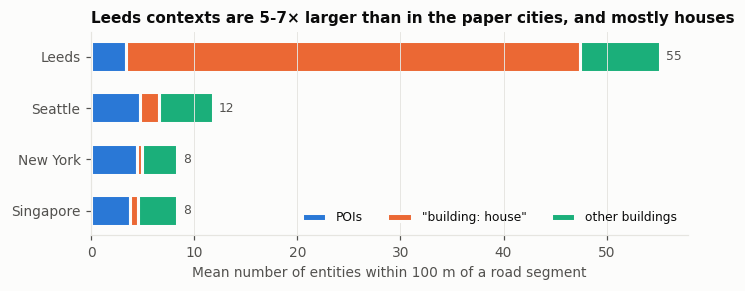

In Leeds, 80% of all context entries are the identical string "building: house".


In [5]:
# What a road segment's context is made of, on average.
parts = ['per segment: POIs', 'per segment: "building: house"', 'per segment: other buildings']
part_labels = ['POIs', '"building: house"', 'other buildings']
part_colours = [BLUE, ORANGE, AQUA]
fig, ax = plt.subplots(figsize=(7, 2.4))
left = np.zeros(len(CITIES))
for p, label, colour in zip(parts, part_labels, part_colours):
    v = city_stats.loc[p, CITIES].values.astype(float)
    ax.barh(CITIES, v, left=left, color=colour, height=0.6, edgecolor=SURFACE, linewidth=2,
            label=label)
    left += v
for i, total in enumerate(left):
    ax.annotate(f'{total:.0f}', (total, i), xytext=(4, 0), textcoords='offset points',
                va='center', fontsize=8, color=INK2)
ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_xlabel(f'Mean number of entities within {config.context_d} m of a road segment')
ax.set_title('Leeds contexts are 5-7× larger than in the paper cities, and mostly houses', loc='left')
ax.legend(loc='lower right', ncol=3, fontsize=8)
plt.show()

share = city_stats.loc[parts[1], CITY] / city_stats.loc['context size: mean', CITY]
print(f'In {CITY}, {share:.0%} of all context entries are the identical string "building: house".')

**B3.** The study area. The download covers the Leeds district boundary, about 32 × 27 km. Its diagonal is about 42 km, so the 50 km cap (A6) removes nothing. Coloured lines are the road segments that stage 3 uses, shaded by how many bus routes run along them.

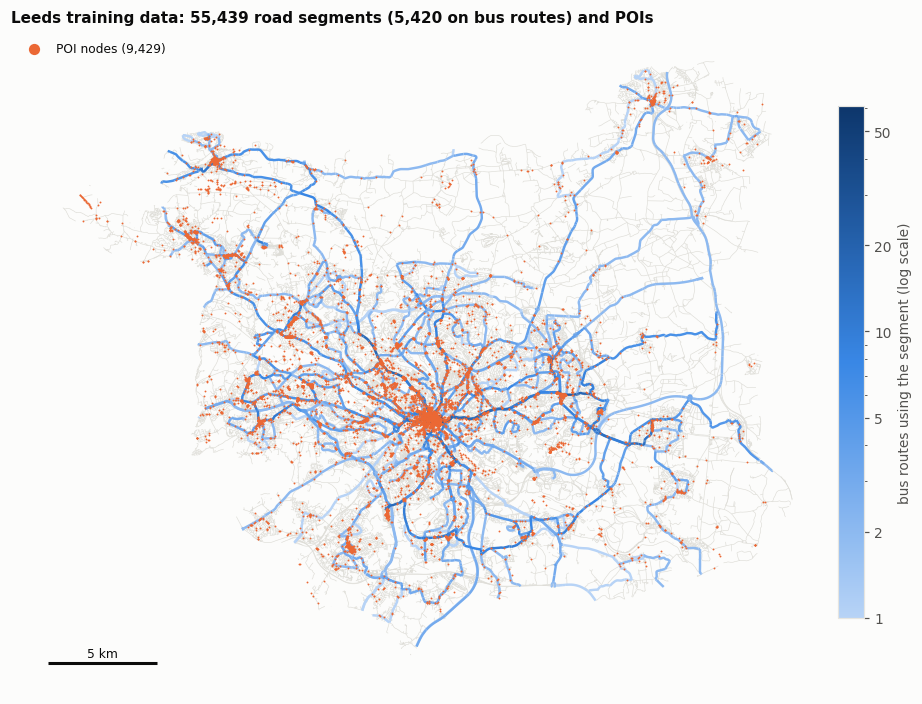

In [6]:
# Where the data is: all road segments, bus-route segments coloured by how many routes use them, and POIs.
from matplotlib.collections import LineCollection
from matplotlib.colors import LogNorm
from pyproj import Transformer

to_bng = Transformer.from_crs('EPSG:4326', 'EPSG:27700', always_xy=True)

def seg_xy(points):
    lat, lon = np.array(points).T
    return np.column_stack(to_bng.transform(lon, lat))

routes_per_seg = collections.Counter(str(w) for r in relations.values() for w in r)
bus_ids = [k for k in data if k in routes_per_seg]
other_ids = [k for k in data if k not in routes_per_seg]
ROUTES = LinearSegmentedColormap.from_list('routes', ['#b7d3f6', '#3987e5', '#0d366b'])
poi_xy = np.array([to_bng.transform(e['lon'], e['lat']) for e in entities.values() if e['type'] == 'node'])

fig, ax = plt.subplots(figsize=(10, 8.5))
ax.add_collection(LineCollection([seg_xy(data[k]['points']) for k in other_ids],
                                 colors=CONTEXT, linewidths=0.4, zorder=0))
n_routes = np.array([routes_per_seg[k] for k in bus_ids])
order_bus = np.argsort(n_routes)
lc = LineCollection([seg_xy(data[bus_ids[i]]['points']) for i in order_bus], array=n_routes[order_bus],
                    cmap=ROUTES, norm=LogNorm(1, n_routes.max()), linewidths=1.6, zorder=1)
ax.add_collection(lc)
ax.scatter(poi_xy[:, 0], poi_xy[:, 1], s=1.5, color=ORANGE, lw=0, zorder=2, label=f'POI nodes ({len(poi_xy):,})')
ax.autoscale_view(); ax.set_aspect('equal'); clean_axes(ax)
cb = plt.colorbar(lc, ax=ax, fraction=0.03, pad=0.01, label='bus routes using the segment (log scale)')
cb.set_ticks([t for t in [1, 2, 5, 10, 20, 50] if t <= n_routes.max()]); cb.set_ticklabels([t for t in [1, 2, 5, 10, 20, 50] if t <= n_routes.max()])
ax.legend(loc='upper left', markerscale=6, fontsize=8)
ax.set_title(f'{CITY} training data: {len(data):,} road segments ({len(bus_ids):,} on bus routes) and POIs', loc='left')
x0, x1 = ax.get_xlim(); y0, _ = ax.get_ylim()
ax.plot([x0 + 1000, x0 + 6000], [y0 + 1000] * 2, color=INK, lw=2, solid_capstyle='butt')
ax.annotate('5 km', (x0 + 3500, y0 + 1000), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=8)
plt.show()

## C. Training: did the model learn?

### C1. Compute

`CityFM_train.py -c Leeds` runs on CPU only (`config.device = 'cpu'`; the code never moves anything to a GPU). Peak memory, measured 21 Sep:

| Run | Peak memory | Outcome |
|---|---|---|
| Seattle, stage 1, stock settings | 16.4 GB | fine |
| Leeds, stage 1, stock settings (`config.bs = 256`) | > 23 GB | killed by macOS on the 32 GB Mac |
| Leeds, stage 1, `config.bs = 64` | 17.9 GB | works on the Mac (about 7.5 h for stage 1) |
| Leeds, stage 2 / stage 3 | 9.4 GB / 10.8 GB | fine |
| Leeds v2 contexts (**E1**), all three stages, stock settings (smoke test, 20 Oct) | 20.5 GB | runs on the Mac but is tight, about 100 s per stage-1 step. v2 will be trained on the server |

`config.bs = 64` leaves the quiz unchanged (still 64 streets). It only updates the weights after every quiz instead of every 4. The model in `Leeds/Model/model.pkl` was trained with **stock settings** on the research server (2× AMD EPYC, 754 GB RAM), overnight on 22-23 Sep, in about 7 h.

### C2. Training loss compared with random guessing

The log of that run has been copied to `Leeds/Model/train.log`. For each stage, the plot compares the loss with two reference lines:

* **Random guessing**: the loss if the model gave every candidate the same score. Below this line means the model can pick out true partners.
* **Theoretical floor**: true partners identical and every decoy opposite. It cannot actually be reached, but it shows the scale.

Stages 1 and 2 report the *sum* of 4 quizzes of 64 per step. Stage 3's quiz size depends on how many pairs can be formed from each shuffled window of 1,024 streets, so its guessing level is estimated by re-running the same pairing rule on shuffled windows.

Stage 3 quizzes contain 10.2 pairs on average (range 6-14).


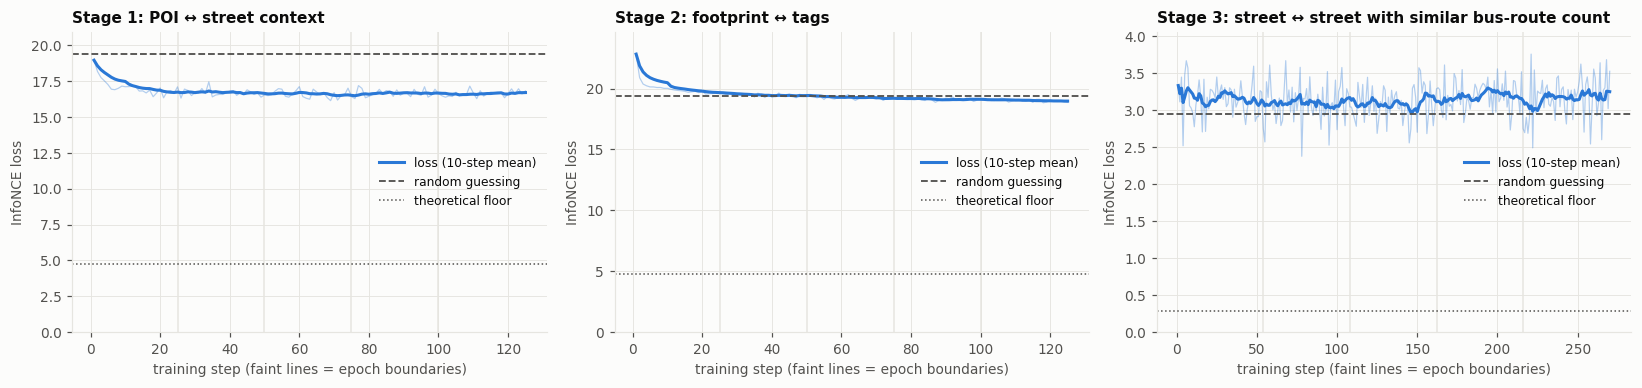

,steps,random-guessing loss,theoretical floor,"mean loss, first 25 steps","mean loss, last 25 steps","way from guessing to floor, first 25 steps","way from guessing to floor, last 25 steps"
Stage 1: POI ↔ street context,125,19.38,4.79,17.08,16.63,16%,19%
Stage 2: footprint ↔ tags,125,19.38,4.79,20.03,19.01,-4%,3%
Stage 3: street ↔ street with similar bus-route count,270,2.95,0.29,3.17,3.22,-8%,-10%


In [7]:
def read_losses(path):
    # train.log has a "(Stage name)" header before each stage, then one "Step N Loss: x" line per step.
    losses, stage = {}, None
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line.startswith('(') and line.endswith(')'):
                stage = line[1:-1]
                losses[stage] = []
            elif line.startswith('Step ') and stage:
                losses[stage].append(float(line.split('Loss: ')[1]))
    return losses

def stage3_pairs(window, hub):
    # The positive pairs train_SS_rel builds from one window of road segments (same greedy rule, faster).
    paired, used_values, pairs = set(), set(), []
    candidates = [k for k in window if k in hub]
    for q in candidates:
        if hub[q] in used_values or q in paired:
            continue
        for k in candidates:
            if k != q and k not in paired and abs(hub[q] - hub[k]) <= config.hub_threshold:
                pairs.append((q, k)); paired.update((q, k)); used_values.update((hub[q], hub[k]))
                break
    return pairs

def infonce_reference(n_pairs, quizzes_per_step=1, temperature=0.5):
    # Loss if all similarities are equal (pure guessing), and the floor (partners identical, decoys opposite).
    n = np.asarray(n_pairs, dtype=float)
    chance = np.log(2 * n - 1)
    floor = np.log(1 + (2 * n - 2) * np.exp(-2 / temperature))
    return quizzes_per_step * chance.mean(), quizzes_per_step * floor.mean()

losses = read_losses(Path(CITY) / 'Model' / 'train.log')

# Stage 3 quiz size varies: simulate the shuffled windows of 1,024 segments a few times.
hub = collections.Counter(str(w) for r in relations.values() for w in r)
hub = {k: v / max(hub.values()) for k, v in hub.items()}
rng = np.random.default_rng(SEED)
seg_keys = np.array(list(data))
n_pairs = [len(stage3_pairs(perm[i:i + config.index_rel], hub))
           for perm in (seg_keys[rng.permutation(len(seg_keys))] for _ in range(3))
           for i in range(0, len(perm) - config.index_rel + 1, config.index_rel)]

STAGES = {  # log name: (short label, reference losses)
    'Infomax': ('Stage 1: POI ↔ street context', infonce_reference([config.index], config.bs // config.index)),
    'Polygon': ('Stage 2: footprint ↔ tags', infonce_reference([config.index_raster], config.bs_raster // config.index_raster)),
    'Relation Contrastive Learning': ('Stage 3: street ↔ street with similar bus-route count', infonce_reference(n_pairs)),
}
print(f'Stage 3 quizzes contain {np.mean(n_pairs):.1f} pairs on average (range {min(n_pairs)}-{max(n_pairs)}).')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
rows = {}
for ax, (stage, (label, (chance, floor))) in zip(axes, STAGES.items()):
    y = np.array(losses[stage])
    x = np.arange(1, len(y) + 1)
    smooth = pd.Series(y).rolling(10, min_periods=1).mean()
    ax.plot(x, y, color=BLUE, lw=0.8, alpha=0.35)
    ax.plot(x, smooth, color=BLUE, lw=2, label='loss (10-step mean)')
    ax.axhline(chance, color=INK2, lw=1.2, ls='--', label='random guessing')
    ax.axhline(floor, color=INK2, lw=1, ls=':', label='theoretical floor')
    for e in range(1, config.n_epochs):
        ax.axvline(e * len(y) / config.n_epochs, color=GRID, lw=1, zorder=0)
    ax.set(xlabel='training step (faint lines = epoch boundaries)', ylabel='InfoNCE loss',
           ylim=(0, max(y.max(), chance) * 1.08))
    ax.set_title(label, loc='left')
    ax.legend(loc='center right', fontsize=8)
    first, last = y[:25].mean(), y[-25:].mean()
    rows[label] = {'steps': len(y), 'random-guessing loss': chance, 'theoretical floor': floor,
                   'mean loss, first 25 steps': first, 'mean loss, last 25 steps': last,
                   'way from guessing to floor, first 25 steps': (chance - first) / (chance - floor),
                   'way from guessing to floor, last 25 steps': (chance - last) / (chance - floor)}
plt.tight_layout(); plt.show()
share_cols = ['way from guessing to floor, first 25 steps', 'way from guessing to floor, last 25 steps']
pd.DataFrame(rows).T.style.format('{:.2f}').format('{:.0f}', subset=['steps']).format('{:.0%}', subset=share_cols)

**Reading C2.**

* **Stage 1** starts well below guessing. Even untrained BERT can spot a POI in its own street's context, because that POI is one of the entities averaged into the context. After that it hardly moves. The first 25 steps are already 16% of the way from guessing to the floor; the last 25 are 19% of the way.
* **Stage 2** starts *above* guessing (the image network starts from random weights) and ends just below it, 3% of the way to the floor. The footprint ↔ text match was barely learned.
* **Stage 3** never gets below guessing (its loss averages 3.2, against 2.95 for guessing). As far as the loss shows, matching streets by bus-route count taught the model nothing. That is not surprising: two streets with the same number of bus routes can be anywhere in Leeds and have nothing in common.

The loss is measured on whatever happened to be in each training batch. C3 and C4 run the same quizzes on the **final** model, with fixed random samples, and compare it with baselines.

### C3. Stage 1 quiz on the final model

Each quiz takes 64 random road segments. Every segment contributes one query entity and its context, and each query has to pick out its own context out of the 64. There are two versions:

* **Training-style:** exactly the training task. The query is a random entity from the context (or "context: none"), and it **stays in** the context. Because 80% of entities are houses, most queries are `building: house`, which cannot identify a street.
* **POI held out:** the query is a POI node, and it is **removed** from the context. This is the more meaningful test: can the model tell which street a POI belongs to from the *other* things on that street?

Each version is scored for three methods besides guessing:

* **Tag matching (no model):** pick the street whose context has the highest share of entities with *exactly* the query's tag string.
* **Vanilla BERT:** the same averaging as CityFM, but with untuned BERT.
* **CityFM:** the final trained model.

CityFM should beat both if training taught it something beyond "spot the same tag string". The first run encodes about 5,000 contexts (about 10 min); after that, results are cached.

In [8]:
# Load the trained model once (also used in §2) and an untuned BERT as the baseline.
from transformers import BertModel

model = read_model(CITY).eval()
tok = Tokenizer(model.lm_name)
bert = BertModel.from_pretrained(config.lm_names['bert']).eval()
ENCODERS = {'CityFM': (model.lm, model.projection_p), 'Vanilla BERT': (bert, torch.nn.Identity())}

def context_embedding(lm, proj, ents, add_zero=True):
    # SSModel.forward(task='info_max'): BERT states averaged over entities, then over token positions
    # (padding included), then projected. Identical rows give identical BERT outputs, so each unique
    # row is encoded once and weighted by its count. add_zero appends "context: none", as training does.
    ids = np.array(serialize_data(ents, tok, add_zero=add_zero))
    rows, counts = np.unique(ids, axis=0, return_counts=True)
    rows = torch.tensor(rows)
    h = lm(rows, attention_mask=(rows != 0).long())[0]
    w = torch.tensor(counts / counts.sum(), dtype=h.dtype)[:, None, None]
    return proj((h * w).sum(0).mean(0)).numpy()

# Fidelity check against the literal computation in SSModel.forward, on a few real contexts.
for k in list(data)[:5]:
    ents = [entities[c] for c in data[k]['context'] if c in entities]
    ids = torch.tensor(serialize_data(ents, tok, add_zero=True))
    literal = model.projection_p(torch.mean(torch.mean(model.lm(ids, attention_mask=(ids != 0).long())[0], 0), 0))
    assert np.allclose(literal.numpy(), context_embedding(model.lm, model.projection_p, ents), atol=1e-4)
print('context_embedding matches SSModel.forward')

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModel: ['cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.bias', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.decoder.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


context_embedding matches SSModel.forward


training-style: random context entity as query, left in the context (exactly the training quiz). 52% of queries are "building: house".


POI held out: a POI node as query, removed from the context (can it predict the rest of the street?). 0% of queries are "building: house".


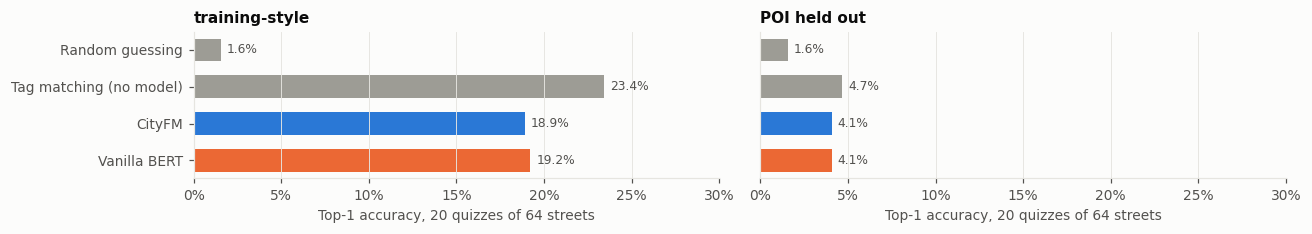

In [9]:
from matplotlib.ticker import PercentFormatter

N_BATCHES, BATCH = 20, config.index  # 20 quizzes of 64, the batch size used in training

def stage1_quiz(variant, seed, data=data, ents=entities):
    # Returns, for N_BATCHES * BATCH road segments, the query entity id (None = "context: none")
    # and the list of context entity ids the query has to be matched with.
    rng = np.random.default_rng(seed)
    if variant == 'training-style':
        pool = list(data)
    else:
        pool = [k for k in data if len(data[k]['context']) >= 2 and
                any(ents[c]['type'] == 'node' for c in data[k]['context'] if c in ents)]
    segs = rng.choice(pool, N_BATCHES * BATCH, replace=False)
    queries, contexts = [], []
    for k in segs:
        ctx = [c for c in data[k]['context'] if c in ents]
        if variant == 'training-style':
            r = rng.integers(0, len(ctx) + 1)  # as train_SS_im: any context entity, or "context: none"
            q = None if r == len(ctx) else ctx[r]
        else:
            q = rng.choice([c for c in ctx if ents[c]['type'] == 'node'])
            ctx = [c for c in ctx if c != q]
        queries.append(q); contexts.append(ctx)
    return segs, queries, contexts

def quiz_accuracy(q_emb, c_emb):
    # Each query must pick its own context out of the BATCH contexts in its quiz.
    ranks = []
    for b in range(N_BATCHES):
        s = slice(b * BATCH, (b + 1) * BATCH)
        sim = l2(q_emb[s]) @ l2(c_emb[s]).T
        ranks.append((sim > np.diag(sim)[:, None]).sum(1))
    ranks = np.concatenate(ranks)
    return {'top-1': (ranks == 0).mean(), 'top-5': (ranks < 5).mean()}

def tag_match_accuracy(queries, contexts, ents=entities):
    # No model: pick the context with the highest share of entries whose tag string equals the query's.
    acc = []
    for b in range(N_BATCHES):
        idx = range(b * BATCH, (b + 1) * BATCH)
        bags = [collections.Counter([tag_string(ents[c]) for c in contexts[j]] + [config.no_context]) for j in idx]
        sizes = np.array([sum(bag.values()) for bag in bags])
        for pos, i in enumerate(idx):
            qs = tag_string(ents[queries[i]]) if queries[i] else config.no_context
            score = np.array([bag[qs] for bag in bags]) / sizes
            best = score == score.max()
            acc.append(best[pos] / best.sum())  # ties split evenly
    return np.mean(acc)

VARIANTS = {
    'training-style': 'random context entity as query, left in the context (exactly the training quiz)',
    'POI held out': 'a POI node as query, removed from the context (can it predict the rest of the street?)',
}
stage1 = {}
for v_i, variant in enumerate(VARIANTS):
    segs, queries, contexts = stage1_quiz(variant, seed=[SEED, v_i])
    def encode():
        cols = []
        for lm, proj in ENCODERS.values():
            cols.append(np.stack([context_embedding(lm, proj, [entities[q]] if q else [], add_zero=False) for q in queries]))
            cols.append(np.stack([context_embedding(lm, proj, [entities[c] for c in ctx]) for ctx in contexts]))
        return np.concatenate(cols, axis=1)
    emb = cached(f'stage1_quiz_{variant.replace(" ", "_")}', [f'{s}|{q}' for s, q in zip(segs, queries)], encode)
    d = config.lm_hidden_sizes['bert']
    res = {'Random guessing': {'top-1': 1 / BATCH, 'top-5': 5 / BATCH},
           'Tag matching (no model)': {'top-1': tag_match_accuracy(queries, contexts), 'top-5': np.nan}}
    for m, name in enumerate(ENCODERS):
        res[name] = quiz_accuracy(emb[:, 2 * m * d:(2 * m + 1) * d], emb[:, (2 * m + 1) * d:(2 * m + 2) * d])
    stage1[variant] = pd.DataFrame(res).T
    houses = np.mean([bool(q) and tag_string(entities[q]) == 'building: house' for q in queries])
    print(f'{variant}: {VARIANTS[variant]}. {houses:.0%} of queries are "building: house".')

fig, axes = plt.subplots(1, 2, figsize=(12, 2.2), sharex=True)
for ax, (variant, t) in zip(axes, stage1.items()):
    ax.barh(t.index, t['top-1'], color=[MODEL_COLOURS.get(n, OTHER) for n in t.index], height=0.6)
    for i, v in enumerate(t['top-1']):
        ax.annotate(f'{v:.1%}', (v, i), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8, color=INK2)
    ax.invert_yaxis(); ax.grid(axis='y', visible=False); ax.set_xlim(0, 0.3)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel(f'Top-1 accuracy, {N_BATCHES} quizzes of {BATCH} streets')
    ax.set_title(variant, loc='left')
    if ax is axes[1]:
        ax.tick_params(left=False); ax.set_yticklabels([])
plt.tight_layout(); plt.show()
pd.concat(stage1, names=['variant', 'method'])[['top-1', 'top-5']].style.format('{:.1%}', na_rep='')

**Reading C3.**

* Every method is far above guessing on the training-style quiz, but mostly for a trivial reason: the query is one of the entities averaged into its own context. Plain tag matching exploits that best (23.4%).
* **CityFM does no better than untuned BERT on its own training task:** top-1 18.9% vs 19.2%. Its top-5 is slightly higher (37.0% vs 33.8%).
* With the POI held out, all three methods sit at 4-5%, about 3× guessing. With 1,280 queries the standard error is about 0.6 percentage points, so the differences between them are noise.
* So after training, a street's context embedding is no easier to recognise from one of its POIs than with untuned BERT. This fits C2: the loss started well below guessing and hardly moved.
* This does **not** contradict §5e. Training did change how *categories* relate to each other: categories that co-occur moved closer together. But a context embedding averages about 55 entities, 80% of them identical houses. At that level, the change is too small to make individual streets more identifiable.

### C4. Stage 2 quiz on the final model

This is the same idea for buildings. Each quiz holds 64 buildings with distinct tag strings, sampled the way `train_SS_raster` samples them, and each footprint has to pick its own tag text out of the 64. §6 analyses the footprint embeddings in more depth.

In [10]:
# Stage 2 quiz: 64 buildings with distinct tag strings (as train_SS_raster samples them);
# each footprint's visual embedding has to pick out its own tag text.
polygon_ids = [k for k, e in entities.items() if e['type'] == 'polygon' and len(e['points']) > 3]

rng = np.random.default_rng(SEED)
quiz2 = []
for _ in range(N_BATCHES):
    seen, batch = set(), []
    for i in rng.permutation(len(polygon_ids)):
        k = polygon_ids[i]
        s = tag_string(entities[k])
        if s not in seen and rasterisable(k):
            seen.add(s); batch.append(k)
            if len(batch) == BATCH:
                break
    quiz2 += batch

def encode_quiz2():
    _, text, vis = encode_polygons(CITY, [entities[k] for k in quiz2])
    return np.concatenate([text.numpy(), vis.numpy()], axis=1)

tv2 = cached('stage2_quiz', quiz2, encode_quiz2)
stage2 = pd.DataFrame({'Random guessing': {'top-1': 1 / BATCH, 'top-5': 5 / BATCH},
                       'CityFM footprint → tags': quiz_accuracy(tv2[:, 768:], tv2[:, :768])}).T
print(f'{len(quiz2):,} buildings, e.g.:', ' | '.join(tag_string(entities[k]) for k in quiz2[:6]))
stage2.style.format('{:.1%}')

1,280 buildings, e.g.: building: house | building: residential | building: industrial | building: semidetached house | name: Carlton Social Club, amenity: pub, building: retail | building: farm auxiliary


,top-1,top-5
Random guessing,1.6%,7.8%
CityFM footprint → tags,4.5%,17.0%


**Reading C4.** Top-1 is 4.5% (top-5 17.0%), against 1.6% (7.8%) for guessing: about 3× guessing. There is some signal, but it is weak. The ceiling is well below 100%, because many buildings in a quiz differ only by name (two named pubs, say), which a footprint cannot reveal. §6a shows that most of the class information in the footprint embedding is floor area, and the image side adds little. That is unsurprising: the image network started from random weights (A3) and got only 125 weight updates.

### C5. Stage 3

There is no separate quiz for stage 3: C2 already shows the loss never went below guessing. Stage 3 also changes the BERT weights that the POI text embeddings use, but with a 10× lower learning rate than stage 1. So it probably did little harm, and had little effect either way.

## D. Downstream tasks (where R² scores come from)

The repository ships three downstream tasks (`CityFM_downstream.py -t ...`). Each needs a ground-truth dataset for the city. Leeds now has one for `pop_density`, built from the 2021 Census (part F):

| Task | Ships for | Ground truth | Uses CityFM embeddings? |
|---|---|---|---|
| `avg_speed` | Seattle, New York | Uber Movement road speeds | **No.** It uses hand-made road features, a fixed positional encoding and the speeds of neighbouring training roads. The model is loaded but never called |
| `pop_density` | Singapore, New York | gridded population | Yes (embeddings of entities in each area) |
| `build_func` | Singapore | land-use zoning | Yes (building embeddings) |

**The one R² we have** is the 18 Sep sanity check: `CityFM_downstream.py -c Seattle -t avg_speed` with the authors' Seattle model gave **test R² = 0.75**. This was terminal output and was not saved; the trained head is `Seattle/Model/model_avg_speed.pkl`. It shows that the code and environment run end to end. It says **nothing about CityFM**, because that task never touches the embeddings.

**Leeds.** Part F runs the population-density task on Leeds, with baselines (simple OSM counts, position, untuned BERT), for v1, v2, v3a and v3b. Candidates for further tasks: the Index of Multiple Deprivation (IMD), land use, DfT annual average daily flows (AADF) in place of `avg_speed`, and Land Registry prices.

---
# Embedding analysis

This part looks at the embeddings the current model (v1, `Leeds/Model/model.pkl`) produces. They are cached in `Leeds/Analysis/*.npz` (`ids`, `emb`) for reuse elsewhere.

**What an embedding actually is here** (see `encoder.py`):

| Entity | Output of `encoder.py` | How it is computed |
|---|---|---|
| POI node | positional (256-d), **textual (768-d)** | textual = `projection_p(mean of fine-tuned BERT token states)` over a string built from the entity's tags. Only the tags in `osm_strings.use_tags` are kept: `name, amenity, shop, tourism, healthcare, office, leisure, sport, building` |
| Building polygon | positional, **textual**, **visual (768-d)** | textual as above; visual = mean of `projection_img(ResNet18(rasterised footprint))` and `projection_s(area / 5000 m², capped)` |

Things to keep in mind when interpreting the results:
* The **positional embedding is a fixed sinusoidal function of lat/lon** (`utils.models.PE`). Nothing about it is learned, so it is ignored here.
* A POI's textual embedding depends **only on its tag string**. Two POIs with identical kept tags (e.g. every unnamed `amenity=post_box`) get the *same* vector. Everything below is therefore computed on **unique tag strings**, except where location matters.
* What training changes is BERT + `projection_p`, via objective (1): road-segment ↔ nearby-POI context InfoNCE. So we'd expect categories that **co-occur in space** to move closer together than untuned BERT would put them. Section 5 tests this directly.
* For buildings, the footprint raster is rotated and scaled to fill the image, so it carries **shape only**. Size enters only through the area term, which saturates at 5,000 m².
* The **vanilla BERT baseline** throughout uses the same tag strings, the same tokeniser and the same mean-pooling, but untuned `bert-base-uncased` and no projection head. It shows what CityFM training added on top of BERT's prior word knowledge.

## 1. Load entities

`entities.json` contains POI **nodes** and tagged **building polygons**. Each is labelled with a *primary category*, the first of `amenity, shop, tourism, leisure, office, healthcare, sport` present (e.g. `amenity=cafe`). The same order is used in `utils/properties.py`. `text` is the exact string the model sees.

In [11]:
# `entities` (entities.json) was loaded in B1.

CAT_KEYS = ['amenity', 'shop', 'tourism', 'leisure', 'office', 'healthcare', 'sport']

def primary_category(tags):
    for k in CAT_KEYS:
        if k in tags:
            return k, f'{k}={tags[k]}'
    return None, None

def model_text(tags):
    # Mirrors utils.training.serialize_data: keep use_tags only, then json_string.
    return json_string({k: tags[k] for k in osm_strings.use_tags if k in tags})

def without_name(e):
    return {**e, 'tags': {k: v for k, v in e['tags'].items() if k != 'name'}}

rows = []
for eid, e in entities.items():
    key, cat = primary_category(e['tags'])
    rows.append(dict(id=eid, type=e['type'], lat=e['lat'], lon=e['lon'], key=key, category=cat,
                     name=e['tags'].get('name'), building=e['tags'].get('building'),
                     area=e.get('area', np.nan), text=model_text(e['tags']),
                     text_noname=model_text(without_name(e)['tags'])))
ents = pd.DataFrame(rows)
nodes = ents[ents.type == 'node'].reset_index(drop=True)
polys = ents[ents.type == 'polygon'].reset_index(drop=True)

print(f'{len(nodes):,} POI nodes, {len(polys):,} building polygons')
print(f'POI nodes: {nodes.text.nunique():,} unique tag strings '
      f'({nodes.text_noname.nunique():,} once names are removed)')
nodes.key.value_counts()

9,429 POI nodes, 262,729 building polygons
POI nodes: 5,650 unique tag strings (470 once names are removed)


amenity       5277
shop          2679
tourism        756
leisure        395
office         291
healthcare      16
sport           15
Name: key, dtype: int64

In [12]:
# Most frequent POI categories, with the share of rows that duplicate another row's tag string.
top = nodes.groupby('category').agg(n=('id', 'size'), unique_strings=('text', 'nunique'),
                                    named=('name', lambda s: s.notna().mean()))
top.sort_values('n', ascending=False).head(25).style.format({'named': '{:.0%}'})

,n,unique_strings,named
category,,,
amenity=post_box,977,2,0%
amenity=fast_food,829,706,100%
amenity=cafe,593,515,98%
tourism=information,496,92,23%
amenity=parking_space,387,1,0%
shop=hairdresser,355,342,98%
amenity=restaurant,350,326,99%
shop=convenience,336,269,99%
amenity=parking,318,29,9%


## 2. Encode POIs

One representative per unique tag string goes through `encoder.encode_nodes`, the public API, unchanged. There are three variants:

* **CityFM**: the trained model, full tag string (name + category tags).
* **CityFM (no name)**: the same model with `name` removed. This isolates what the model thinks about the category tags alone, and is used for the category-level analysis in §5.
* **Vanilla BERT**: the baseline described above.

`encode_nodes` unpickles the 500 MB model on each call, so each variant is encoded in a single call.

In [13]:
def encode_vanilla_bert(ent_list):
    from transformers import BertModel
    tok = Tokenizer('bert')
    bert = BertModel.from_pretrained(config.lm_names['bert']).eval()
    out = []
    for e in ent_list:
        ids = torch.tensor(serialize_data([e], tok))
        out.append(bert(ids, attention_mask=(ids != 0).long())[0].squeeze(0).mean(0))
    return torch.stack(out).numpy()

# One row per unique full tag string. Same string => same category, so labels are well defined.
poi = nodes.drop_duplicates('text').reset_index(drop=True)
poi['n_dupes'] = poi.text.map(nodes.text.value_counts())
reps = [entities[i] for i in poi.id]

E = {
    'CityFM': cached('poi_cityfm', poi.id, lambda: encode_nodes(CITY, reps)[1].numpy()),
    'Vanilla BERT': cached('poi_bert', poi.id, lambda: encode_vanilla_bert(reps)),
}

# No-name variant: encode each unique name-stripped string once, then map back onto `poi`.
noname = poi.drop_duplicates('text_noname')
E_nn_u = cached('poi_cityfm_noname', noname.id,
                lambda: encode_nodes(CITY, [without_name(entities[i]) for i in noname.id])[1].numpy())
nn_row = {t: k for k, t in enumerate(noname.text_noname)}
E_noname = E_nn_u[poi.text_noname.map(nn_row).values]

Z = {k: l2(v) for k, v in E.items()}
print({k: v.shape for k, v in E.items()}, E_noname.shape)

{'CityFM': (5650, 768), 'Vanilla BERT': (5650, 768)} (5650, 768)


### Fidelity check

This re-implements the node encoder (with the model loaded in C3) as `embed_text`, which also accepts free-text queries (§4). It is only trusted if it reproduces `encode_nodes` exactly.

In [14]:
# `model` and `tok` were loaded in C3.

def embed_text(s):
    # Same computation as encoder.encode_nodes, starting from a raw string.
    ids = torch.tensor([tok.tokenizer.convert_tokens_to_ids(tok.tokenizer.tokenize('[CLS] ' + s + ' [SEP]'))])
    h = model.lm(ids, attention_mask=(ids != 0).long())[0].squeeze(0)
    return model.projection_p(h.mean(0)).numpy()

check = np.stack([embed_text(t) for t in poi.text[:20]])
print('max |embed_text - encode_nodes| =', np.abs(check - E['CityFM'][:20]).max())
assert np.allclose(check, E['CityFM'][:20], atol=1e-4)

max |embed_text - encode_nodes| = 0.0


## 3. Geometry of the embedding space

Two things are worth checking before comparing categories:

* **Anisotropy.** This is the mean cosine similarity between *random* pairs. Transformer embeddings often all point in roughly the same direction, which makes raw cosine values hard to compare across models. The metrics used later (AUC, kNN) are rank-based for this reason.
* **Effective dimensionality.** This is how many principal components carry the variance. The participation ratio $(\sum\lambda)^2/\sum\lambda^2$ summarises it as one number.

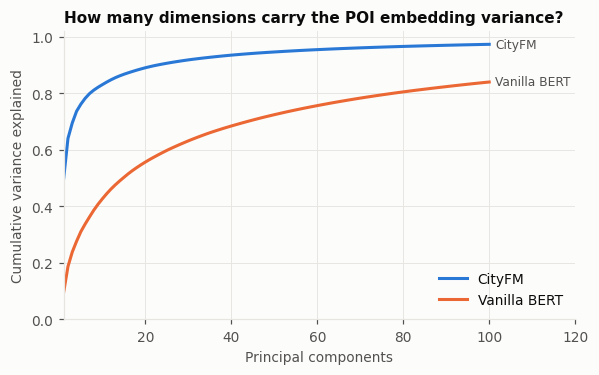

,mean cosine (random pairs),participation ratio,PCs for 90% variance
CityFM,0.81,3.63,23.000000
Vanilla BERT,0.76,34.98,156.000000


In [15]:
rng = np.random.default_rng(SEED)
a, b = rng.integers(0, len(poi), (2, 50_000))
keep = a != b

fig, ax = plt.subplots(figsize=(6, 3.4))
summary = {}
for name, z in Z.items():
    ev = PCA().fit(E[name]).explained_variance_
    cum = np.cumsum(ev) / ev.sum()
    summary[name] = {'mean cosine (random pairs)': (z[a[keep]] * z[b[keep]]).sum(1).mean(),
                     'participation ratio': ev.sum() ** 2 / (ev ** 2).sum(),
                     'PCs for 90% variance': int(np.searchsorted(cum, 0.9) + 1)}
    ax.plot(np.arange(1, 101), cum[:100], color=MODEL_COLOURS[name], lw=2, label=name)
    ax.annotate(name, (100, cum[99]), xytext=(4, 0), textcoords='offset points',
                va='center', color=INK2, fontsize=8)
ax.set(xlabel='Principal components', ylabel='Cumulative variance explained', ylim=(0, 1.02), xlim=(1, 120))
ax.set_title('How many dimensions carry the POI embedding variance?', loc='left')
ax.legend(loc='lower right')
plt.show()
pd.DataFrame(summary).T.style.format('{:.2f}', subset=['mean cosine (random pairs)', 'participation ratio'])

## 4. Visualising the POI embedding space

UMAP (cosine metric) reduces the embeddings to 2-D. The first plot colours points by top-level key. The small multiples then highlight one category at a time, since sixteen colours on one scatter would be unreadable.

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


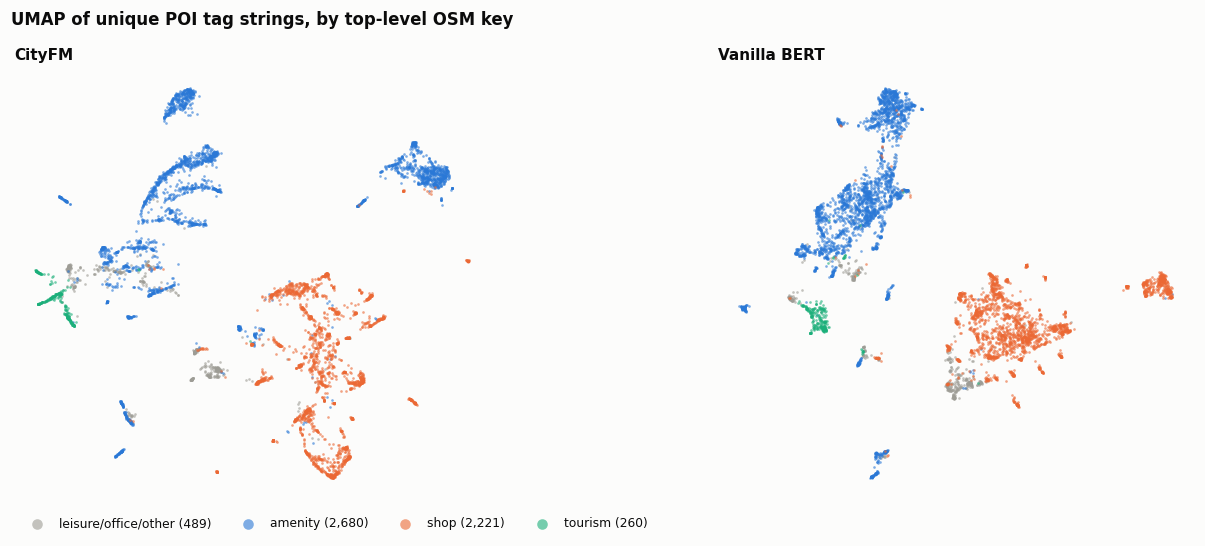

In [16]:
reducer_kw = dict(n_neighbors=30, min_dist=0.1, metric='cosine', random_state=SEED)
U = {name: umap.UMAP(**reducer_kw).fit_transform(z) for name, z in Z.items()}

KEY_COLOURS = {'amenity': BLUE, 'shop': ORANGE, 'tourism': AQUA}
group = poi.key.where(poi.key.isin(KEY_COLOURS), 'other')

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, u) in zip(axes, U.items()):
    for g, colour in [('other', OTHER), *KEY_COLOURS.items()]:
        m = (group == g).values
        ax.scatter(u[m, 0], u[m, 1], s=3, color=colour, alpha=0.6, lw=0,
                   label=f'{g} ({m.sum():,})' if g != 'other' else f'leisure/office/other ({m.sum():,})')
    ax.set_title(name, loc='left'); clean_axes(ax)
axes[0].legend(loc='upper left', bbox_to_anchor=(0, -0.02), ncol=4, markerscale=4, fontsize=8)
fig.suptitle('UMAP of unique POI tag strings, by top-level OSM key', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

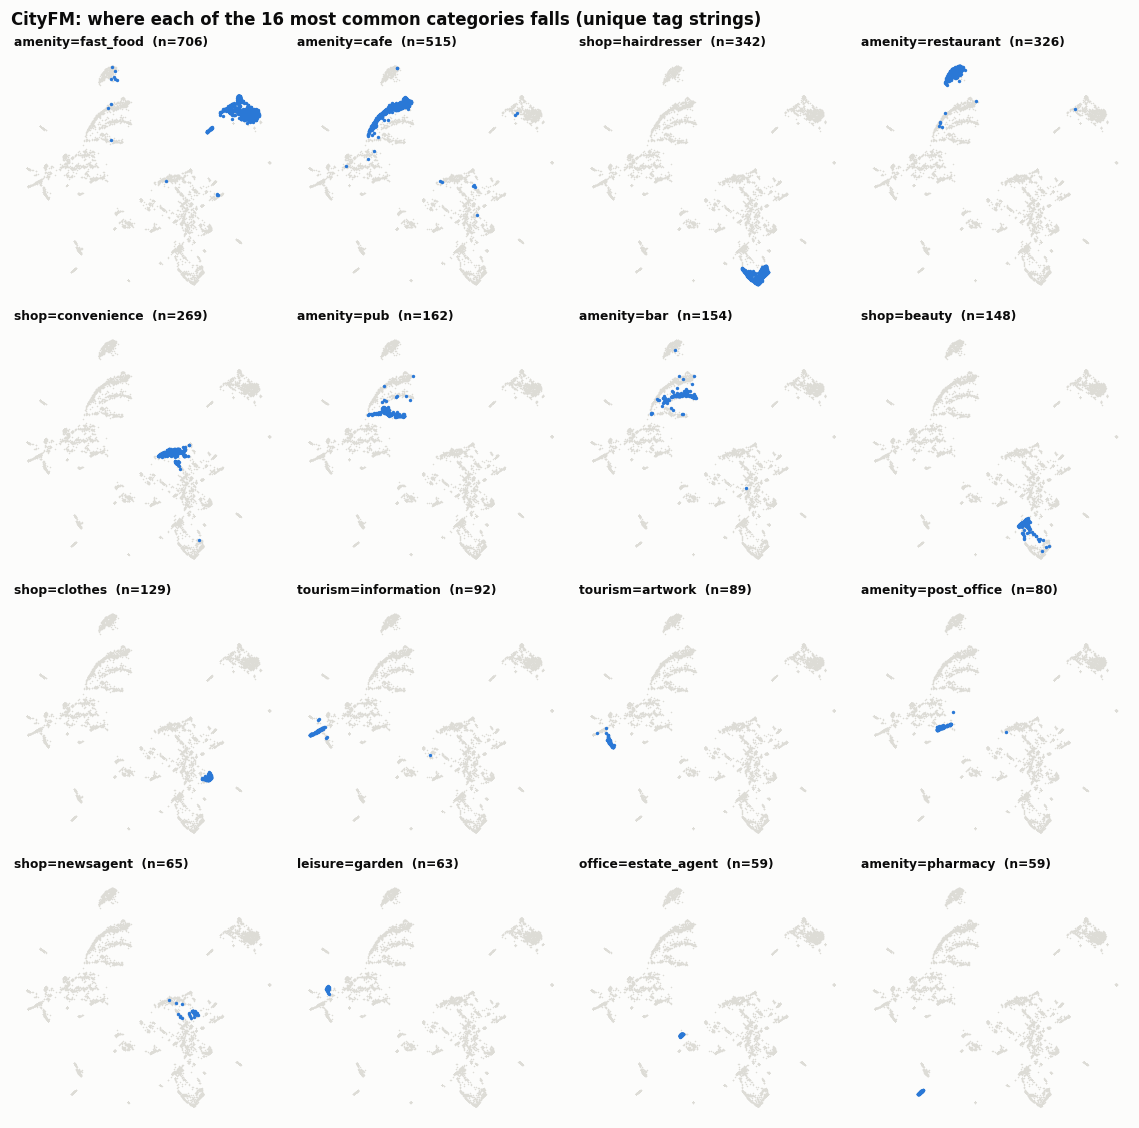

In [17]:
def small_multiples(u, labels, cats, title, ncols=4, size=2.6):
    nrows = int(np.ceil(len(cats) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    for ax, c in zip(axes.flat, cats):
        m = (labels == c)
        ax.scatter(u[:, 0], u[:, 1], s=1, color=CONTEXT, lw=0)
        ax.scatter(u[m, 0], u[m, 1], s=5, color=BLUE, lw=0)
        ax.set_title(f'{c}  (n={m.sum()})', loc='left', fontsize=8); clean_axes(ax)
    for ax in axes.flat[len(cats):]:
        ax.axis('off')
    fig.suptitle(title, x=0.01, ha='left', fontweight='bold')
    plt.tight_layout(); plt.show()

TOP_CATS = poi.category.value_counts().index[:16].tolist()
small_multiples(U['CityFM'], poi.category.values, TOP_CATS,
                'CityFM: where each of the 16 most common categories falls (unique tag strings)')

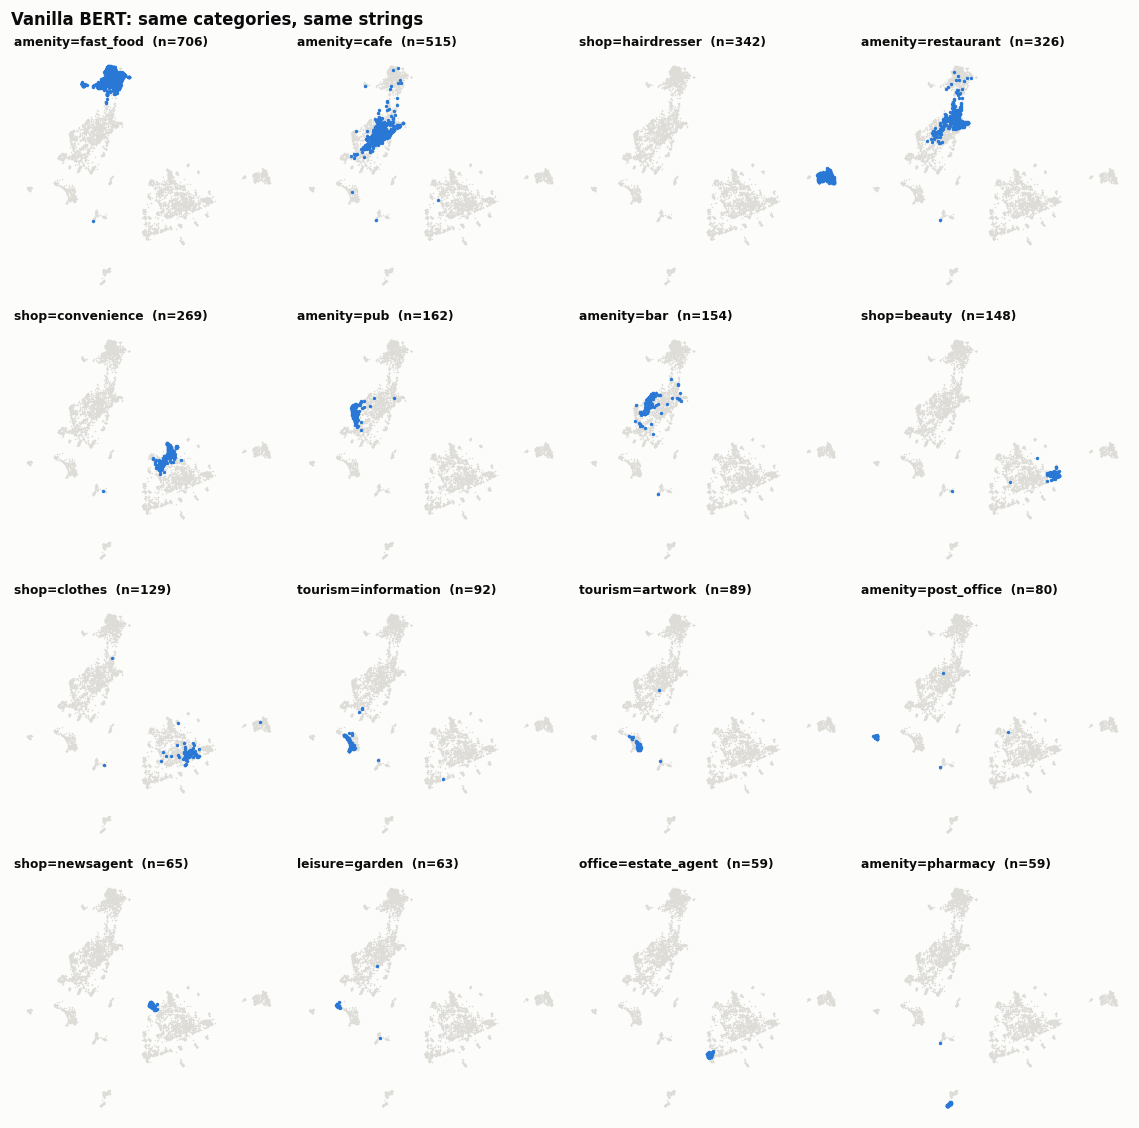

In [18]:
# Same view for the baseline, to see whether CityFM training changes the layout.
small_multiples(U['Vanilla BERT'], poi.category.values, TOP_CATS,
                'Vanilla BERT: same categories, same strings')

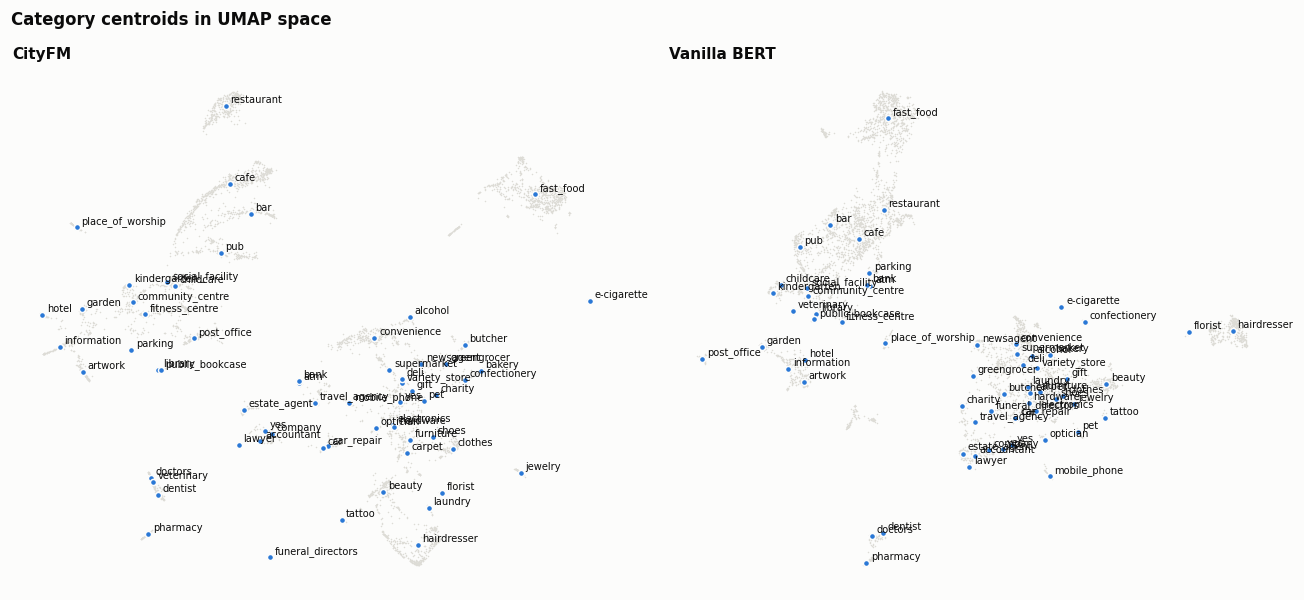

In [19]:
# A labelled map of the space: each category's median UMAP position (categories with >= 15 unique strings).
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
big = poi.category.value_counts()
big = big[big >= 15].index
for ax, (name, u) in zip(axes, U.items()):
    ax.scatter(u[:, 0], u[:, 1], s=1, color=CONTEXT, lw=0)
    for c in big:
        x, y = np.median(u[(poi.category == c).values], axis=0)
        ax.plot(x, y, 'o', ms=4, color=BLUE, mec=SURFACE, mew=1)
        ax.annotate(c.split('=')[1], (x, y), xytext=(3, 2), textcoords='offset points', fontsize=6.5, color=INK)
    ax.set_title(name, loc='left'); clean_axes(ax)
fig.suptitle('Category centroids in UMAP space', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

## 5. Quantitative checks

### 5a. Same-category vs different-category similarity

Random pairs of unique POI strings are drawn from categories with ≥ 20 unique strings. The **AUC** is the probability that a random same-category pair is more similar than a random different-category pair. It is rank-based, so the two models can be compared despite their different anisotropy. 0.5 means no category signal and 1.0 means perfect separation.

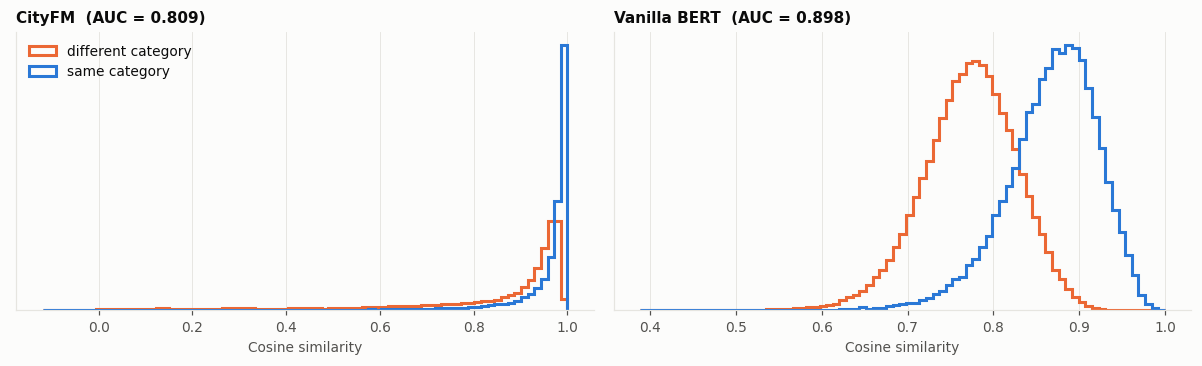

48 categories, 80,975 same / 187,086 different pairs


,AUC same>different,"mean cos, same category","mean cos, different category"
CityFM,0.809,0.956,0.826
Vanilla BERT,0.898,0.868,0.772


In [20]:
counts = poi.category.value_counts()
ELIGIBLE = counts[counts >= 20].index
elig = poi.category.isin(ELIGIBLE).values
idx = np.flatnonzero(elig)
lab = poi.category.values

rng = np.random.default_rng(SEED)
pa, pb = rng.choice(idx, 200_000), rng.choice(idx, 200_000)
# Top up with explicitly same-category pairs so both distributions are well populated.
same_a, same_b = [], []
for c in ELIGIBLE:
    members = np.flatnonzero(lab == c)
    k = min(2_000, len(members) ** 2)
    same_a.append(rng.choice(members, k)); same_b.append(rng.choice(members, k))
pa = np.concatenate([pa, *same_a]); pb = np.concatenate([pb, *same_b])
ok = pa != pb
pa, pb = pa[ok], pb[ok]
same = lab[pa] == lab[pb]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
res = {}
for ax, (name, z) in zip(axes, Z.items()):
    cos = (z[pa] * z[pb]).sum(1)
    res[name] = {'AUC same>different': roc_auc_score(same, cos),
                 'mean cos, same category': cos[same].mean(),
                 'mean cos, different category': cos[~same].mean()}
    bins = np.linspace(cos.min(), 1, 80)
    ax.hist(cos[~same], bins, density=True, histtype='step', lw=2, color=ORANGE, label='different category')
    ax.hist(cos[same], bins, density=True, histtype='step', lw=2, color=BLUE, label='same category')
    ax.set_title(f"{name}  (AUC = {res[name]['AUC same>different']:.3f})", loc='left')
    ax.set_xlabel('Cosine similarity'); ax.set_yticks([])
axes[0].legend(loc='upper left')
plt.tight_layout(); plt.show()
print(f'{len(ELIGIBLE)} categories, {same.sum():,} same / {(~same).sum():,} different pairs')
pd.DataFrame(res).T.round(3)

### 5b. Category × category similarity

Each cell is the mean cosine similarity between POIs of two categories, computed as the dot product of mean unit vectors. The diagonal is within-category cohesion. Rows are ordered by hierarchical clustering on the CityFM matrix, and each panel has its own colour scale because the anisotropy differs.

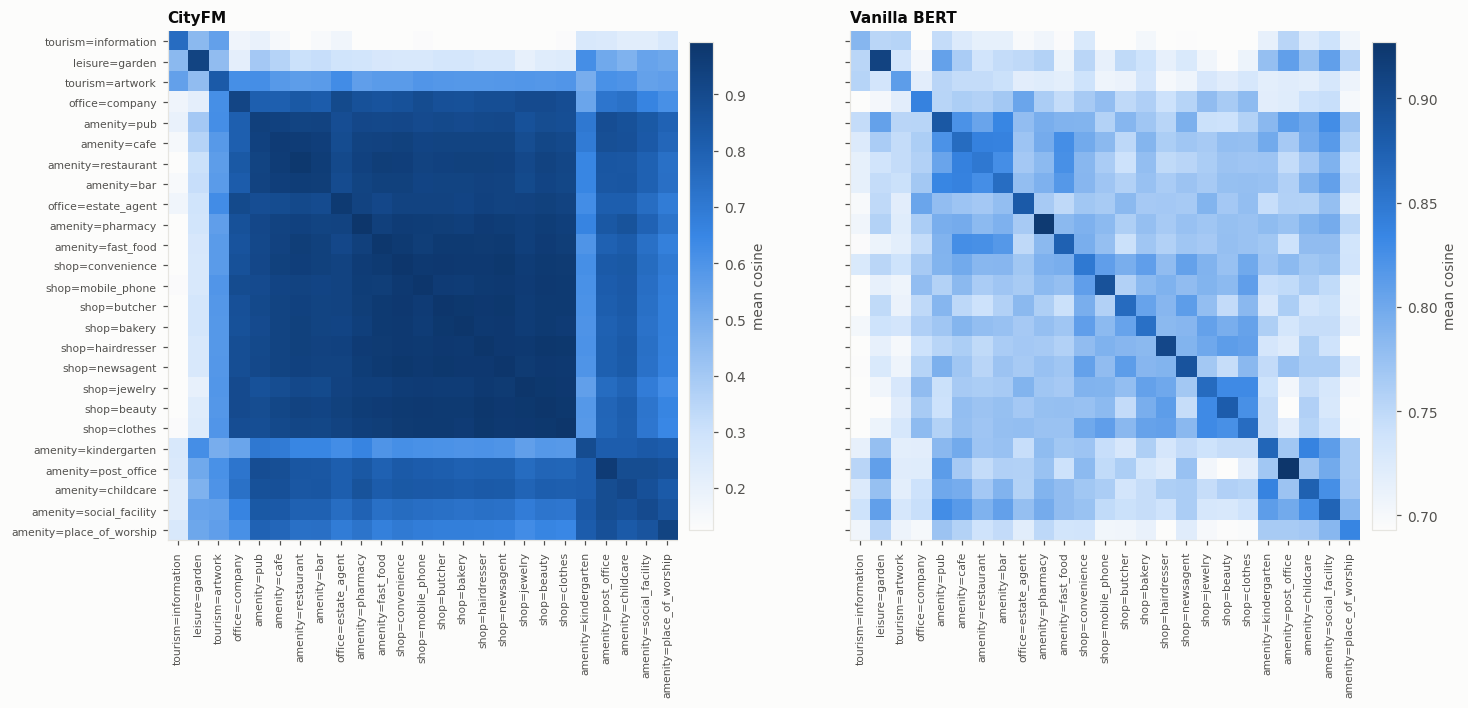

In [21]:
HEAT_CATS = counts.index[:25].tolist()

def category_sim(z, cats, labels):
    C = np.stack([z[labels == c].mean(0) for c in cats])
    return C @ C.T

S = {name: category_sim(z, HEAT_CATS, lab) for name, z in Z.items()}
order = leaves_list(linkage(S['CityFM'], 'average'))
names_ord = [HEAT_CATS[i] for i in order]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.3))
for ax, (name, s) in zip(axes, S.items()):
    s = s[np.ix_(order, order)]
    im = ax.imshow(s, cmap=BLUES, vmin=np.percentile(s, 2), vmax=s.max())
    ax.set_xticks(range(len(order))); ax.set_xticklabels(names_ord, rotation=90, fontsize=7)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(names_ord if ax is axes[0] else [], fontsize=7)
    ax.grid(False); ax.set_title(name, loc='left')
    plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label='mean cosine')
plt.tight_layout(); plt.show()

### 5c. k-nearest-neighbour category prediction

This is leave-one-out kNN classification (k = 10, cosine distance) on unique tag strings from the eligible categories. Each POI is labelled by majority vote of its neighbours. Accuracy is compared against always predicting the most common class. Macro accuracy averages over categories, so it is not dominated by the largest ones.

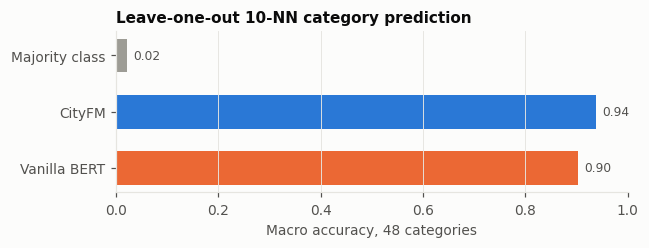

,accuracy,macro accuracy
Majority class,0.161,0.021
CityFM,0.964,0.938
Vanilla BERT,0.933,0.902


In [22]:
def knn_predict(X, labels, k=10, metric='cosine'):
    _, nbr = NearestNeighbors(n_neighbors=k + 1, metric=metric).fit(X).kneighbors(X)
    preds = []
    for i, row in enumerate(nbr):
        row = [j for j in row if j != i][:k]
        preds.append(collections.Counter(labels[row]).most_common(1)[0][0])
    return np.array(preds)

def accuracy(preds, labels):
    return {'accuracy': (preds == labels).mean(),
            'macro accuracy': np.mean([(preds[labels == c] == c).mean() for c in np.unique(labels)])}

y = lab[elig]
knn = {'Majority class': accuracy(np.full(len(y), pd.Series(y).mode()[0]), y)}
for name, z in Z.items():
    knn[name] = accuracy(knn_predict(z[elig], y), y)
knn = pd.DataFrame(knn).T

fig, ax = plt.subplots(figsize=(6, 1.9))
colours = [OTHER] + [MODEL_COLOURS[n] for n in knn.index[1:]]
ax.barh(knn.index, knn['macro accuracy'], color=colours, height=0.6)
for i, v in enumerate(knn['macro accuracy']):
    ax.annotate(f'{v:.2f}', (v, i), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8, color=INK2)
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel(f'Macro accuracy, {len(ELIGIBLE)} categories')
ax.set_title('Leave-one-out 10-NN category prediction', loc='left'); ax.grid(axis='y', visible=False)
plt.show()
knn.round(3)

### 5d. Nearest-neighbour queries

`poi_neighbours` accepts a row of `poi`, a name substring, or a category, and lists the nearest unique POIs under both models, with the straight-line distance to each. Try your own queries.

In [23]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(h))

def find_poi(query):
    if isinstance(query, (int, np.integer)):
        return int(query)
    if '=' in query:
        hits = poi.index[(poi.category == query) & poi.name.notna()]
    else:
        hits = poi.index[poi.name.fillna('').str.contains(query, case=False)]
    if len(hits) == 0:
        raise ValueError(f'no POI matches {query!r}')
    return int(hits[0])

def poi_neighbours(query, k=8):
    i = find_poi(query)
    q = poi.loc[i]
    print(f"Query: {q['name']!r}  [{q.category}]  text = {q.text!r}")
    tables = []
    for name, z in Z.items():
        sims = z @ z[i]
        sims[i] = -np.inf
        top = np.argsort(-sims)[:k]
        t = poi.loc[top, ['name', 'category']].copy()
        t['cos'] = sims[top].round(3)
        t['km'] = haversine_km(q.lat, q.lon, poi.lat.values[top], poi.lon.values[top]).round(1)
        t.columns = pd.MultiIndex.from_product([[name], t.columns])
        tables.append(t.reset_index(drop=True))
    return pd.concat(tables, axis=1)

poi_neighbours('amenity=pub')

Query: 'Harewood Arms Hotel'  [amenity=pub]  text = 'name: Harewood Arms Hotel, amenity: pub, tourism: hostel'


CityFM                                    \
                                    name             category    cos    km   
0                          The Royal Oak          amenity=pub  0.955   9.0   
1         Cross Flatts Recreational Club          amenity=pub  0.940  14.9   
2                               The Well  amenity=disused_pub  0.932  11.5   
3  Chapel Allerton Snooker & Social Club          amenity=bar  0.932   8.2   
4                 Headingley Lodge Hotel        tourism=hotel  0.924  10.4   
5                      Bridge Farm Hotel        tourism=hotel  0.922  16.4   
6                  Garforth Country Club          amenity=pub  0.921  14.3   
7        East & West Ardsley Social Club          amenity=pub  0.920  19.5   

             Vanilla BERT                            
                     name     category    cos    km  
0           The Royal Oak  amenity=pub  0.937   9.0  
1           Moorhouse Inn  amenity=pub  0.936  13.5  
2          Pack Horse Inn  amenity=pub  0.932  11.7  
3              Tetley Pub  amenity=pub  0.930  12.3  
4            Otley Tavern  amenity=pub  0.929  11.9  
5           Cardigan Arms  amenity=pub  0.926  11.5  
6          The Smithfield  amenity=pub  0.925  11.2  
7  Harehills Liberal Club  amenity=pub  0.924  10.2

In [24]:
poi_neighbours('shop=hairdresser')

Query: 'Renegade'  [shop=hairdresser]  text = 'name: Renegade, shop: hairdresser'


CityFM                                Vanilla BERT                    \
      name          category    cos    km         name          category   
0   Unique  shop=hairdresser  0.999  17.7  Renaissance  shop=hairdresser   
1      Red  shop=hairdresser  0.998  11.4       Unique  shop=hairdresser   
2     envy  shop=hairdresser  0.998   5.2        unity  shop=hairdresser   
3    unity  shop=hairdresser  0.998  14.5      Rapport  shop=hairdresser   
4     Hive  shop=hairdresser  0.998   0.7         envy  shop=hairdresser   
5  Rapport  shop=hairdresser  0.998   5.2          Red  shop=hairdresser   
6   ISalon  shop=hairdresser  0.998   0.4          Ash  shop=hairdresser   
7    Amour  shop=hairdresser  0.998   5.4         Hive  shop=hairdresser   

                
     cos    km  
0  0.968   0.3  
1  0.966  17.7  
2  0.964  14.5  
3  0.964   5.2  
4  0.962   5.2  
5  0.962  11.4  
6  0.961   5.1  
7  0.957   0.7

In [25]:
poi_neighbours('amenity=pharmacy')

Query: 'Everest Pharmacy'  [amenity=pharmacy]  text = 'name: Everest Pharmacy, amenity: pharmacy, healthcare: pharmacy'


CityFM                                        Vanilla BERT  \
                  name          category    cos    km                 name   
0      Alsyed Pharmacy  amenity=pharmacy  0.998   7.8     Knights Pharmacy   
1       Imaan Pharmacy  amenity=pharmacy  0.998   7.6         Sky Pharmacy   
2    Naseems' Pharmacy  amenity=pharmacy  0.998  12.1       Imaan Pharmacy   
3        Khan Pharmacy  amenity=pharmacy  0.998   6.9        Well Pharmacy   
4     Kamsons Pharmacy  amenity=pharmacy  0.998   9.2        Khan Pharmacy   
5    Medichem Pharmacy  amenity=pharmacy  0.998   6.3  Livingcare Pharmacy   
6         Sky Pharmacy  amenity=pharmacy  0.998   7.2        Pool Pharmacy   
7  Livingcare Pharmacy  amenity=pharmacy  0.998   7.2    Roundhay Pharmacy   

                                  
           category    cos    km  
0  amenity=pharmacy  0.958   5.5  
1  amenity=pharmacy  0.958   7.2  
2  amenity=pharmacy  0.955   7.6  
3  amenity=pharmacy  0.952   3.1  
4  amenity=pharmacy  0.951   6.9  
5  amenity=pharmacy  0.951   7.2  
6  amenity=pharmacy  0.945  10.0  
7  amenity=pharmacy  0.945   7.1

In [26]:
poi_neighbours('tourism=museum')

Query: 'Abbey House Museum'  [tourism=museum]  text = 'name: Abbey House Museum, tourism: museum'


CityFM                                   \
                       name            category    cos    km   
0          Horsforth Museum      tourism=museum  0.935   2.9   
1              Otley Museum      tourism=museum  0.898  10.6   
2  The Ron Kitching Library      tourism=museum  0.851  10.6   
3   Colton Medieval Village      tourism=museum  0.840  11.2   
4            Lotherton Hall  tourism=attraction  0.833  18.9   
5             The Home Farm  tourism=attraction  0.822  10.6   
6  Yorkshire Cricket Museum      tourism=museum  0.819   1.8   
7             Bramley Henge  tourism=attraction  0.812   1.2   

              Vanilla BERT                                   
                      name            category    cos    km  
0             Otley Museum      tourism=museum  0.925  10.6  
1         Horsforth Museum      tourism=museum  0.917   2.9  
2           Briggate Hotel       tourism=hotel  0.897   5.2  
3        Bridge Farm Hotel       tourism=hotel  0.895  13.2  
4            The Home Farm  tourism=attraction  0.889  10.6  
5        Oulton Hall Hotel       tourism=hotel  0.886  13.0  
6  Colton Medieval Village      tourism=museum  0.884  11.2  
7           Lotherton Hall  tourism=attraction  0.881  18.9

In [27]:
poi_neighbours('Greggs')

Query: 'Greggs'  [amenity=fast_food]  text = 'name: Greggs, amenity: fast food'


CityFM                                 Vanilla BERT                     \
        name           category    cos    km         name           category   
0   Silver's  amenity=fast_food  0.998   2.2     Silver's  amenity=fast_food   
1    Kirby's  amenity=fast_food  0.998   7.4    Allison's  amenity=fast_food   
2      Zak's  amenity=fast_food  0.998   6.4      Wendy's  amenity=fast_food   
3  Delifresh  amenity=fast_food  0.998  24.4       Greggs  amenity=fast_food   
4     Sullys  amenity=fast_food  0.998   6.4     Bennetts  amenity=fast_food   
5  Hartley's  amenity=fast_food  0.998   4.2      Sammy's  amenity=fast_food   
6    Fritz's  amenity=fast_food  0.998  10.8      Fritz's  amenity=fast_food   
7     Maxi's  amenity=fast_food  0.998   6.4    Hartley's  amenity=fast_food   

                
     cos    km  
0  0.965   2.2  
1  0.964   6.3  
2  0.956   8.0  
3  0.955   7.5  
4  0.953   1.1  
5  0.953  12.3  
6  0.952  10.8  
7  0.949   4.2

**Free-text queries.** Any string can be pushed through the CityFM text encoder with `embed_text`, like `utils.properties.topic_search`. Strings phrased like the training data (`key: value`) are closest to what the model saw during training. Tags outside `use_tags`, such as `cuisine`, never appeared in training.

In [28]:
def text_query(s, k=10):
    q = embed_text(s)
    sims = Z['CityFM'] @ (q / np.linalg.norm(q))
    top = np.argsort(-sims)[:k]
    t = poi.loc[top, ['name', 'category', 'text']].copy()
    t.insert(0, 'cos', sims[top].round(3))
    return t.reset_index(drop=True)

for s in ['amenity: nightclub', 'student accommodation', 'amenity: place of worship, name: mosque']:
    print(f'\n### {s}')
    display(text_query(s, 6))


### amenity: nightclub


,cos,name,category,text
0,0.944,Project House,amenity=nightclub,"name: Project House, amenity: nightclub"
1,0.938,Tuesday Club,amenity=events_venue,"name: Tuesday Club, amenity: events venue"
2,0.930,The Key Club,amenity=nightclub,"name: The Key Club, amenity: nightclub"
3,0.921,Space,amenity=nightclub,"name: Space, amenity: nightclub"
4,0.920,The HiFi Club,amenity=nightclub,"name: The HiFi Club, amenity: nightclub"
5,0.920,Q360 Lounge,amenity=hookah_lounge,"name: Q360 Lounge, amenity: hookah lounge, sport: billiards"



### student accommodation


,cos,name,category,text
0,0.629,Gledhow Lodge Residential Home,amenity=social_facility,"name: Gledhow Lodge Residential Home, amenity: social fa..."
1,0.608,None,tourism=hotel,tourism: hotel
2,0.599,None,leisure=swimming_pool,leisure: swimming pool
3,0.596,None,leisure=sports_centre,leisure: sports centre
4,0.593,Art Hostel,tourism=hostel,"name: Art Hostel, tourism: hostel"
5,0.578,St John's Hostel,tourism=hostel,"name: St Johns Hostel, tourism: hostel"



### amenity: place of worship, name: mosque


,cos,name,category,text
0,0.982,Lincoln Green Mosque,amenity=place_of_worship,"name: Lincoln Green Mosque, amenity: place of worship"
1,0.980,Al Madina Jamia Mosque,amenity=place_of_worship,"name: Al Madina Jamia Mosque, amenity: place of worship"
2,0.977,Al Madina Jam-e Masjid,amenity=place_of_worship,"name: Al Madina Jam-e Masjid, amenity: place of worship"
3,0.974,Al-Towbah Islamic Centre,amenity=place_of_worship,"name: Al-Towbah Islamic Centre, amenity: place of worship"
4,0.968,Al-Rahmah Faith Centre,amenity=place_of_worship,"name: Al-Rahmah Faith Centre, amenity: place of worship"
5,0.965,Gospel Hall,amenity=place_of_worship,"name: Gospel Hall, amenity: place of worship"


### 5e. Did training inject spatial co-occurrence?

This is the most direct test of objective (1). If the context-alignment training worked, category pairs that **appear near each other in Leeds** should be more similar under CityFM than under untuned BERT.

* **Co-occurrence**: for categories with ≥ 30 POI nodes, count pairs of POIs within 100 m of each other (`config.context_d` = 100). Then compute the log₂ lift over what random labelling of the same POI locations would give.
* **Similarity**: category centroids of the *name-stripped* embeddings, so the comparison is about the category tags, not shop names.
* The score is the Spearman correlation between the two, over all off-diagonal category pairs.

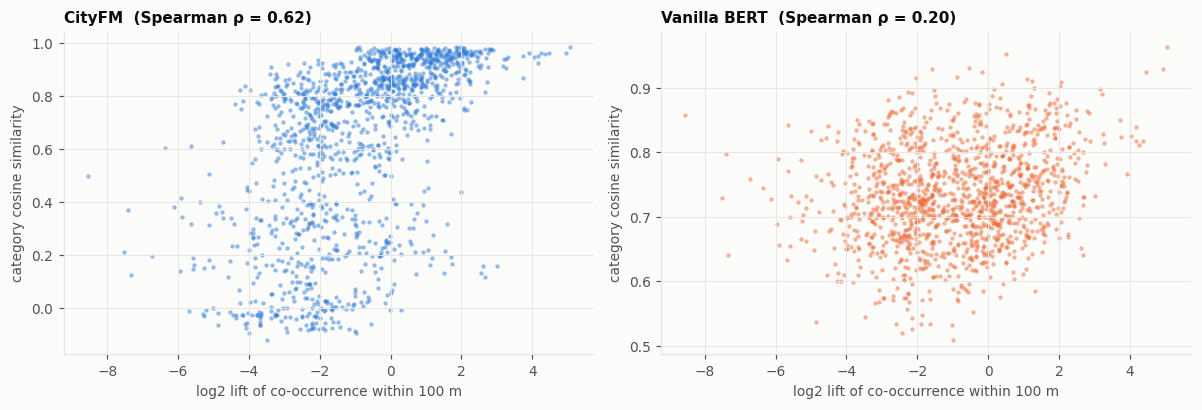

52 categories, 1326 category pairs


,Spearman rho,p
CityFM,0.618715,6.413147e-141
Vanilla BERT,0.200816,1.571089e-13


In [29]:
R_M = config.context_d
co_cats = nodes.category.value_counts()
co_cats = co_cats[co_cats >= 30].index.tolist()
cidx = {c: i for i, c in enumerate(co_cats)}
node_lab = nodes.category.map(cidx).fillna(-1).astype(int).values

tree = BallTree(np.radians(nodes[['lat', 'lon']].values), metric='haversine')
nbrs = tree.query_radius(np.radians(nodes[['lat', 'lon']].values), r=R_M / 6_371_000)
C = np.zeros((len(co_cats), len(co_cats)))
for i, js in enumerate(nbrs):
    if node_lab[i] < 0:
        continue
    lj = node_lab[js[js != i]]
    np.add.at(C[node_lab[i]], lj[lj >= 0], 1)
n_c = np.bincount(node_lab[node_lab >= 0], minlength=len(co_cats)).astype(float)
expected = np.outer(n_c, n_c) * C.sum() / n_c.sum() ** 2
lift = np.log2((C + 1) / (expected + 1))

# Name-stripped category centroids, for CityFM and for BERT (BERT on the same name-stripped strings).
bert_nn = cached('poi_bert_noname', noname.id,
                 lambda: encode_vanilla_bert([without_name(entities[i]) for i in noname.id]))
Zn = {'CityFM': l2(E_noname), 'Vanilla BERT': l2(bert_nn[poi.text_noname.map(nn_row).values])}
iu = np.triu_indices(len(co_cats), 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
rho = {}
for ax, (name, z) in zip(axes, Zn.items()):
    sim = category_sim(z, co_cats, lab)
    r, p = spearmanr(lift[iu], sim[iu])
    rho[name] = {'Spearman rho': r, 'p': p}
    ax.scatter(lift[iu], sim[iu], s=8, color=MODEL_COLOURS[name], alpha=0.5, lw=0)
    ax.set(xlabel=f'log2 lift of co-occurrence within {R_M} m', ylabel='category cosine similarity')
    ax.set_title(f'{name}  (Spearman ρ = {r:.2f})', loc='left')
plt.tight_layout(); plt.show()
print(f'{len(co_cats)} categories, {len(iu[0])} category pairs')
pd.DataFrame(rho).T

In [30]:
# Which category pairs did training move the most? The change in rank similarity (CityFM minus BERT)
# is compared with how often the pair co-occurs.
def rank01(x):
    return pd.Series(x).rank(pct=True).values

sim_c = category_sim(Zn['CityFM'], co_cats, lab)[iu]
sim_b = category_sim(Zn['Vanilla BERT'], co_cats, lab)[iu]
moved = pd.DataFrame({'a': np.array(co_cats)[iu[0]], 'b': np.array(co_cats)[iu[1]],
                      'lift': lift[iu], 'rank CityFM': rank01(sim_c), 'rank BERT': rank01(sim_b)})
moved['shift'] = moved['rank CityFM'] - moved['rank BERT']
print('Pulled together by training:'); display(moved.nlargest(10, 'shift').round(2))
print('Pushed apart by training:');    display(moved.nsmallest(10, 'shift').round(2))

Pulled together by training:


,a,b,lift,rank CityFM,rank BERT,shift
248,shop=hairdresser,amenity=atm,0.33,0.88,0.02,0.86
452,amenity=atm,shop=optician,1.07,0.85,0.06,0.79
256,shop=hairdresser,amenity=pharmacy,-0.16,0.91,0.14,0.77
436,amenity=atm,shop=charity,1.32,0.79,0.02,0.76
696,shop=vacant,amenity=pharmacy,-0.55,0.85,0.09,0.76
425,amenity=atm,shop=beauty,0.74,0.87,0.12,0.76
434,amenity=atm,shop=newsagent,-1.11,0.84,0.11,0.73
54,amenity=fast_food,shop=hairdresser,0.27,0.92,0.18,0.73
932,shop=charity,amenity=vending_machine,-3.19,0.74,0.01,0.72
1174,shop=gift,amenity=vending_machine,-2.90,0.82,0.10,0.72


Pushed apart by training:


,a,b,lift,rank CityFM,rank BERT,shift
788,leisure=garden,shop=supermarket,-3.66,0.05,0.92,-0.87
57,amenity=fast_food,amenity=parking,-2.75,0.09,0.96,-0.87
346,shop=convenience,leisure=garden,-4.52,0.05,0.91,-0.86
777,leisure=garden,shop=bakery,-2.94,0.06,0.92,-0.86
417,amenity=parking,amenity=bank,-2.14,0.11,0.95,-0.84
106,amenity=cafe,amenity=parking,-2.52,0.15,0.98,-0.84
382,amenity=parking,amenity=bar,-2.81,0.16,0.94,-0.78
792,leisure=garden,amenity=bank,-2.35,0.10,0.89,-0.78
770,leisure=garden,shop=jewelry,-4.10,0.02,0.80,-0.78
794,leisure=garden,shop=shoes,-3.27,0.04,0.80,-0.76


## 6. Buildings

88% of Leeds building polygons are `building=house`, and most have no other kept tag. Their **text** embedding is therefore the single vector for `"building: house"`. The interesting part is the **visual** embedding (footprint shape + area) and how well it aligns with the text embedding, which is objective (2).

The sample is stratified: up to 300 polygons from each of the 18 most common classes. A polygon's class is its primary category if it has one, otherwise its `building=` value. `building=yes` is excluded because it carries no label.

In [31]:
PER_CLASS, N_CLASSES = 300, 18
polys['cls'] = polys.category.fillna('building=' + polys.building.fillna('?'))
cls_counts = polys.cls.value_counts().drop(['building=yes', 'building=?'], errors='ignore')
CLASSES = cls_counts.index[:N_CLASSES].tolist()

bld = (polys[polys.cls.isin(CLASSES)]
       .groupby('cls', group_keys=False)
       .apply(lambda g: g.sample(min(len(g), PER_CLASS), random_state=SEED)))
bld = bld[[rasterisable(i) for i in bld.id]].reset_index(drop=True)

def encode_buildings():
    _, text, vis = encode_polygons(CITY, [entities[i] for i in bld.id])
    return np.concatenate([text.numpy(), vis.numpy()], axis=1)

tv = cached('buildings_text_visual', bld.id, encode_buildings)
B_text, B_vis = tv[:, :768], tv[:, 768:]
Bt, Bv = l2(B_text), l2(B_vis)
print(f'{len(bld):,} buildings in {len(CLASSES)} classes; {bld.text.nunique():,} unique text strings')
bld.cls.value_counts().to_frame('n').T

5,269 buildings in 18 classes; 1,364 unique text strings


,building=semidetached_house,building=school,amenity=place_of_worship,amenity=pub,amenity=school,building=apartments,building=bungalow,building=commercial,building=detached,amenity=parking,building=farm_auxiliary,building=garages,building=house,building=industrial,building=residential,building=retail,amenity=fast_food,building=farm
n,300,300,300,300,300,300,300,300,300,300,300,300,300,300,300,300,243,226


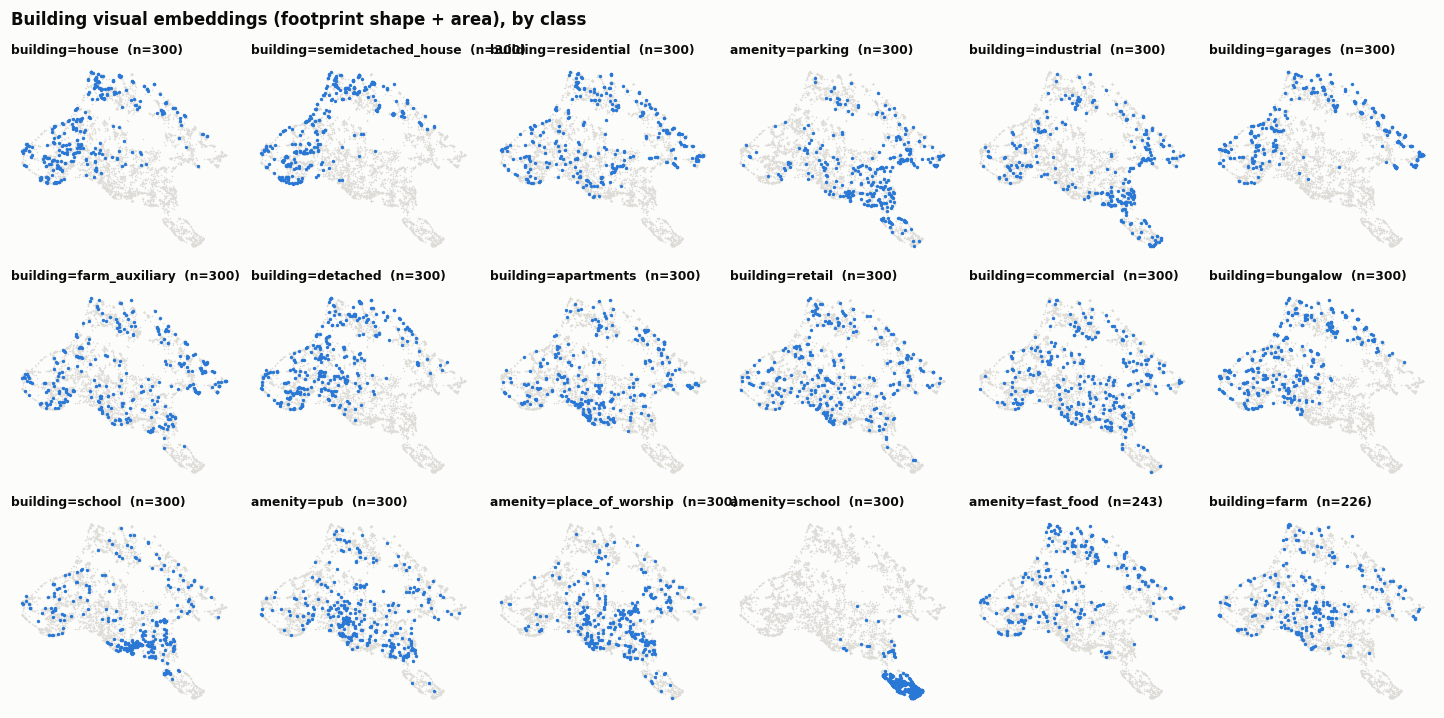

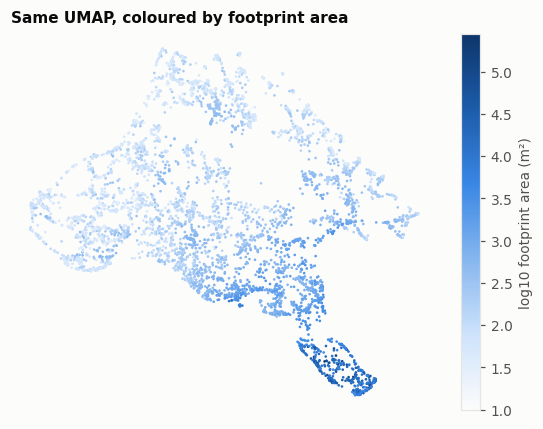

In [32]:
Ub = umap.UMAP(**reducer_kw).fit_transform(Bv)
small_multiples(Ub, bld.cls.values, CLASSES, 'Building visual embeddings (footprint shape + area), by class', ncols=6, size=2.2)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sc = ax.scatter(Ub[:, 0], Ub[:, 1], c=np.log10(bld.area), s=3, cmap=BLUES, vmin=1, lw=0)
plt.colorbar(sc, ax=ax, label='log10 footprint area (m²)', fraction=0.04)
ax.set_title('Same UMAP, coloured by footprint area', loc='left'); clean_axes(ax)
plt.show()

### 6a. How much class information is in the visual embedding?

This uses leave-one-out 10-NN on the balanced sample, so chance is about 1/18. The crucial baseline is **log-area alone**. If the visual embedding does no better than area, the ResNet shape branch adds nothing.

In [33]:
yb = bld.cls.values
bknn = pd.DataFrame({
    'Chance (balanced)': {'accuracy': 1 / len(CLASSES), 'macro accuracy': 1 / len(CLASSES)},
    'log area only': accuracy(knn_predict(np.log(bld[['area']].values), yb, metric='euclidean'), yb),
    'CityFM visual': accuracy(knn_predict(Bv, yb), yb),
}).T
bknn.round(3)

,accuracy,macro accuracy
Chance (balanced),0.056,0.056
log area only,0.193,0.193
CityFM visual,0.228,0.225


### 6b. Cross-modal alignment: can the visual embedding find its own text?

Objective (2) trained footprint (visual) and tag (text) embeddings into a shared space. As a zero-shot test, each building's **visual** embedding is assigned to the class whose **text** prototype (the mean text embedding of that class) it is most similar to. No classifier is trained here: the only question is whether the two modalities line up.

zero-shot top-1 = 0.129, top-3 = 0.277, chance top-1 = 0.056


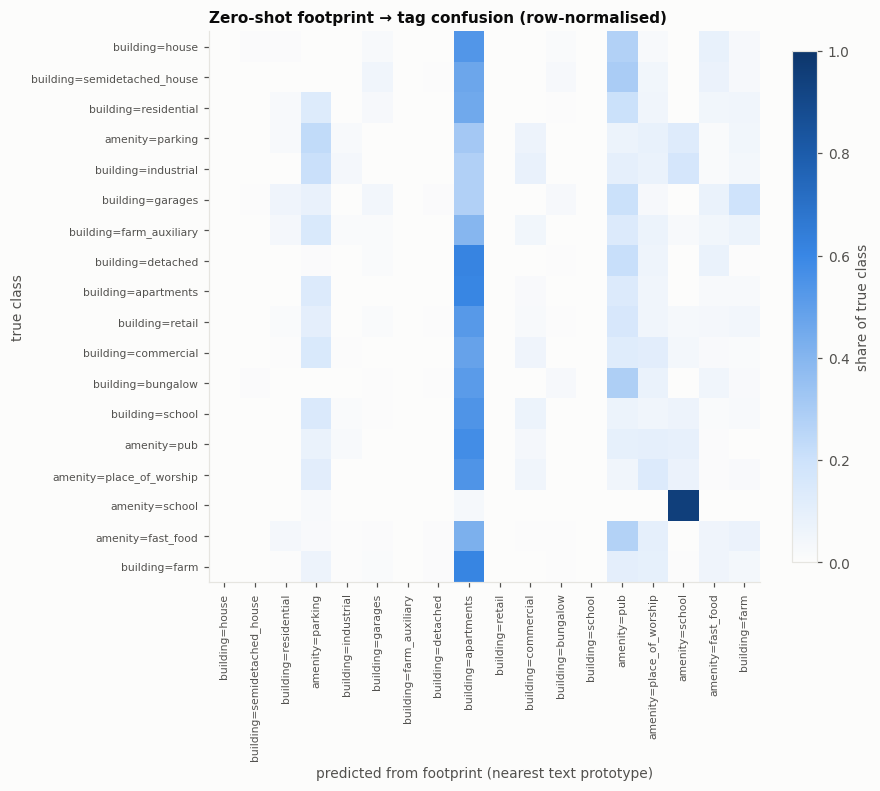

In [34]:
P = l2(np.stack([Bt[yb == c].mean(0) for c in CLASSES]))
scores = Bv @ P.T
pred = np.array(CLASSES)[scores.argmax(1)]
rank_of_true = (scores > scores[np.arange(len(yb)), [CLASSES.index(c) for c in yb]][:, None]).sum(1)
print(f'zero-shot top-1 = {(pred == yb).mean():.3f}, top-3 = {(rank_of_true < 3).mean():.3f}, '
      f'chance top-1 = {1 / len(CLASSES):.3f}')

cm = pd.crosstab(pd.Categorical(yb, CLASSES), pd.Categorical(pred, CLASSES), normalize='index', dropna=False)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm.values, cmap=BLUES, vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES, fontsize=7)
ax.set(xlabel='predicted from footprint (nearest text prototype)', ylabel='true class'); ax.grid(False)
ax.set_title('Zero-shot footprint → tag confusion (row-normalised)', loc='left')
plt.colorbar(im, ax=ax, fraction=0.04, label='share of true class')
plt.show()

### 6c. Footprint neighbours

This shows the rasterised footprint the ResNet actually sees, next to its five nearest neighbours in visual-embedding space. Rasters are rotated and scale-normalised, so absolute size shows up only in the area label.

**Pre-processing quirk.** `poly_to_raster` rotates and rasterises the footprint in raw (lat, lon) *degrees*. At Leeds's latitude one degree of longitude is about 0.59× one degree of latitude, so right-angled buildings come out as sheared parallelograms, with a skew that depends on orientation. The model was trained on the same distortion, so it is consistent, but it throws away some shape information. v2 rasterises in metres instead; **E2** shows the difference.

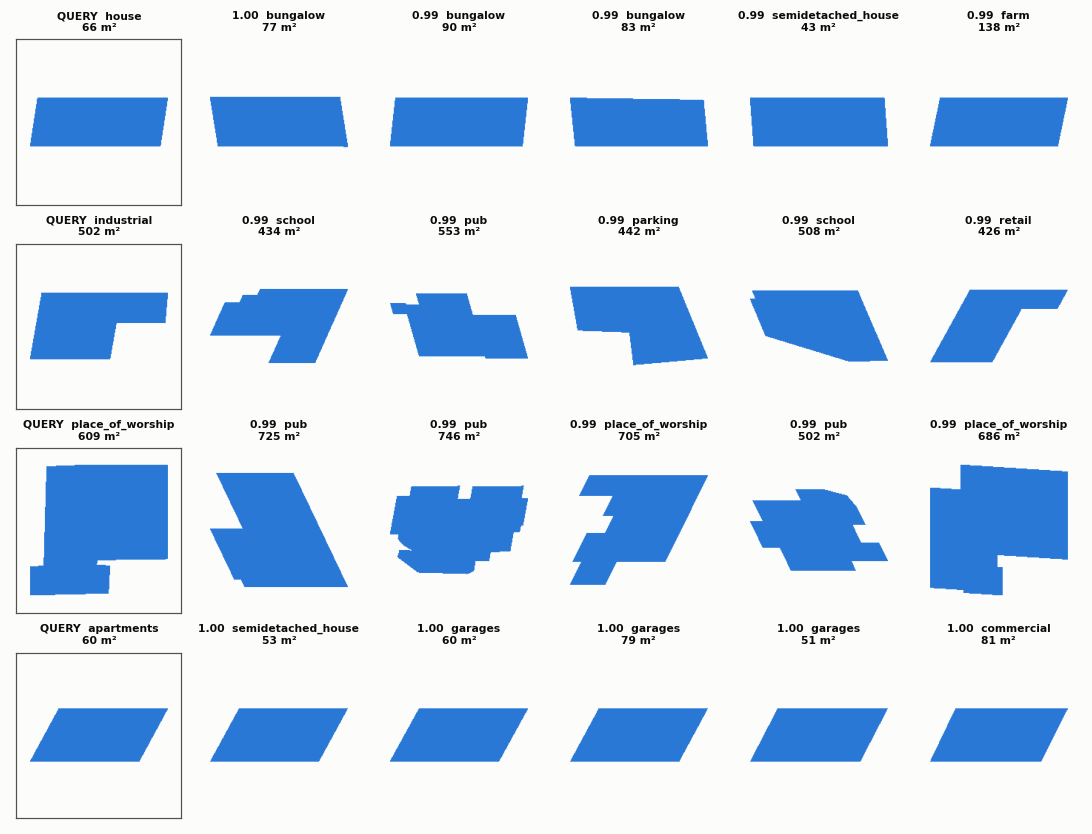

In [35]:
def footprint(i):
    return poly_to_raster(Polygon(entities[bld.id[i]]['points']))[0]

FP_CMAP = LinearSegmentedColormap.from_list('fp', [SURFACE, BLUE])
queries = [bld.index[bld.cls == c][0] for c in
           ['building=house', 'building=industrial', 'amenity=place_of_worship', 'building=apartments']
           if c in CLASSES]
fig, axes = plt.subplots(len(queries), 6, figsize=(10, 1.9 * len(queries)))
for row, qi in zip(axes, queries):
    sims = Bv @ Bv[qi]; sims[qi] = -np.inf
    for j, (ax, bi) in enumerate(zip(row, [qi, *np.argsort(-sims)[:5]])):
        ax.imshow(footprint(bi), cmap=FP_CMAP, vmin=0, vmax=1)
        label = bld.cls[bi].split('=')[1]
        ax.set_title(('QUERY  ' if j == 0 else f'{sims[bi]:.2f}  ') + f'{label}\n{bld.area[bi]:.0f} m²', fontsize=7)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(j == 0); s.set_color(INK2)
plt.tight_layout(); plt.show()

## 7. Mapping the embeddings across Leeds

The maps below show how the CityFM **POI text embeddings** vary across the region. Building embeddings are left out: §6 encoded only a small stratified sample, and nearly all houses share the single `"building: house"` text vector.

**PCA → RGB.** The 768-d embeddings are projected onto their first three principal components. Each component is converted to percentile ranks (robust to the skewed, outlier-heavy scores) and mapped to one colour channel (PC1 = red, PC2 = green, PC3 = blue). Points with similar colours have similar embeddings. The colours themselves are arbitrary, so each map comes with a key: category swatches for the point map, and the categories that drive each component for the hex map.

* **Raw points.** Every POI node is shown, using the full-string CityFM embedding (`Z['CityFM']`, unit-normalised). PCA is fitted on all nodes, so frequent categories dominate the components.
* **Hexagons.** POI embeddings are averaged within 750 m hexagons, in British National Grid metres. A **separate PCA** is then fitted on the hexagon means, so its components describe how the *mix* of POIs varies between places rather than how individual POIs differ. Hexes with fewer than `MIN_POIS` POIs are drawn as empty outlines, because their means are dominated by one or two POIs.

A POI's embedding depends only on its tags (see the top of the notebook). These maps therefore show the **spatial arrangement of what the model thinks the POIs are**, not anything it learned about location.

In [36]:
from matplotlib.collections import PolyCollection, LineCollection
from pyproj import Transformer

# Every POI node gets the embedding of its unique tag string.
row_of = pd.Series(np.arange(len(poi)), index=poi.text)
X_nodes = Z['CityFM'][row_of[nodes.text].values]

to_bng = Transformer.from_crs('EPSG:4326', 'EPSG:27700', always_xy=True)
nodes['x'], nodes['y'] = to_bng.transform(nodes.lon.values, nodes.lat.values)

# Major roads for context.
with open(f'{CITY}/Data/polylines.json', encoding='utf-8') as f:
    _pl = json.load(f)
MAJOR = {'motorway', 'trunk', 'primary', 'secondary'}
roads = []
for v in _pl.values():
    if v['polyline']['tags'].get('highway') in MAJOR:
        lat, lon = np.array(v['points']).T
        roads.append(np.column_stack(to_bng.transform(lon, lat)))
del _pl

def to_rgb(scores):
    # Percentile rank of each component, so each channel spans [0, 1] evenly despite skew and outliers.
    return pd.DataFrame(scores).rank(pct=True).values

def base_map(ax, title):
    ax.add_collection(LineCollection(roads, colors='#c9c8c2', linewidths=0.5, zorder=0))
    ax.set_aspect('equal'); clean_axes(ax)
    ax.set_title(title, loc='left')

def scale_bar(ax, km=5):
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    x, y = x0 + 0.04 * (x1 - x0), y0 + 0.04 * (y1 - y0)
    ax.plot([x, x + km * 1000], [y, y], color=INK, lw=2, solid_capstyle='butt')
    ax.annotate(f'{km} km', (x + km * 500, y), xytext=(0, 4), textcoords='offset points',
                ha='center', fontsize=8, color=INK)

def pc_poles(scores, labels, cats, k=4):
    # For each component, the categories with the lowest and highest mean score.
    out = {}
    for j in range(scores.shape[1]):
        m = pd.Series({c: scores[labels == c, j].mean() for c in cats}).sort_values()
        out[f'PC{j + 1}'] = {'low': ', '.join(m.index[:k]), 'high': ', '.join(m.index[-k:][::-1])}
    return pd.DataFrame(out).T

variance explained by PC1-3: [0.479 0.156 0.115]


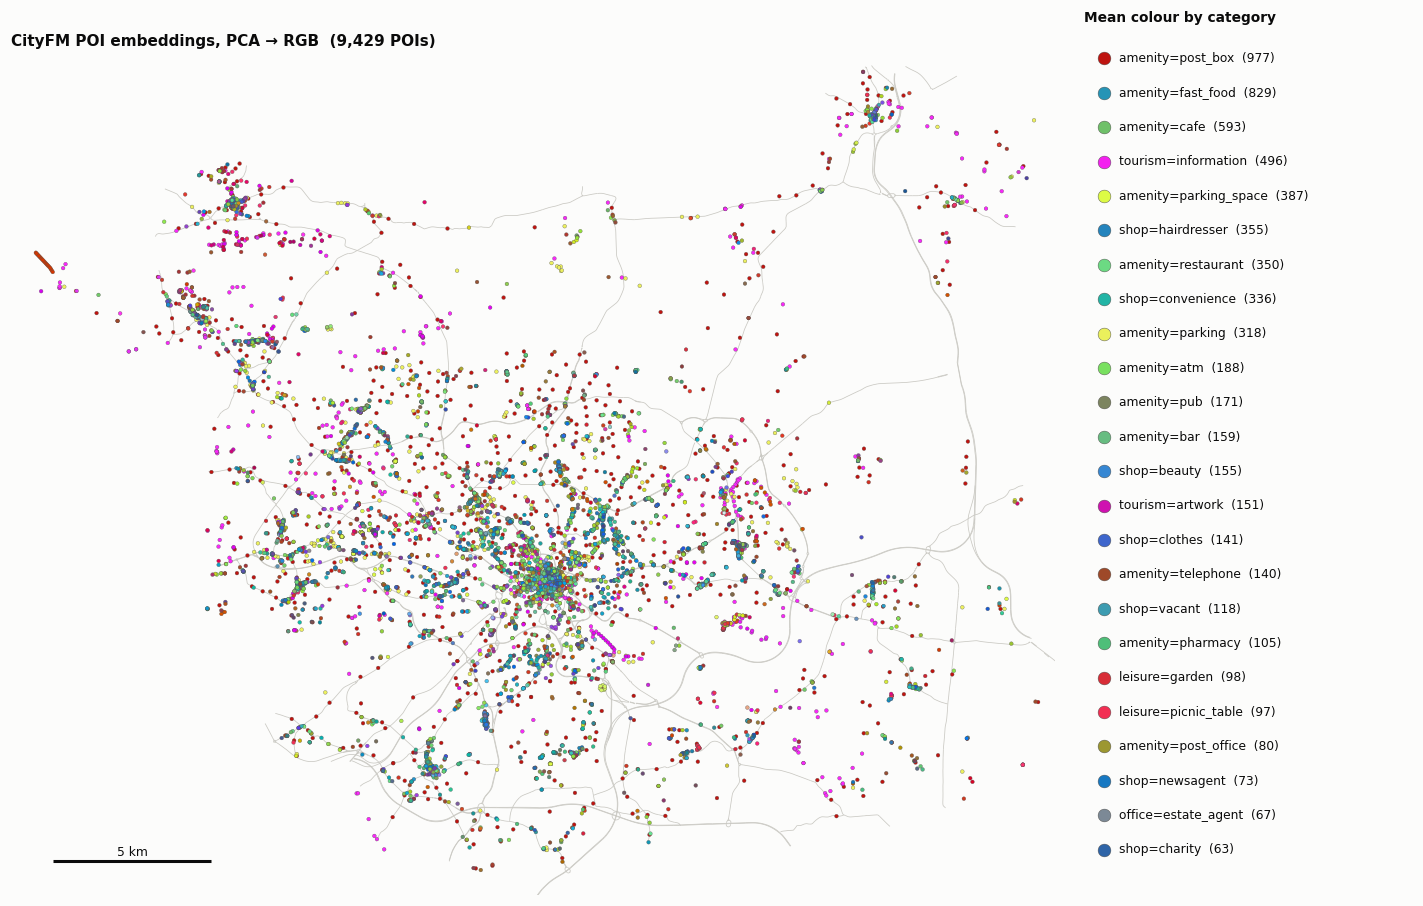

,low,high
PC1,"shop=newsagent, shop=bakery, shop=butcher, shop=hairdresser","leisure=picnic_table, tourism=information, amenity=parki..."
PC2,"tourism=artwork, amenity=post_box, tourism=information, ...","amenity=parking_space, amenity=parking, amenity=atm, ame..."
PC3,"amenity=post_box, amenity=kindergarten, amenity=telephon...","tourism=information, shop=jewelry, tourism=artwork, offi..."


In [37]:
pca_pts = PCA(n_components=3, random_state=SEED).fit(X_nodes)
S_pts = pca_pts.transform(X_nodes)
rgb_pts = to_rgb(S_pts)
print('variance explained by PC1-3:', pca_pts.explained_variance_ratio_.round(3))

fig = plt.figure(figsize=(13, 9.5))
ax = fig.add_axes([0.01, 0, 0.73, 0.95])
base_map(ax, f'CityFM POI embeddings, PCA → RGB  ({len(nodes):,} POIs)')
order_pts = np.argsort(np.bincount(row_of[nodes.text].values)[row_of[nodes.text].values])[::-1]
ax.scatter(nodes.x.values[order_pts], nodes.y.values[order_pts], c=rgb_pts[order_pts],
           s=6, lw=0.2, edgecolors=INK2, zorder=2)
pad = 1500
ax.set_xlim(nodes.x.quantile(0.002) - pad, nodes.x.quantile(0.998) + pad)
ax.set_ylim(nodes.y.quantile(0.002) - pad, nodes.y.quantile(0.998) + pad)
scale_bar(ax)

# Key: the mean colour of each of the most common categories.
key = fig.add_axes([0.76, 0.1, 0.23, 0.8]); key.axis('off')
KEY_CATS = nodes.category.value_counts().index[:24]
for i, c in enumerate(KEY_CATS):
    m = (nodes.category == c).values
    key.scatter(0, -i, s=70, color=rgb_pts[m].mean(0), edgecolors=INK2, lw=0.3)
    key.annotate(f'{c}  ({m.sum()})', (0, -i), xytext=(10, 0), textcoords='offset points',
                 va='center', fontsize=8)
key.set_xlim(-0.2, 3); key.set_ylim(-len(KEY_CATS) + 0.5, 0.8)
key.set_title('Mean colour by category', loc='left', fontsize=9)
plt.show()

pc_poles(S_pts, nodes.category.values, nodes.category.value_counts().index[:40])

Because the embedding is mostly set by the category, the point map is close to a category map. The spatial structure shows most clearly once POIs are pooled by area.

320 hexes with POIs, 214 with ≥ 5; variance explained by PC1-3: [0.651 0.126 0.101]


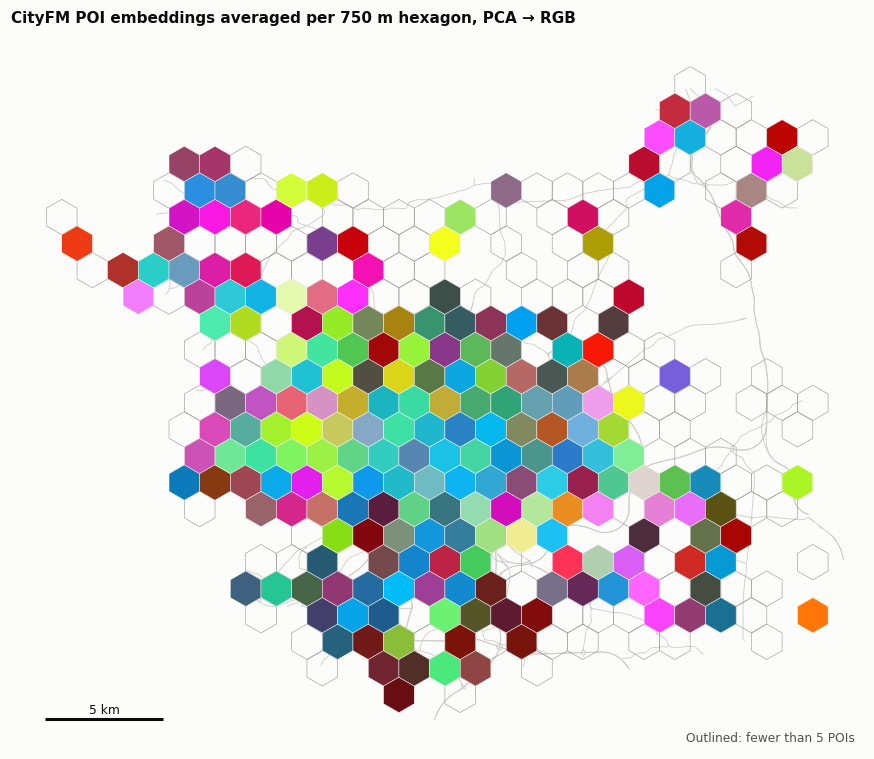

In [38]:
HEX_M, MIN_POIS = 750, 5

def hex_index(x, y, size):
    # Pointy-top hexagons with circumradius `size`; cube-coordinate rounding.
    q = (np.sqrt(3) / 3 * x - y / 3) / size
    r = (2 / 3 * y) / size
    s = -q - r
    rq, rr, rs = np.round(q), np.round(r), np.round(s)
    dq, dr, ds = np.abs(rq - q), np.abs(rr - r), np.abs(rs - s)
    fix_q = (dq > dr) & (dq > ds)
    fix_r = ~fix_q & (dr > ds)
    rq = np.where(fix_q, -rr - rs, rq)
    rr = np.where(fix_r, -rq - rs, rr)
    return rq.astype(int), rr.astype(int)

def hex_polygons(q, r, size):
    cx = size * np.sqrt(3) * (q + r / 2)
    cy = size * 1.5 * r
    ang = np.radians(30 + 60 * np.arange(6))
    return np.stack([np.column_stack([x + size * np.cos(ang), y + size * np.sin(ang)])
                     for x, y in zip(cx, cy)])

nodes['hq'], nodes['hr'] = hex_index(nodes.x.values, nodes.y.values, HEX_M)
hex_id = nodes.groupby(['hq', 'hr']).ngroup().values
hexes = nodes.groupby(['hq', 'hr']).size().rename('n').reset_index()
H_mean = np.zeros((len(hexes), X_nodes.shape[1]))
np.add.at(H_mean, hex_id, X_nodes)
H_mean /= hexes.n.values[:, None]

full = (hexes.n >= MIN_POIS).values
pca_hex = PCA(n_components=3, random_state=SEED).fit(H_mean[full])
S_hex = pca_hex.transform(H_mean[full])
rgb_hex = to_rgb(S_hex)
polys_hex = hex_polygons(hexes.hq.values, hexes.hr.values, HEX_M)
print(f'{len(hexes):,} hexes with POIs, {full.sum():,} with ≥ {MIN_POIS}; '
      f'variance explained by PC1-3: {pca_hex.explained_variance_ratio_.round(3)}')

fig, ax = plt.subplots(figsize=(10, 9.5))
base_map(ax, f'CityFM POI embeddings averaged per {HEX_M} m hexagon, PCA → RGB')
ax.add_collection(PolyCollection(polys_hex[~full], facecolors='none', edgecolors=OTHER, linewidths=0.4, zorder=1))
ax.add_collection(PolyCollection(polys_hex[full], facecolors=rgb_hex, edgecolors=SURFACE, linewidths=0.3, zorder=2))
ax.set_xlim(polys_hex[..., 0].min() - pad, polys_hex[..., 0].max() + pad)
ax.set_ylim(polys_hex[..., 1].min() - pad, polys_hex[..., 1].max() + pad)
scale_bar(ax)
ax.annotate(f'Outlined: fewer than {MIN_POIS} POIs', (0.99, 0.01), xycoords='axes fraction',
            ha='right', fontsize=8, color=INK2)
plt.show()

**Reading the hex map.** Each colour channel is one component, shown on its own below as percentile ranks (orange = low, white = median, blue = high). To interpret each component, the table correlates hex scores with the hex's **share of POIs in each category**, using categories with ≥ 30 POIs. Strong positive or negative correlations show which mix of POIs pushes a hex towards that end.

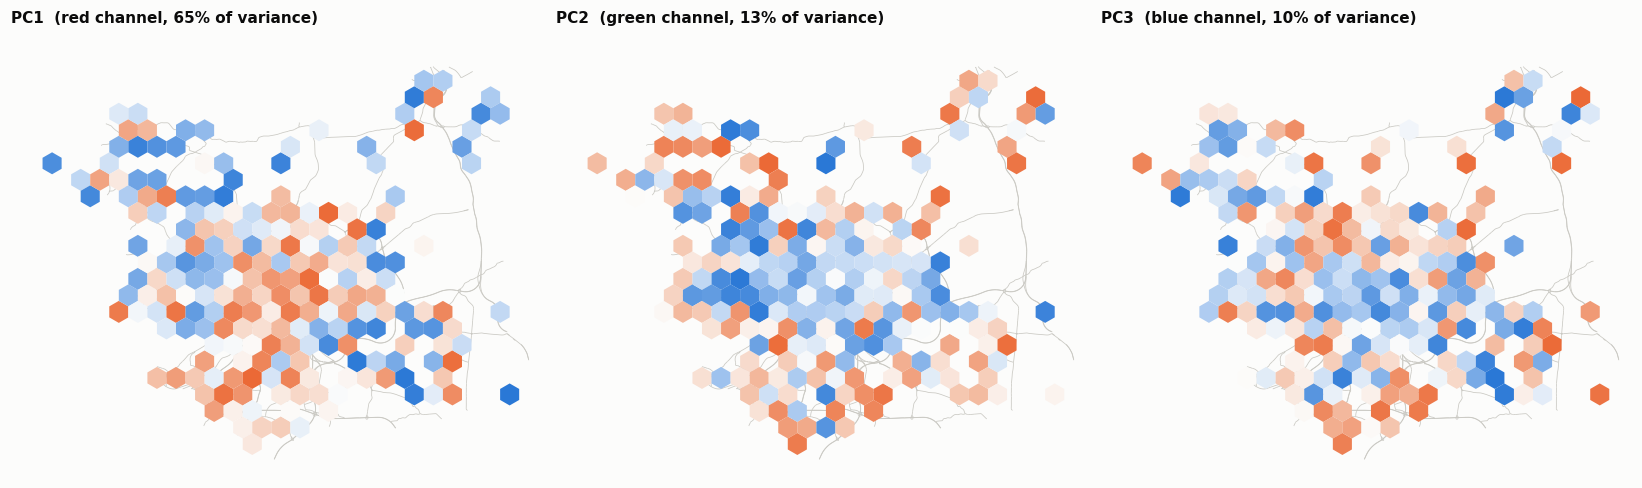

,low end (ρ),high end (ρ)
PC1,"fast_food (-0.63), restaurant (-0.48), convenience (-0.4...","information (+0.64), picnic_table (+0.25), post_box (+0...."
PC2,"post_box (-0.56), information (-0.18), public_bookcase (...","parking (+0.75), parking_space (+0.42), hairdresser (+0...."
PC3,"post_box (-0.58), parking_space (-0.15), kindergarten (-...","beauty (+0.40), information (+0.37), butcher (+0.36), ba..."


In [39]:
DIVERGE = LinearSegmentedColormap.from_list('div', [ORANGE, '#f4c3ab', SURFACE, '#a9c9f0', BLUE])
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
for j, (ax, channel) in enumerate(zip(axes, ['red', 'green', 'blue'])):
    v = rgb_hex[:, j]
    base_map(ax, f'PC{j + 1}  ({channel} channel, {pca_hex.explained_variance_ratio_[j]:.0%} of variance)')
    pc = PolyCollection(polys_hex[full], array=v, cmap=DIVERGE, clim=(0, 1),
                        edgecolors='none', zorder=2)
    ax.add_collection(pc)
    ax.set_xlim(polys_hex[..., 0].min() - pad, polys_hex[..., 0].max() + pad)
    ax.set_ylim(polys_hex[..., 1].min() - pad, polys_hex[..., 1].max() + pad)
plt.tight_layout(); plt.show()

share_cats = nodes.category.value_counts()
share_cats = share_cats[share_cats >= 30].index
shares = (pd.crosstab(hex_id, nodes.category)[share_cats]
          .div(hexes.n.values, axis=0).values[full])
corr = pd.DataFrame({f'PC{j + 1}': [spearmanr(S_hex[:, j], shares[:, c])[0] for c in range(len(share_cats))]
                     for j in range(3)}, index=share_cats)
pd.DataFrame({pc: {'low end (ρ)': ', '.join(f'{c.split("=")[1]} ({v:+.2f})' for c, v in col.nsmallest(5).items()),
                   'high end (ρ)': ', '.join(f'{c.split("=")[1]} ({v:+.2f})' for c, v in col.nlargest(5).items())}
              for pc, col in corr.items()}).T

---
# Next model (v2)

Two changes are ready for the next training run (the ToDo list at the top tracks the rest). Neither has been trained yet, so this part shows what they do to the model's **inputs and starting point**. E3 lists what to compare once the v2 model is back.

| Change | Why | Code | Section |
|---|---|---|---|
| Replace the house-type buildings in each context with one summary entry | 80% of v1 context entries are the identical `building: house` (B2), which swamps everything else in the context average | `CityFM_collapse.py -c Leeds -o Leeds_v2` writes `Leeds_v2/Data/`. The rule is `collapse_residential` in `utils/pre_processing.py` | **E1** |
| Load ImageNet weights into ResNet-18, and rasterise footprints in metres | v1's image network started from random weights (A3) and saw sheared footprints (§6c) | `config.vision_pretrained` and `config.raster_metric` | **E2** |

Older models are unaffected: loading a model sets the rasterisation to match how it was trained (`match_raster` in `utils/pre_processing.py`), so every v1 result above is unchanged.

## E1. Collapsing houses

**The rule.** In every road segment's context, an entity is collapsed if it is an **unnamed building whose only kept tag is `building`** = `house`, `semidetached_house`, `detached`, `bungalow` or `residential`. They are all replaced by **one** entry, whose text depends on how many there were:

| House-type buildings within 100 m | The single entry v2 reads instead |
|---|---|
| 1-20 | `building: few houses` |
| 21-50 | `building: some houses` |
| 51-100 | `building: many houses` |
| more than 100 | `building: very many houses` |

The thresholds are close to the quartiles of the non-zero counts (22, 52 and 90). The entry uses words rather than the count, because BERT reads numbers poorly.

**Not collapsed:** named buildings (e.g. `name: Westfield Court, building: residential`), apartments, garages, every POI and every non-residential building. The buildings stay in `entities.json`, so stage 2 still trains on their footprints. The same rule is applied to the building contexts used by the `build_func` task. Two other house types never reach a context at all, because pre-processing drops them (A2): `building=terrace` (1,592 polygons in Leeds) and `building=yes` (18,163).

**E1a.** What each summary entry stands for. The cell first checks that `Leeds_v2/Data/data.json` is exactly the rule applied to the v1 contexts.

In [40]:
# v2 inputs: the collapsed contexts written by CityFM_collapse.py, checked against the rule itself.
from utils.pre_processing import is_residential, collapse_residential, residential_summaries

CITY_V2 = 'Leeds_v2'
with open(f'{CITY_V2}/Data/data.json', encoding='utf-8') as f:
    data_v2 = json.load(f)
entities_v2 = {**entities, **residential_summaries()}
assert all(data_v2[k]['context'] == collapse_residential(data[k]['context'], entities) for k in data)

# The residential type of every entity the rule collapses, and how many of them each segment has.
res_type = {k: e['tags']['building'] for k, e in entities.items() if is_residential(e)}
n_res = pd.Series({k: sum(c in res_type for c in v['context']) for k, v in data.items()})

BINS = [(1, 20, 'few houses'), (21, 50, 'some houses'), (51, 100, 'many houses'), (101, np.inf, 'very many houses')]
assert [(hi, w) for _, hi, w in BINS] == [(float(h), w) for h, w in osm_strings.residential_bins]
BIN_COLOURS = dict(zip([w for *_, w in BINS], ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b']))
seg_bin = pd.Series('none', index=n_res.index)
for lo, hi, w in BINS:
    seg_bin[(n_res >= lo) & (n_res <= hi)] = w

rows = {}
for lo, hi, w in BINS:
    n = n_res[seg_bin == w]
    rows[f'building: {w}'] = {'house-type buildings': f'{lo}-{hi:.0f}' if np.isfinite(hi) else f'> {lo - 1}',
                             'road segments': len(n), 'share of segments': len(n) / len(n_res),
                             'median buildings': n.median(), 'context entries replaced': n.sum()}
n = n_res[seg_bin == 'none']
rows['(no summary entry)'] = {'house-type buildings': '0', 'road segments': len(n), 'share of segments': len(n) / len(n_res),
                              'median buildings': 0, 'context entries replaced': 0}
bin_table = pd.DataFrame(rows).T
print(f'{len(res_type):,} buildings are collapsed: ' +
      ', '.join(f'{t} {c:,}' for t, c in collections.Counter(res_type.values()).most_common()))
print(f'They make up {n_res.sum():,} of the {sum(len(v["context"]) for v in data.values()):,} v1 context entries '
      f'(a building near several segments is counted in each).')
none_hw = pd.Series([data[k]['tags'].get('highway') for k in seg_bin.index[seg_bin == 'none']]).value_counts(normalize=True)
print('Segments with no summary entry, by road type: ' + ', '.join(f'{h} {s:.0%}' for h, s in none_hw.head(5).items()))
bin_table.style.format({'road segments': '{:,}', 'share of segments': '{:.0%}', 'median buildings': '{:.0f}',
                        'context entries replaced': '{:,}'})

245,863 buildings are collapsed: house 231,872, semidetached_house 6,213, residential 5,943, detached 1,333, bungalow 502
They make up 2,610,455 of the 3,056,361 v1 context entries (a building near several segments is counted in each).
Segments with no summary entry, by road type: service 47%, path 13%, track 10%, unclassified 6%, trunk 4%


,house-type buildings,road segments,share of segments,median buildings,context entries replaced
building: few houses,1-20,"9,488",17%,8,"82,070"
building: some houses,21-50,"10,164",18%,36,"361,443"
building: many houses,51-100,"12,371",22%,72,"903,472"
building: very many houses,> 100,"8,055",15%,136,"1,263,470"
(no summary entry),0,"15,361",28%,0,0


**E1b.** Where the thresholds fall. Each bar covers 5 buildings, coloured by the summary entry those segments get.

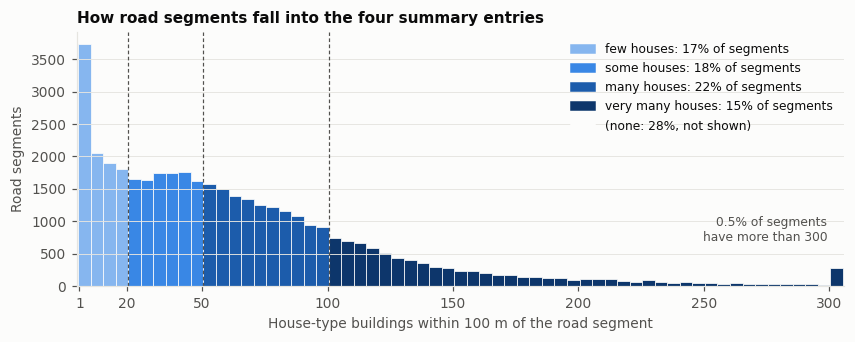

In [41]:
# Distribution of house-type buildings per road segment, with the v2 thresholds.
from matplotlib.patches import Patch

X_MAX, WIDTH = 300, 5
pos = n_res[n_res > 0].clip(upper=X_MAX + 1)
edges = np.arange(0.5, X_MAX + WIDTH + 1, WIDTH)        # 0.5, 5.5, ...: every threshold falls on an edge
counts, _ = np.histogram(pos, edges)
fig, ax = plt.subplots(figsize=(9, 3))
for lo_e, c in zip(edges[:-1], counts):
    w = next(w for lo, hi, w in BINS if lo_e + 1 <= hi)
    ax.bar(lo_e, c, width=WIDTH, align='edge', color=BIN_COLOURS[w], edgecolor=SURFACE, linewidth=0.5)
for _, hi, _ in BINS[:-1]:
    ax.axvline(hi + 0.5, color=INK2, lw=0.8, ls=(0, (3, 2)))
ax.annotate(f'{(n_res > X_MAX).mean():.1%} of segments\nhave more than {X_MAX}', (X_MAX + 3, counts[-1]),
            xytext=(-6, 18), textcoords='offset points', ha='right', fontsize=8, color=INK2)
ax.set_xlim(0, X_MAX + WIDTH + 1); ax.grid(axis='x', visible=False)
ax.set_xticks([1, 20, 50, 100, 150, 200, 250, 300])
ax.set_xlabel(f'House-type buildings within {config.context_d} m of the road segment')
ax.set_ylabel('Road segments')
handles = [Patch(color=BIN_COLOURS[w], label=f'{w}: {(seg_bin == w).mean():.0%} of segments') for *_, w in BINS]
handles.append(Patch(color=SURFACE, label=f'(none: {(seg_bin == "none").mean():.0%}, not shown)'))
ax.legend(handles=handles, loc='upper right', fontsize=8)
ax.set_title('How road segments fall into the four summary entries', loc='left')
plt.show()

**Reading E1a-b.** The four entries split the segments that have houses fairly evenly (15-22% of all segments each), so no single entry dominates. `many houses` is the most common. The 28% of segments with no summary entry are mostly not streets: about half are service roads (car parks, industrial estates, driveways), and most of the rest are paths, farm tracks and main roads away from housing. Only 2% of them are residential streets.

**E1c.** The same information on the map. Left: the house-type tag of every collapsed building (one dot each; plain `house` in grey). Right: the summary entry each road segment gets in v2.

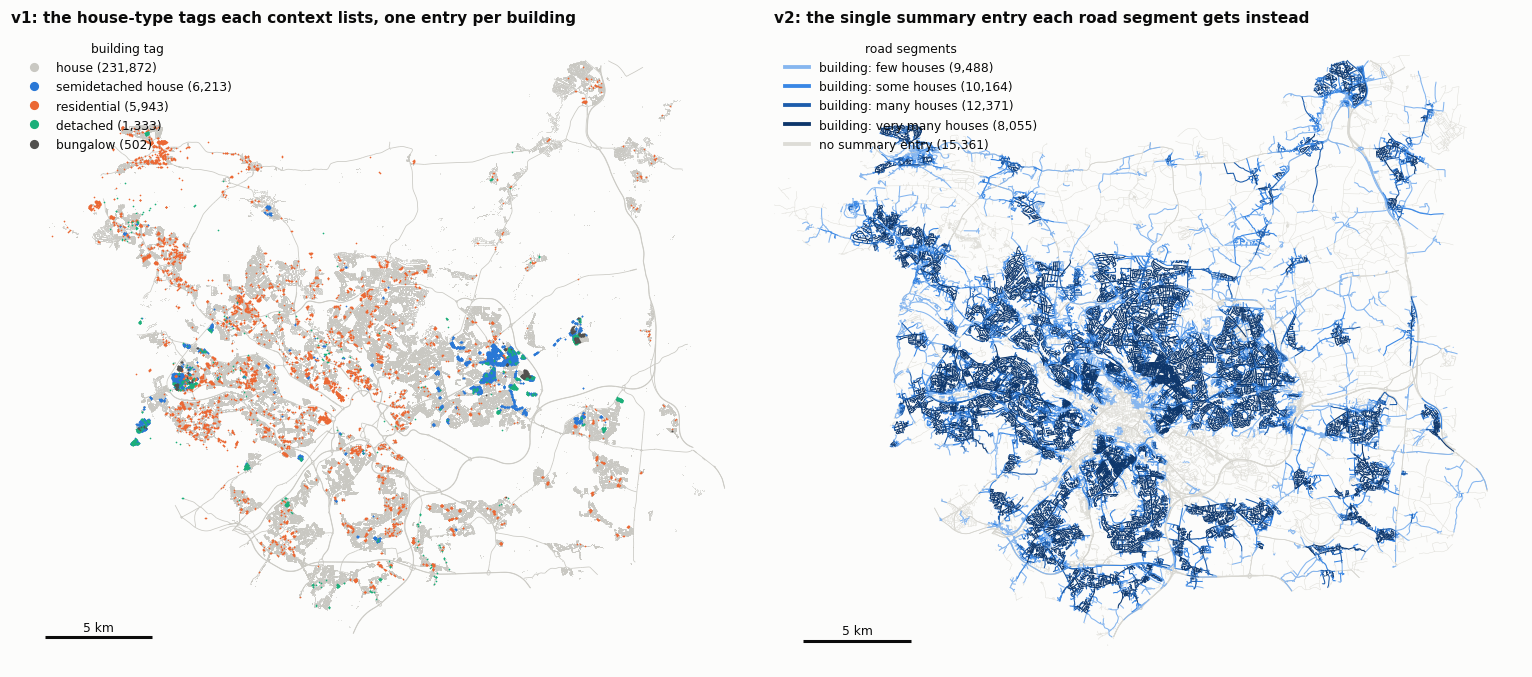

In [42]:
# Before and after, across Leeds: the house-type tags v1 reads, and the summary entries v2 reads instead.
from matplotlib.lines import Line2D

TYPE_STYLE = {  # house is ~94% of them, so it is the muted background
    'house': ('#c9c8c2', 'house'), 'semidetached_house': (BLUE, 'semidetached house'),
    'residential': (ORANGE, 'residential'), 'detached': (AQUA, 'detached'), 'bungalow': (INK2, 'bungalow')}
res_ids = np.array(list(res_type))
res_t = np.array([res_type[k] for k in res_ids])
res_xy = np.column_stack(to_bng.transform([entities[k]['lon'] for k in res_ids], [entities[k]['lat'] for k in res_ids]))
seg_ids = np.array(list(data))
seg_lines = {k: seg_xy(data[k]['points']) for k in seg_ids}

def draw_types(ax):
    for t, (colour, _) in TYPE_STYLE.items():
        m = res_t == t
        ax.scatter(res_xy[m, 0], res_xy[m, 1], s=0.15 if t == 'house' else 1.2, color=colour, lw=0,
                   zorder=1 if t == 'house' else 2)

def draw_bins(ax):
    for w, colour in [('none', CONTEXT)] + list(BIN_COLOURS.items()):
        ks = seg_ids[seg_bin.loc[seg_ids].values == w]
        ax.add_collection(LineCollection([seg_lines[k] for k in ks], colors=colour,
                                         linewidths=0.3 if w == 'none' else 0.7, zorder=1))

fig, axes = plt.subplots(1, 2, figsize=(14, 6.6))
base_map(axes[0], 'v1: the house-type tags each context lists, one entry per building')
draw_types(axes[0])
axes[0].legend(handles=[Line2D([], [], ls='', marker='o', ms=5, color=c, label=f'{label} ({(res_t == t).sum():,})')
                        for t, (c, label) in TYPE_STYLE.items()],
               loc='upper left', fontsize=8, title='building tag', title_fontsize=8)
base_map(axes[1], 'v2: the single summary entry each road segment gets instead')
draw_bins(axes[1])
axes[1].legend(handles=[Line2D([], [], color=c, lw=2.5, label=f'building: {w} ({(seg_bin == w).sum():,})')
                        for w, c in BIN_COLOURS.items()] +
                       [Line2D([], [], color=CONTEXT, lw=2.5, label=f'no summary entry ({(seg_bin == "none").sum():,})')],
               loc='upper left', fontsize=8, title='road segments', title_fontsize=8)
for ax in axes:
    ax.autoscale_view()
axes[1].set_xlim(axes[0].get_xlim()); axes[1].set_ylim(axes[0].get_ylim())
for ax in axes:
    scale_bar(ax)
plt.tight_layout(); plt.show()

**Reading E1c.** The detailed tags v1 used to tell houses apart mostly reflect **mapping habit**, not housing type. 94% of house-type buildings are plain `house`, and the other tags come in tight clusters rather than any city-wide pattern. That is typical of tags added by individual mappers in the areas they worked on. Collapsing them therefore loses little real information. v2's summary entries trace **residential density** instead: `many` and `very many houses` fill the suburbs, `few houses` marks their edges, and the city centre and countryside mostly get no entry.

**E1d.** A closer look, at the 2 km square with the most buildings tagged with a house type other than plain `house` (in east Leeds). Left: v1, where every building is its own context entry. Right: v2, the summary entry of each road segment.

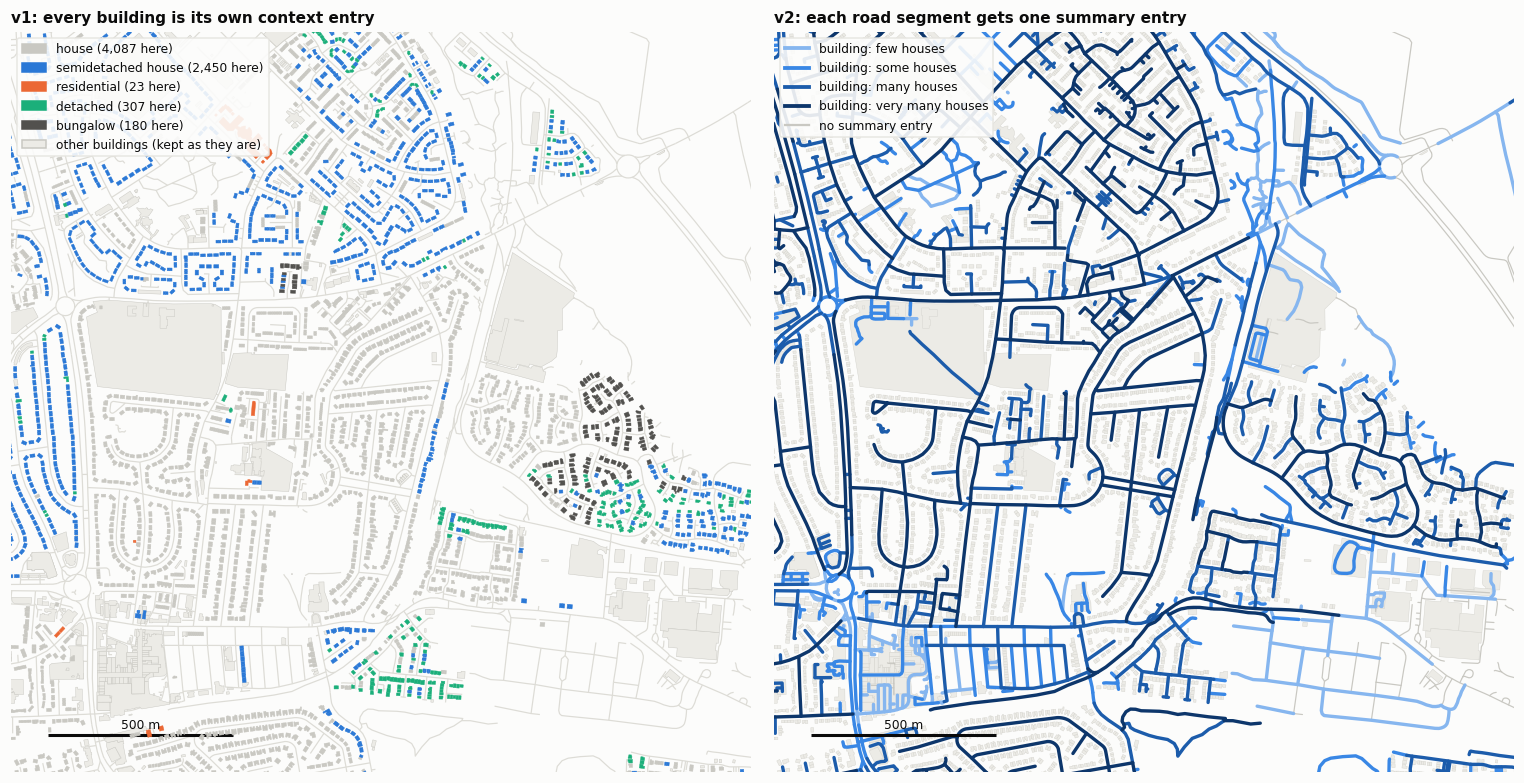

window centre 53.8127, -1.4403; 7,495 buildings, 1,496 segments


In [43]:
# Zoom: the 2 km square with the most buildings tagged with a house type other than plain "house".
from matplotlib.collections import PolyCollection

ZOOM_M = 2000
cell = np.floor(res_xy / ZOOM_M).astype(int)
cells = pd.DataFrame({'cx': cell[:, 0], 'cy': cell[:, 1], 'other': res_t != 'house'})
best = cells.groupby(['cx', 'cy']).other.sum().idxmax()
# Centre the window on that cell's non-"house" buildings.
in_cell = (cell[:, 0] == best[0]) & (cell[:, 1] == best[1]) & (res_t != 'house')
cx, cy = np.median(res_xy[in_cell], axis=0)
X0, X1, Y0, Y1 = cx - ZOOM_M / 2, cx + ZOOM_M / 2, cy - ZOOM_M / 2, cy + ZOOM_M / 2

def in_window(xy):
    return (xy[:, 0] >= X0 - 200) & (xy[:, 0] <= X1 + 200) & (xy[:, 1] >= Y0 - 200) & (xy[:, 1] <= Y1 + 200)

poly_ids = [k for k, e in entities.items() if e['type'] == 'polygon']
poly_ctr = np.column_stack(to_bng.transform([entities[k]['lon'] for k in poly_ids], [entities[k]['lat'] for k in poly_ids]))
win_polys = [k for k, ok in zip(poly_ids, in_window(poly_ctr)) if ok]
win_shapes = {k: seg_xy(entities[k]['points']) for k in win_polys}
win_segs = [k for k in seg_ids if in_window(seg_lines[k]).any()]

def zoom_axes(ax, title):
    ax.set_xlim(X0, X1); ax.set_ylim(Y0, Y1); ax.set_aspect('equal'); clean_axes(ax)
    ax.set_title(title, loc='left')
    ax.plot([X0 + 100, X0 + 600], [Y0 + 100] * 2, color=INK, lw=2, solid_capstyle='butt')
    ax.annotate('500 m', (X0 + 350, Y0 + 100), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
ax = axes[0]
zoom_axes(ax, 'v1: every building is its own context entry')
ax.add_collection(LineCollection([seg_lines[k] for k in win_segs], colors=CONTEXT, linewidths=0.8, zorder=0))
groups = collections.defaultdict(list)
for k in win_polys:
    groups[res_type.get(k, 'other')].append(win_shapes[k])
ax.add_collection(PolyCollection(groups.pop('other', []), facecolors='#ecebe6', edgecolors='#c9c8c2', linewidths=0.3, zorder=1))
for t, (colour, label) in TYPE_STYLE.items():
    ax.add_collection(PolyCollection(groups.get(t, []), facecolors=colour, edgecolors=colour, linewidths=0.3, zorder=2))
handles = [Patch(color=TYPE_STYLE[t][0], label=f'{TYPE_STYLE[t][1]} ({len(groups.get(t, [])):,} here)') for t in TYPE_STYLE]
handles.append(Patch(facecolor='#ecebe6', edgecolor='#c9c8c2', label='other buildings (kept as they are)'))
ax.legend(handles=handles, loc='upper left', fontsize=8, framealpha=0.9, frameon=True, edgecolor=GRID)

ax = axes[1]
zoom_axes(ax, 'v2: each road segment gets one summary entry')
ax.add_collection(PolyCollection([win_shapes[k] for k in win_polys], facecolors='#ecebe6', edgecolors='#d6d5cf',
                                 linewidths=0.3, zorder=0))
for w, colour in [('none', '#c9c8c2')] + list(BIN_COLOURS.items()):
    ks = [k for k in win_segs if seg_bin[k] == w]
    ax.add_collection(LineCollection([seg_lines[k] for k in ks], colors=colour, linewidths=0.8 if w == 'none' else 2.2,
                                     zorder=1, capstyle='round'))
ax.legend(handles=[Line2D([], [], color=c, lw=2.5, label=f'building: {w}') for w, c in BIN_COLOURS.items()] +
                  [Line2D([], [], color='#c9c8c2', lw=1.5, label='no summary entry')],
          loc='upper left', fontsize=8, framealpha=0.9, frameon=True, edgecolor=GRID)
plt.tight_layout(); plt.show()
lat, lon = to_bng.transform(cx, cy, direction='INVERSE')[::-1]
print(f'window centre {lat:.4f}, {lon:.4f}; {len(win_polys):,} buildings, {len(win_segs):,} segments')

**Reading E1d.** Semi-detached and detached houses are tagged street by street: whole streets of `semidetached house` sit next to streets of untyped `house`. This confirms the mapping-habit reading. On the right, most residential streets come out as `many` or `very many houses`. Roads beside the larger non-residential sites and open land mostly get `few houses`, and only roads with no houses at all within 100 m get no entry.

**E1e.** What the thresholds do not control for. A context holds everything within 100 m of any point along the segment, so a longer segment collects more houses, and its count reflects its length as well as housing density.

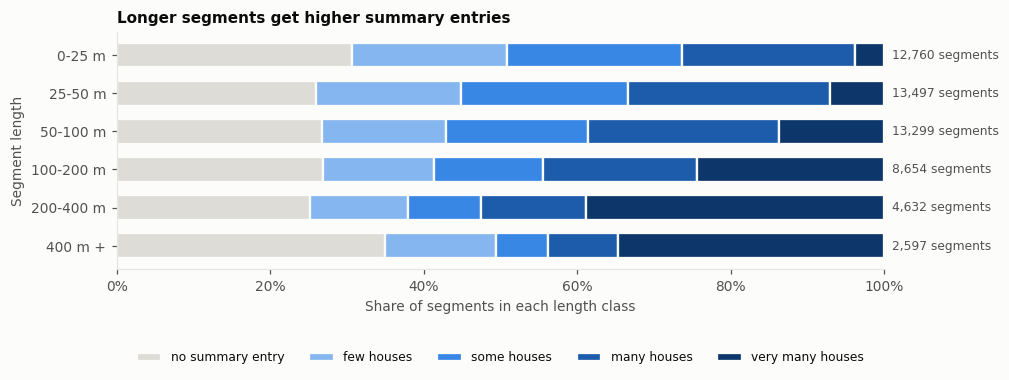

Segments with house-type buildings: Spearman rho(length, count) = 0.28. Median length by entry: few houses 45 m, some houses 42 m, many houses 48 m, very many houses 128 m.
Median segment length 54 m; 3.1% of segments are 500 m or longer.


In [44]:
# The count behind each summary entry depends on how long the segment is, as well as on housing density.
seg_len = pd.Series({k: np.linalg.norm(np.diff(seg_lines[k], axis=0), axis=1).sum() for k in seg_ids})
LEN_EDGES = [0, 25, 50, 100, 200, 400, np.inf]
len_class = pd.cut(seg_len, LEN_EDGES, right=False,
                   labels=[f'{a:.0f}-{b:.0f} m' if np.isfinite(b) else f'{a:.0f} m +' for a, b in zip(LEN_EDGES[:-1], LEN_EDGES[1:])])
share = pd.crosstab(len_class, seg_bin.loc[seg_len.index], normalize='index')[['none'] + list(BIN_COLOURS)]

fig, ax = plt.subplots(figsize=(9, 2.8))
left = np.zeros(len(share))
for w in share.columns:
    ax.barh(share.index.astype(str), share[w], left=left, color=CONTEXT if w == 'none' else BIN_COLOURS[w],
            height=0.65, edgecolor=SURFACE, linewidth=1.5, label='no summary entry' if w == 'none' else w)
    left += share[w].values
for i, (c, n) in enumerate(len_class.value_counts().reindex(share.index).items()):
    ax.annotate(f'{n:,} segments', (1, i), xytext=(5, 0), textcoords='offset points', va='center', fontsize=8, color=INK2)
ax.invert_yaxis(); ax.grid(visible=False); ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylabel('Segment length'); ax.set_xlabel('Share of segments in each length class')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=5, fontsize=8)
ax.set_title('Longer segments get higher summary entries', loc='left')
plt.show()

res_segs = n_res > 0
rho = spearmanr(seg_len[res_segs], n_res[res_segs]).correlation
print(f'Segments with house-type buildings: Spearman rho(length, count) = {rho:.2f}. Median length by entry: ' +
      ', '.join(f'{w} {seg_len[seg_bin == w].median():.0f} m' for w in BIN_COLOURS) + '.')
print(f'Median segment length {seg_len.median():.0f} m; {(seg_len >= 500).mean():.1%} of segments are 500 m or longer.')

**Reading E1e.** Length matters at every scale. The share of `very many houses` rises from 4% of segments under 25 m to 14% at 50-100 m, 24% at 100-200 m and 39% at 200-400 m. Short segments still often get `many houses`, because the 100 m radius around their points covers a whole block. So for long roads, `very many houses` partly means "long". Counting houses per 100 m of road would remove this, at the cost of a less obvious entry. It is worth revisiting only if v2's contexts still look too alike.

A related pre-processing quirk: the context loop in `prepare_data` checks a segment's points in order and gives up on an entity as soon as one point is 500 m or more from it (`config.context_out`). Entities near the far end of a segment longer than about 500 m are therefore missed. 3.1% of Leeds segments are that long.

**E1f.** The new contexts next to the old ones and the paper's cities (compare B2). "House-type buildings" uses the collapse rule, so the v1 figure (47) is a little higher than B2's 44 plain `building: house`.

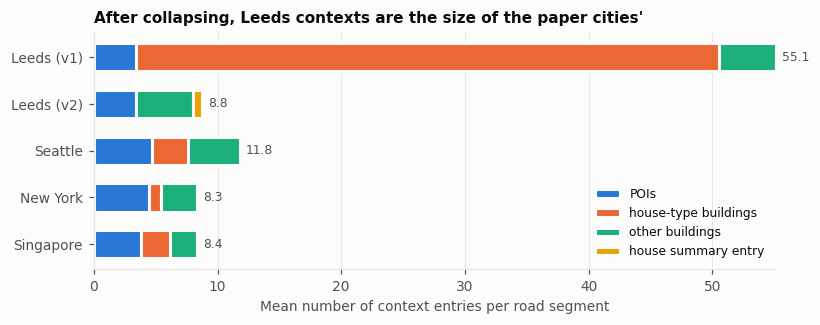

Building contexts (used by build_func): mean size 27.2 in v1, 7.1 in v2.


,context size: mean,context size: median,context size: 95th percentile,empty contexts
Leeds (v1),55.1,40,167,7%
Leeds (v2),8.8,4,30,7%
Seattle,11.8,6,42,17%
New York,8.3,2,39,25%
Singapore,8.4,4,36,26%


In [45]:
# Context composition before and after, next to the paper's cities.
def context_parts(ents, segs):
    ctx = [[k for k in s['context'] if k in ents] for s in segs.values()]
    kind = {k: ('POIs' if e['type'] == 'node' else 'house summary entry' if e['type'] == 'summary'
                else 'house-type buildings' if is_residential(e) else 'other buildings') for k, e in ents.items()}
    n = np.array([len(c) for c in ctx])
    out = {p: np.mean([sum(kind[k] == p for k in c) for c in ctx]) for p in COMP_PARTS}
    out.update({'context size: mean': n.mean(), 'context size: median': np.median(n),
                'context size: 95th percentile': np.percentile(n, 95), 'empty contexts': (n == 0).mean()})
    return out

COMP_PARTS = ['POIs', 'house-type buildings', 'other buildings', 'house summary entry']
COMP_COLOURS = dict(zip(COMP_PARTS, [BLUE, ORANGE, AQUA, '#eda100']))  # categorical slots 1-4, in stack order
comp = {f'{CITY} (v1)': context_parts(entities, data), f'{CITY} (v2)': context_parts(entities_v2, data_v2)}
for c in CITIES[1:]:
    d = load_city(c)
    comp[c] = context_parts(d['entities'], d['data'])
    del d
comp = pd.DataFrame(comp)

fig, ax = plt.subplots(figsize=(8, 2.8))
left = np.zeros(comp.shape[1])
for p in COMP_PARTS:
    v = comp.loc[p].values.astype(float)
    ax.barh(comp.columns, v, left=left, color=COMP_COLOURS[p], height=0.6, edgecolor=SURFACE, linewidth=2, label=p)
    left += v
for i, total in enumerate(left):
    ax.annotate(f'{total:.1f}', (total, i), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8, color=INK2)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_axisbelow(True)
ax.set_xlabel('Mean number of context entries per road segment')
ax.legend(loc='lower right', fontsize=8)
ax.set_title('After collapsing, Leeds contexts are the size of the paper cities\'', loc='left')
plt.show()

with open(f'{CITY}/Data/buildings_context.json', encoding='utf-8') as f:
    b1 = json.load(f)
with open(f'{CITY_V2}/Data/buildings_context.json', encoding='utf-8') as f:
    b2 = json.load(f)
print(f'Building contexts (used by build_func): mean size {np.mean([len(v) for v in b1.values()]):.1f} in v1, '
      f'{np.mean([len(v) for v in b2.values()]):.1f} in v2.')
del b1, b2
comp.T[['context size: mean', 'context size: median', 'context size: 95th percentile', 'empty contexts']].style.format(
    {'context size: mean': '{:.1f}', 'context size: median': '{:.0f}', 'context size: 95th percentile': '{:.0f}', 'empty contexts': '{:.0%}'})

**Reading E1f.** Leeds contexts drop from 55.1 to 8.8 entries, in line with Seattle, New York and Singapore. POIs and other buildings (8.0 per segment) are untouched, so they now make up 92% of an average context instead of 15%. Stage 1 also has far less text to encode per quiz.

**E1g.** The stage-1 quiz from C3 on v2 contexts, scored with **untuned BERT** and with **tag matching**. This is not a result of v2 training. It measures how much the new inputs alone change the quiz, and so sets the bar the v2 model has to clear.

* **POI held out:** the same 1,280 streets and POI queries as in C3. Only the rest of each context changes, so v1 and v2 can be compared query by query.
* **Training-style:** the query is drawn from the context, so it is drawn afresh from the v2 contexts, as training would. Far fewer queries are now house entries, which on its own makes this version easier. Its v1 and v2 numbers are therefore **not** a like-for-like comparison.

POI held out, vanilla BERT top-1: v2 - v1 = +0.8% (standard error 0.5%)
POI held out, vanilla BERT top-5: v2 - v1 = +2.7% (standard error 1.0%)


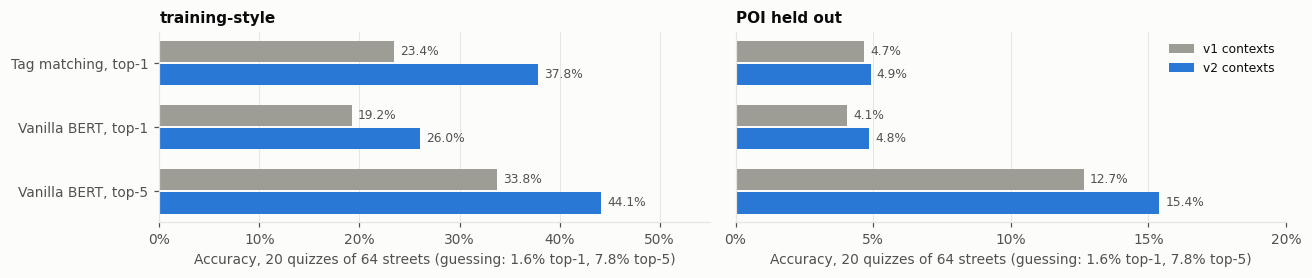

In [46]:
# The stage-1 quiz (C3) on v2 contexts, scored before any v2 training: the bar the v2 model has to clear.
bert_lm, bert_proj = ENCODERS['Vanilla BERT']
d = config.lm_hidden_sizes['bert']

def bert_quiz(queries, contexts, ents):
    q = np.stack([context_embedding(bert_lm, bert_proj, [ents[x]] if x else [], add_zero=False) for x in queries])
    c = np.stack([context_embedding(bert_lm, bert_proj, [ents[x] for x in ctx]) for ctx in contexts])
    return np.concatenate([q, c], axis=1)

def quiz_ranks(q_emb, c_emb):
    # Rank of each query's own context among the BATCH contexts in its quiz (0 = picked first).
    ranks = []
    for b in range(N_BATCHES):
        s = slice(b * BATCH, (b + 1) * BATCH)
        sim = l2(q_emb[s]) @ l2(c_emb[s]).T
        ranks.append((sim > np.diag(sim)[:, None]).sum(1))
    return np.concatenate(ranks)

# POI held out: the same streets and the same POI queries as C3; only the rest of each context changes.
segs_p, queries_p, ctx_p1 = stage1_quiz('POI held out', seed=[SEED, 1])
ctx_p2 = [[c for c in data_v2[k]['context'] if c in entities_v2 and c != q] for k, q in zip(segs_p, queries_p)]
# Training-style: queries are drawn from the context, so they are drawn afresh from v2, as train_SS_im would.
segs_t1, queries_t1, ctx_t1 = stage1_quiz('training-style', seed=[SEED, 0])
segs_t2, queries_t2, ctx_t2 = stage1_quiz('training-style', seed=[SEED, 0], data=data_v2, ents=entities_v2)

# v1 BERT embeddings come from C3's cache (its last two blocks of columns are the BERT query and context).
v1_bert = {v: cached(f'stage1_quiz_{v.replace(" ", "_")}', [f'{s}|{q}' for s, q in zip(*a)], None)[:, 2 * d:]
           for v, a in [('training-style', (segs_t1, queries_t1)), ('POI held out', (segs_p, queries_p))]}
v2_bert = {'training-style': cached('v2_stage1_quiz_training-style', [f'{s}|{q}' for s, q in zip(segs_t2, queries_t2)],
                                    lambda: bert_quiz(queries_t2, ctx_t2, entities_v2)),
           'POI held out': cached('v2_stage1_quiz_POI_held_out', [f'{s}|{q}' for s, q in zip(segs_p, queries_p)],
                                  lambda: bert_quiz(queries_p, ctx_p2, entities_v2))}
quiz_args = {('training-style', 'v1'): (queries_t1, ctx_t1, entities), ('training-style', 'v2'): (queries_t2, ctx_t2, entities_v2),
             ('POI held out', 'v1'): (queries_p, ctx_p1, entities), ('POI held out', 'v2'): (queries_p, ctx_p2, entities_v2)}

rows, ranks = {}, {}
for (variant, ver), (qs, cs, ents_) in quiz_args.items():
    emb = (v1_bert if ver == 'v1' else v2_bert)[variant]
    r = ranks[(variant, ver)] = quiz_ranks(emb[:, :d], emb[:, d:])
    rows[(variant, f'{ver} contexts')] = {
        'queries that are a house-type entry': np.mean([bool(q) and (is_residential(ents_[q]) or ents_[q]['type'] == 'summary')
                                                        for q in qs]),
        'tag matching: top-1': tag_match_accuracy(qs, cs, ents_),
        'vanilla BERT: top-1': (r == 0).mean(), 'vanilla BERT: top-5': (r < 5).mean(),
        'vanilla BERT: median rank of the true street': np.median(r) + 1}
quiz_v2 = pd.DataFrame(rows).T

for k in [1, 5]:
    diff = (ranks[('POI held out', 'v2')] < k).astype(float) - (ranks[('POI held out', 'v1')] < k)
    print(f'POI held out, vanilla BERT top-{k}: v2 - v1 = {diff.mean():+.1%} (standard error {diff.std(ddof=1) / np.sqrt(len(diff)):.1%})')

METHODS = {'tag matching: top-1': 'Tag matching, top-1', 'vanilla BERT: top-1': 'Vanilla BERT, top-1',
           'vanilla BERT: top-5': 'Vanilla BERT, top-5'}
fig, axes = plt.subplots(1, 2, figsize=(12, 2.6))
for ax, variant in zip(axes, ['training-style', 'POI held out']):
    t = quiz_v2.loc[variant]
    y = np.arange(len(METHODS))
    for j, (ver, colour) in enumerate([('v1 contexts', OTHER), ('v2 contexts', BLUE)]):
        vals = t.loc[ver, list(METHODS)].values.astype(float)
        ax.barh(y + (j - 0.5) * 0.36, vals, height=0.34, color=colour, label=ver)
        for yi, v in zip(y + (j - 0.5) * 0.36, vals):
            ax.annotate(f'{v:.1%}', (v, yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8, color=INK2)
    ax.set_yticks(y); ax.set_yticklabels(METHODS.values())
    ax.invert_yaxis(); ax.grid(axis='y', visible=False); ax.set_axisbelow(True)
    ax.set_xlim(0, 0.55 if variant == 'training-style' else 0.2)
    ax.xaxis.set_major_locator(plt.MultipleLocator(0.1 if variant == 'training-style' else 0.05))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel(f'Accuracy, {N_BATCHES} quizzes of {BATCH} streets (guessing: 1.6% top-1, 7.8% top-5)')
    ax.set_title(variant, loc='left')
    if ax is axes[1]:
        ax.tick_params(left=False); ax.set_yticklabels([])
axes[1].legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()
quiz_v2.style.format('{:.1%}').format('{:.0f}', subset=['vanilla BERT: median rank of the true street'])

**Reading E1g.**

* **Training-style.** v1 queries were a house-type entry 57% of the time, and v2 queries only 15% of the time. That alone lifts tag matching from 23% to 38% and untuned BERT from 19% to 26%. When the v2 model is back, its training-style score must be compared with these v2 baselines, not with v1's.
* **POI held out**, which is the fairer test: for untuned BERT, top-1 rises from 4.1% to 4.8% and top-5 from 12.7% to 15.4%. The median rank of the true street improves from 28th to 23rd of 64. The top-5 gain is about 2.7 times its standard error, so removing the houses makes streets slightly easier to tell apart even before any training. Tag matching barely changes (4.7% to 4.9%): it only looks for the POI's exact tag string, which collapsing leaves alone.

The real test is whether stage 1 learns more from these inputs than it did from v1's (C2-C3).

## E2. Footprint branch

Two changes to how the image network sees a footprint:

* **ImageNet weights.** v2's ResNet-18 starts from weights trained on ImageNet, a standard collection of 1.2 million labelled photos, instead of random numbers. Those weights already respond to edges, corners and simple shapes. The input is normalised the way those weights expect (a `Normalize` layer in front of the network).
* **Metres.** Before rasterising, longitude is scaled by cos(latitude), so both axes are in the same distance units. In degrees, Leeds footprints come out about 1.7× too wide, and sheared if the building is at an angle (§6c).

**E2a.** Six footprints from §6's sample, rasterised both ways.

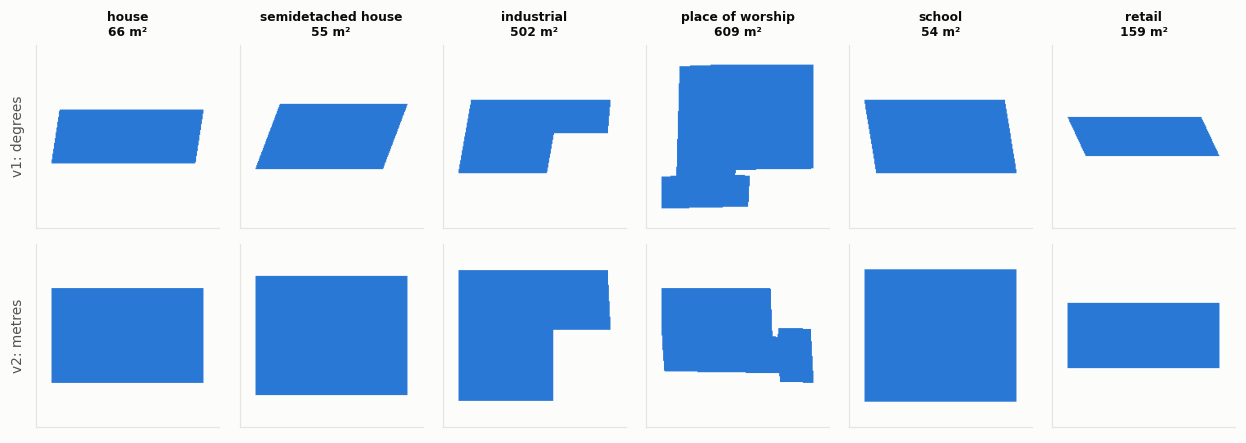

In [47]:
# The same footprints rasterised the v1 way (degrees) and the v2 way (metres).
from contextlib import contextmanager

@contextmanager
def raster_mode(metric):
    # poly_to_raster reads config.raster_metric; read_model sets it to match the model it loads.
    old = config.raster_metric
    config.raster_metric = metric
    try:
        yield
    finally:
        config.raster_metric = old

FP_CMAP = LinearSegmentedColormap.from_list('fp', [SURFACE, BLUE])
show = [bld.index[bld.cls == c][0] for c in ['building=house', 'building=semidetached_house', 'building=industrial',
                                            'amenity=place_of_worship', 'building=school', 'building=retail']]
fig, axes = plt.subplots(2, len(show), figsize=(1.9 * len(show), 4.1))
for i, metric in enumerate([False, True]):
    with raster_mode(metric):
        for ax, bi in zip(axes[i], show):
            ax.imshow(poly_to_raster(Polygon(entities[bld.id[bi]]['points']))[0], cmap=FP_CMAP, vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            for s in ax.spines.values():
                s.set_color(GRID)
            if i == 0:
                ax.set_title(f'{bld.cls[bi].split("=")[1].replace("_", " ")}\n{bld.area[bi]:,.0f} m²', fontsize=8)
axes[0, 0].set_ylabel('v1: degrees', fontsize=9); axes[1, 0].set_ylabel('v2: metres', fontsize=9)
plt.tight_layout(); plt.show()

**E2b.** How much building-class information the image network carries **before** stage-2 training, on §6's sample (18 balanced classes). Two measures:

* **Outline only:** leave-one-out 10-NN on the 512 numbers ResNet outputs per footprint, as in §6a.
* **Outline + log area:** a cross-validated linear classifier (logistic regression) on the same numbers plus log floor area. §6a found that area carries most of v1's signal, so this asks whether the outline adds anything on top.

The v1 rows show where v1's image network started (random weights) and where it ended (after 125 stage-2 steps). The last row is where v2 starts.

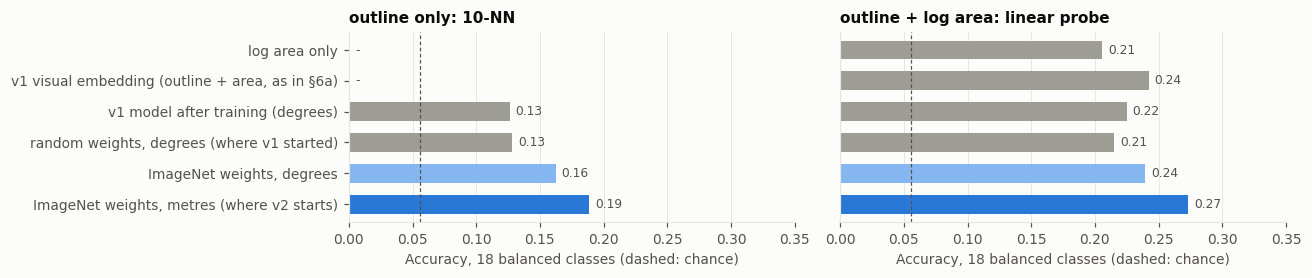

,outline only: 10-NN,outline + log area: linear probe
log area only,NaN,0.206
"v1 visual embedding (outline + area, as in §6a)",NaN,0.242
v1 model after training (degrees),0.126,0.225
"random weights, degrees (where v1 started)",0.128,0.215
"ImageNet weights, degrees",0.162,0.239
"ImageNet weights, metres (where v2 starts)",0.188,0.273


In [48]:
# How much building-class information the image network gives before any stage-2 training,
# on §6's sample. Features are the 512 numbers ResNet-18 outputs for each footprint.
from utils.models import SSModel
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def image_branch(pretrained):
    # Built exactly as SSModel builds it (utils/models.py), then the rest of the model is dropped.
    old = config.vision_pretrained
    config.vision_pretrained = pretrained
    try:
        torch.manual_seed(SEED)
        return SSModel(CITY, config.lm, 768).cv.eval()
    finally:
        config.vision_pretrained = old

def resnet_features(cv, metric):
    with raster_mode(metric):
        imgs = np.stack([poly_to_raster(Polygon(entities[i]['points'])) for i in bld.id]).astype(np.float32)
    return np.concatenate([cv(torch.tensor(imgs[s:s + 128])).flatten(1).numpy() for s in range(0, len(imgs), 128)])

FEATURES = {  # name: (how to build the network, rasterise in metres?)
    'v1 model after training (degrees)': (lambda: model.cv, False),
    'random weights, degrees (where v1 started)': (lambda: image_branch(False), False),
    'ImageNet weights, degrees': (lambda: image_branch(True), False),
    'ImageNet weights, metres (where v2 starts)': (lambda: image_branch(True), True),
}
feats = {name: cached(f'v2_footprint_features_{n}', bld.id, lambda: resnet_features(build(), metric))
         for n, (name, (build, metric)) in enumerate(FEATURES.items())}

log_area = np.log(bld[['area']].values)
folds = StratifiedKFold(5, shuffle=True, random_state=SEED)

def linear_probe(X):
    # Multinomial logistic regression with log area added, 5-fold cross-validated accuracy.
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1))
    return cross_val_score(clf, X, yb, cv=folds).mean()

def reduce(X):
    return PCA(50, random_state=SEED).fit_transform(l2(X))

probe = {'log area only': {'outline only: 10-NN': np.nan, 'outline + log area: linear probe': linear_probe(log_area)},
         'v1 visual embedding (outline + area, as in §6a)': {
             'outline only: 10-NN': np.nan, 'outline + log area: linear probe': linear_probe(np.hstack([reduce(Bv), log_area]))}}
for name, X in feats.items():
    probe[name] = {'outline only: 10-NN': accuracy(knn_predict(l2(X), yb), yb)['accuracy'],
                   'outline + log area: linear probe': linear_probe(np.hstack([reduce(X), log_area]))}
probe = pd.DataFrame(probe).T

fig, axes = plt.subplots(1, 2, figsize=(12, 2.6), sharey=True)
colours = [OTHER, OTHER, OTHER, OTHER, '#86b6ef', BLUE]
for ax, col in zip(axes, probe.columns):
    v = probe[col].values
    ax.barh(probe.index, np.nan_to_num(v), color=colours, height=0.6)
    for i, x in enumerate(v):
        ax.annotate('-' if np.isnan(x) else f'{x:.2f}', (np.nan_to_num(x), i), xytext=(4, 0), textcoords='offset points',
                    va='center', fontsize=8, color=INK2)
    ax.axvline(1 / len(CLASSES), color=INK2, lw=0.8, ls=(0, (3, 2)))
    ax.set_xlim(0, 0.35); ax.grid(axis='y', visible=False); ax.set_axisbelow(True)
    ax.set_xlabel(f'Accuracy, {len(CLASSES)} balanced classes (dashed: chance)'); ax.set_title(col, loc='left')
axes[0].invert_yaxis(); axes[1].tick_params(left=False)
plt.tight_layout(); plt.show()
probe.round(3)

**Reading E2b.**

* **v1's image network learned almost nothing in stage 2.** After training, its outline-only score (0.13) is the same as with random weights (0.13). With area added it is 0.22, against 0.21 for area alone.
* **Both fixes help, and together they give the best starting point.** ImageNet weights raise outline-only accuracy from 0.13 to 0.16, and rasterising in metres raises it again to 0.19, 3.4 times chance. With area added, v2's *untrained* network reaches 0.27, against 0.21 for area alone and 0.24 for v1's fully trained visual embedding.
* So v2 starts stage 2 ahead of where v1 finished. Whether stage 2 builds on that is a question for C4 and §6 once the model is back. One risk: stage 2 trains the whole image network with a learning rate 10 times stage 1's (`train_SS_raster`), which could overwrite some of the ImageNet features. If C4 shows no gain, freezing the early ResNet layers is the first thing to try.

## E3. The retrained models: v2, v3a and v3b

Three models have now been trained on the v2 inputs (collapsed houses, ImageNet image network, footprints in metres):

| Model | What changed | Training steps (stage 1 / 2 / 3) |
|---|---|---|
| **v2** | the v2 inputs, with the stock training code | 125 / 125 / 270 |
| **v3a** | v2 plus a fix to the learning-rate schedule (below) | 125 / 125 / 270 |
| **v3b** | v3a plus 5× longer stages 1 and 2 (`CityFM_train.py -m 32000`) | 625 / 625 / 270 |

**The learning-rate bug.** The *learning rate* is how big a change the model makes to its weights after each step. The original code shrinks it in a straight line to zero over training, but it worked out where "the end" was from the wrong number of steps (`num_steps = (len(queries) // bs) // 5` in `utils/training.py`). In Leeds this sent the rate to zero at step **43 of 125** in stage 1 and at step **10 of 270** in stage 3. After that the model stopped changing, so most of those steps were wasted. v1 and v2 both had this bug, and it is in the authors' code, so their models were probably affected too. The fix makes the rate reach zero on the last step.

**E3a.** Training loss for the three retrained models. Each line is a 15-step moving average, because every step is a different random quiz and single steps are noisy. The dotted line is the loss for pure guessing (C2). The dashed blue line marks where v2's learning rate reached zero.

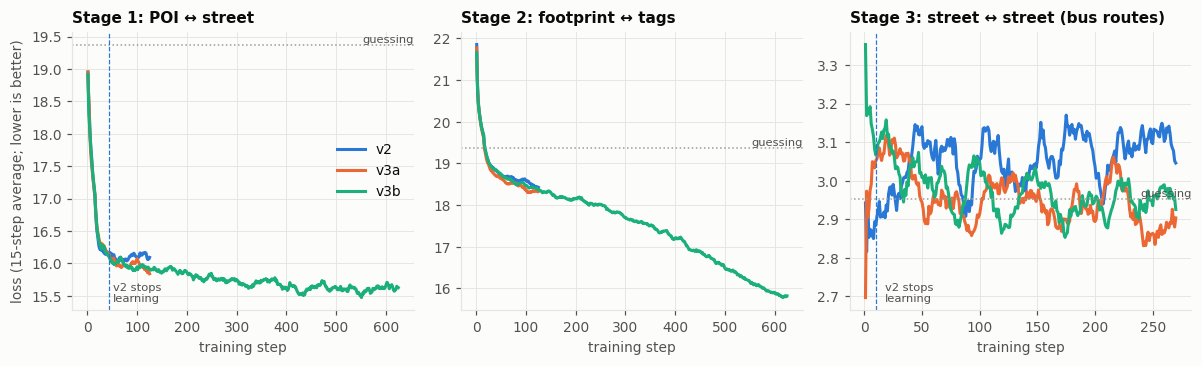

In [49]:
RETRAINED = {'v2': (CITY_V2, BLUE), 'v3a': ('Leeds_v3a', ORANGE), 'v3b': ('Leeds_v3b', AQUA)}
retrained_losses = {v: read_losses(Path(m) / 'Model' / 'train.log') for v, (m, _) in RETRAINED.items()}
SHORT = {'Infomax': 'Stage 1: POI ↔ street', 'Polygon': 'Stage 2: footprint ↔ tags',
         'Relation Contrastive Learning': 'Stage 3: street ↔ street (bus routes)'}
V2_LR_ZERO = {'Infomax': 43, 'Relation Contrastive Learning': 10}  # step where v2's learning rate reached 0

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (stage, (label, (chance, floor))) in zip(axes, STAGES.items()):
    for v, (_, colour) in RETRAINED.items():
        y = pd.Series(retrained_losses[v][stage])
        ax.plot(y.index + 1, y.rolling(15, min_periods=1).mean(), color=colour, lw=2, label=v)
    ax.axhline(chance, color=OTHER, lw=1, ls=':')
    ax.text(ax.get_xlim()[1], chance, 'guessing', ha='right', va='bottom', fontsize=7.5, color=INK2)
    if stage in V2_LR_ZERO:
        ax.axvline(V2_LR_ZERO[stage], color=BLUE, lw=0.8, ls='--')
        ax.text(V2_LR_ZERO[stage] + 8, ax.get_ylim()[0] + 0.03 * np.ptp(ax.get_ylim()),
                'v2 stops\nlearning', fontsize=7.5, color=INK2)
    ax.set_title(SHORT[stage], loc='left')
    ax.set_xlabel('training step')
axes[0].set_ylabel('loss (15-step average; lower is better)')
axes[0].legend(loc='center right')
plt.tight_layout()
plt.show()

rows = {}
for stage, (label, (chance, floor)) in STAGES.items():
    for v in RETRAINED:
        y = np.array(retrained_losses[v][stage])
        rows[(label.split(':')[0], v)] = {'steps': len(y), 'last 25 steps': y[-25:].mean(),
                                          'way from guessing to floor': (chance - y[-25:].mean()) / (chance - floor)}
pd.DataFrame(rows).T.style.format({'steps': '{:.0f}', 'last 25 steps': '{:.2f}', 'way from guessing to floor': '{:.0%}'})

**Reading E3a.**

* **The fix works.** In stage 1, v2 goes flat at step 43, while v3a keeps improving to the end. v3b keeps improving slowly for all 625 steps, and by the end it is 26% of the way from guessing to the floor, against 22% for v2.
* **Stage 2 benefits most from longer training.** v3b's footprint loss falls steadily, from 6% of the way to the floor (v2) to 24%, and it is still falling at step 625. Even more stage-2 training would probably help.
* **Stage 3 still learns almost nothing.** Even with a working learning rate, the street-to-street loss stays at the guessing line (1-2% of the way to the floor). So the problem is the bus-route objective itself, not the bug (ToDo 2).

Better training losses do not by themselves make the embeddings more useful. That is tested on a real task in part F.

---
# F. Population density: the first real test

Everything up to here measures CityFM on the quizzes it was trained on. This part asks the question that matters: **are the embeddings useful for something they were never trained to do?** The test is the one the CityFM authors use: predicting how many people live in each part of the city.

## F1. How the test works

**The target.** Population density from the 2021 Census (table TS006: residents per km²), for every Census **Output Area** in Leeds. `CityFM_uk_pop.py -c Leeds` downloads the data and the area boundaries from the ONS. It writes `Leeds/Data/pop_density.json` in the same format as the authors' New York and Singapore files, so their own `CityFM_downstream.py -t pop_density` also runs on Leeds.

**From an area to numbers.** For each area, `CityFM_pop_eval.py` collects every OSM entity inside it (houses, shops, schools, car parks, ...). It then turns them into features with the same recipe as the authors' task (`precompute_embs_pop_d`):

* **text**: the model's embedding of all the entities' tags, averaged (768 numbers);
* **footprints**: the model's visual embedding of the building outlines, averaged over a random sample of up to 20 polygons per area (768 numbers);
* **position**: the fixed position code of the area's centre (256 numbers).

**From numbers to a prediction.** A simple linear model (**ridge regression**) is fitted to predict density from the features. This is deliberately simple. If the embeddings contain the information, a linear model should find it, and a simple model cannot memorise the training areas. The model predicts the **logarithm** of density, because density ranges from about 10 to over 100,000 people per km². On a log scale, "twice as dense" counts the same everywhere, so a few very dense student blocks do not dominate the score.

**Scoring on unseen neighbourhoods.** Neighbouring areas have similar densities. If the test areas sat next to training areas, a model could score well just by recognising the location. So areas are grouped into neighbourhoods (MSOAs, about 25 Output Areas each; or 2 km blocks for the grid below), and the neighbourhoods are split into 5 groups. The model is trained on four groups and tested on the fifth, five times over, so every area is predicted once by a model that never saw its neighbourhood. This is **spatial cross-validation**. The score is **R²**: 1 means perfect predictions, and 0 means no better than predicting the Leeds average everywhere. The split into groups is repeated 10 times with different random groupings. The bars below show the average, and the whiskers the lowest and highest of the 10.

**What CityFM has to beat.** The same test is run with features that need no CityFM at all:

| Baseline | What it is |
|---|---|
| **9 simple counts** | Counts any analyst could make from OSM: entities, buildings, houses, POIs and apartment blocks (logged), the share of buildings that are houses, total and mean footprint area, and the share of the area covered by buildings |
| **Position only** | Just the position code: "how far from the centre, and in which direction" |
| **Untuned BERT text** | The same text recipe with the original BERT, before any CityFM training. The difference from CityFM's text shows what CityFM's training added |

In [50]:
# Rebuild the population-density units exactly as CityFM_pop_eval.py does, from its caches.
from pyproj import Transformer
from shapely.ops import transform
from matplotlib.collections import PolyCollection
from matplotlib.colors import LogNorm

with open(f'{CITY}/Data/pop_density.json', encoding='utf-8') as f:
    pop_d = json.load(f)
to_bng = Transformer.from_crs('EPSG:4326', 'EPSG:27700', always_xy=True).transform
oa_geoms = [transform(to_bng, Polygon(v['polygon'])) for v in pop_d.values()]

def pop_cache(name):
    return np.load(CACHE / f'pop_{name}.npz', allow_pickle=True)['x']

oa_m, grid = pop_cache('oa_members'), pop_cache('grid500')
UNITS = {
    'Output Areas': pd.DataFrame({
        'members': list(oa_m), 'density': [v['population'] * 1000 for v in pop_d.values()],
        'group': [v['msoa'] for v in pop_d.values()], 'geom': oa_geoms,
        'area_km2': [g.area / 1e6 for g in oa_geoms]}),
    '500 m grid': pd.DataFrame({
        'members': list(grid[:, 3]), 'density': grid[:, 2].astype(float),
        'group': [f'{int(cx * 500 // 2000)}_{int(cy * 500 // 2000)}' for cx, cy in grid[:, :2]],
        'geom': [Polygon([(cx * 500, cy * 500), ((cx + 1) * 500, cy * 500), ((cx + 1) * 500, (cy + 1) * 500),
                          (cx * 500, (cy + 1) * 500)]) for cx, cy in grid[:, :2]],
        'area_km2': 0.25})}
UNIT_TAG = {'Output Areas': 'output', '500 m grid': '500'}
# Units with no OSM entities are skipped, as in the shipped task.
UNITS = {u: df[df.members.map(len) > 0].reset_index(drop=True) for u, df in UNITS.items()}
oa_pop = UNITS['Output Areas'].density * UNITS['Output Areas'].area_km2
for u, df in UNITS.items():
    print(f'{u}: {len(df):,} areas, {df.group.nunique()} neighbourhood groups, '
          f'density {df.density.quantile(.1):,.0f}-{df.density.quantile(.9):,.0f} people per km² (10th-90th percentile)')
print(f'People per Output Area: median {oa_pop.median():.0f}, 10th-90th percentile {oa_pop.quantile(.1):.0f}-{oa_pop.quantile(.9):.0f}')

Output Areas: 2,598 areas, 107 neighbourhood groups, density 1,032-12,223 people per km² (10th-90th percentile)
500 m grid: 1,593 areas, 154 neighbourhood groups, density 49-5,059 people per km² (10th-90th percentile)
People per Output Area: median 299, 10th-90th percentile 220-417


## F2. Two ways of dividing up the city

**F2a.** Population density in Leeds, on Output Areas (left) and on a regular 500 m grid (right). Grid cells get their population from the Output Areas they overlap, in proportion to the overlap. The grid keeps only cells that lie wholly inside Leeds and contain at least one OSM entity, so the edges and some empty farmland drop out.

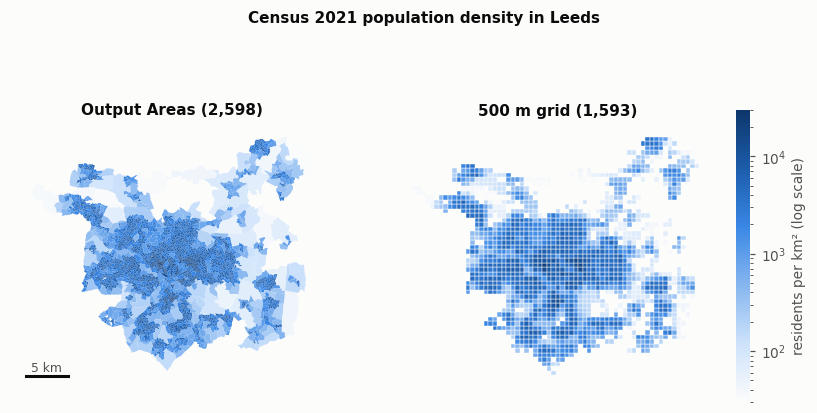

In [51]:
def rings(geoms):
    return [np.asarray(g.exterior.coords) for g in geoms]

DENSITY_NORM = LogNorm(30, 30000)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, (u, df) in zip(axes, UNITS.items()):
    pc = PolyCollection(rings(df.geom), array=df.density.clip(30, 30000), cmap=BLUES, norm=DENSITY_NORM,
                        edgecolors=SURFACE if u == '500 m grid' else 'none', linewidths=0.3)
    ax.add_collection(pc)
    ax.autoscale_view(); ax.set_aspect('equal'); clean_axes(ax)
    ax.set_title(f'{u} ({len(df):,})')
cb = fig.colorbar(pc, ax=axes, shrink=0.75, pad=0.02)
cb.set_label('residents per km² (log scale)')
cb.outline.set_visible(False)
x0 = axes[0].get_xlim()[0] + 1000
y0 = axes[0].get_ylim()[0] + 800
axes[0].plot([x0, x0 + 5000], [y0, y0], color=INK, lw=2)
axes[0].text(x0 + 2500, y0 + 500, '5 km', ha='center', fontsize=8, color=INK2)
fig.suptitle('Census 2021 population density in Leeds', fontweight='bold', fontsize=10)
plt.show()

**F2b.** Why Output Areas make a poor test. The Census draws Output Areas so that each holds a similar number of people (here, median 299; 80% hold 220-417). So a small area is a dense one, and density follows almost exactly from size.

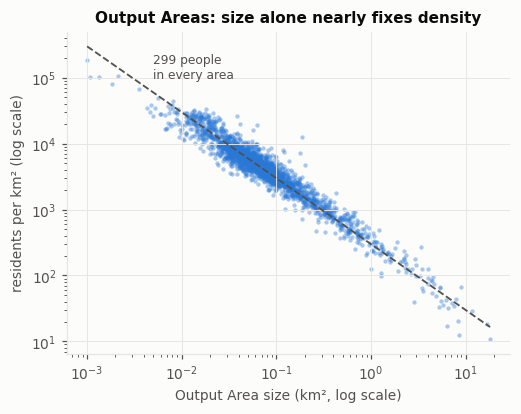

In [52]:
oa = UNITS['Output Areas']
fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.scatter(oa.area_km2, oa.density, s=8, color=BLUE, alpha=0.4, linewidths=0)
a = np.logspace(np.log10(oa.area_km2.min()), np.log10(oa.area_km2.max()), 50)
ax.plot(a, oa_pop.median() / a, color=INK2, lw=1.2, ls='--')
ax.text(a[8], oa_pop.median() / a[8] * 1.6, f'{oa_pop.median():.0f} people\nin every area', color=INK2, fontsize=8)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Output Area size (km², log scale)'); ax.set_ylabel('residents per km² (log scale)')
ax.set_title('Output Areas: size alone nearly fixes density')
plt.show()

**Reading F2.** On Output Areas, a model that knew only each area's size would predict density almost perfectly (R² 0.94 in F3). Any feature that tracks size, such as the number of buildings an area happens to contain, gets credit without saying anything about how people live. The authors' task uses areas like these too (New York census blocks, Singapore subzones).

**The 500 m grid removes this shortcut.** Every cell has the same size, so the only way to predict its density is to recognise what is built there. **The grid is the fair test**, and the Output Area results are shown for completeness.

## F3. Results

**F3a.** R² for each set of features, on the grid (left) and on Output Areas (right). Grey bars use no language model, orange is untuned BERT and blue is CityFM. "Text + footprints + position" is the combination the authors' task uses. Each score is the average over 10 random splits into neighbourhood groups, and the whiskers show the lowest and highest.

In [53]:
from utils.spatial_cv import spatial_cv_predict, r2

MODELS = {'v1': 'Leeds', 'v2': 'Leeds_v2', 'v3a': 'Leeds_v3a', 'v3b': 'Leeds_v3b'}
N_REPEATS = 10

def unit_features(u):
    t = UNIT_TAG[u]
    f = {'hand': pop_cache(f'hand_{t}'), 'pos': pop_cache(f'pos_{t}'),
         'bert': pop_cache(f'bert_text_collapsed_{t}'),
         'area': np.log10(UNITS[u].area_km2.values.astype(float))[:, None]}
    for v, m in MODELS.items():
        f[f'{v} text'], f[f'{v} visual'] = pop_cache(f'text_{t}_{m}'), pop_cache(f'visual_{t}_{m}')
    return f

def feature_sets(f, u):
    # (label, kind, features). kind sets the bar colour: no learned text, untuned BERT, or CityFM.
    sets = [('Area size only', 'simple', f['area'])] if u == 'Output Areas' else []
    sets += [('Position only', 'simple', f['pos']),
             ('9 simple counts', 'simple', f['hand']),
             ('9 simple counts + position', 'simple', np.hstack([f['hand'], f['pos']])),
             ('Untuned BERT text', 'bert', f['bert'])]
    for v in MODELS:
        sets.append((f'CityFM {v}: text', 'cityfm', f[f'{v} text']))
    sets.append(('CityFM v3b: footprints', 'cityfm', f['v3b visual']))
    for v in MODELS:
        sets.append((f'CityFM {v}: text + footprints + position', 'cityfm',
                     np.hstack([f[f'{v} text'], f[f'{v} visual'], f['pos']])))
    sets.append(('CityFM v3b: all + 9 simple counts', 'cityfm',
                 np.hstack([f['v3b text'], f['v3b visual'], f['pos'], f['hand']])))
    return sets

def spatial_cv_r2(X, df, repeats=N_REPEATS):
    # Neighbourhoods (MSOAs, or 2 km blocks of grid cells) are dealt into 5 folds at random, and each
    # fold is predicted by a ridge regression fitted on the other four (utils/spatial_cv.py, also used
    # by CityFM_pop_eval.py). Repeat r uses the same folds for every feature set, so the differences
    # between feature sets are paired.
    from threadpoolctl import threadpool_limits
    threadpool_limits(1)  # one core per job; jobs run in parallel
    y = np.log10(df.density.values + 1)
    preds = [spatial_cv_predict(X, y, df.group.values, seed=r) for r in range(repeats)]
    return np.array([r2(y, p) for p in preds]), preds[0]

path = CACHE / 'pop_cv_repeats.npz'
if path.exists():
    z = np.load(path, allow_pickle=True)
    pop_scores, pop_preds = z['scores'].item(), z['preds'].item()
else:
    from joblib import Parallel, delayed
    t0 = time.time()
    jobs = [(u, label, kind, X) for u in UNITS for label, kind, X in feature_sets(unit_features(u), u)]
    out = Parallel(n_jobs=8)(delayed(spatial_cv_r2)(X, UNITS[u][['density', 'group']]) for u, _, _, X in jobs)
    pop_scores = {(u, label, kind): s for (u, label, kind, _), (s, _) in zip(jobs, out)}
    pop_preds = {(u, label): p for (u, label, _, _), (_, p) in zip(jobs, out)}
    np.savez(path, scores=pop_scores, preds=pop_preds)
    print(f'scored in {time.time() - t0:.0f}s')

pop_table = pd.DataFrame({(u, label): {'R² (mean)': s.mean(), 'lowest': s.min(), 'highest': s.max()}
                          for (u, label, _), s in pop_scores.items()}).T
pop_table.style.format('{:.2f}')

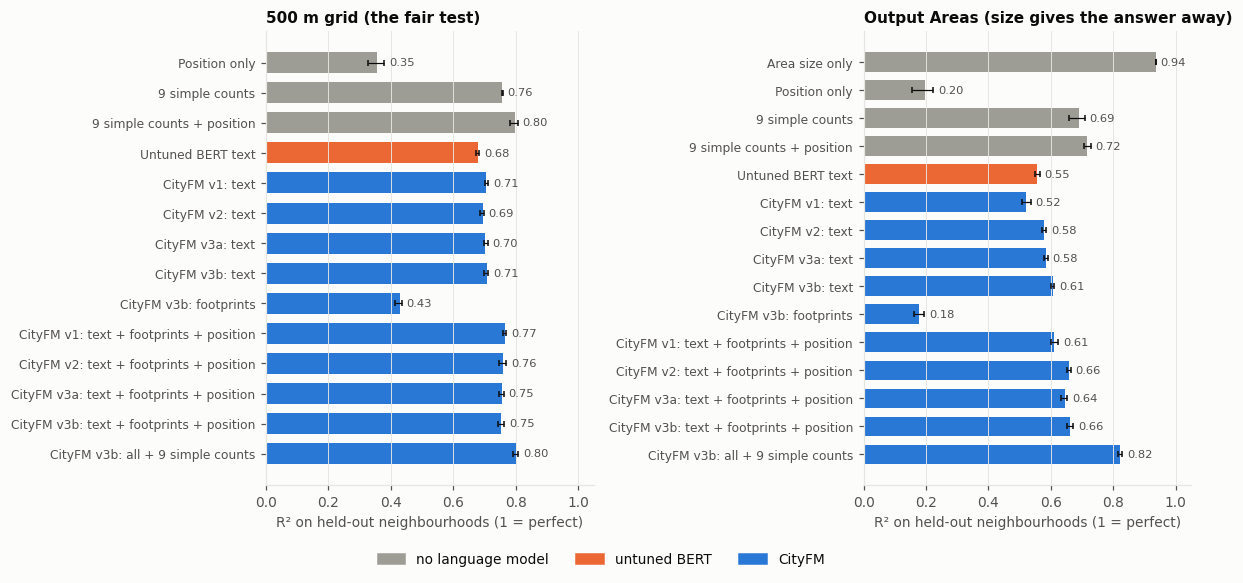

In [54]:
KIND_COLOURS = {'simple': OTHER, 'bert': ORANGE, 'cityfm': BLUE}
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True)
for ax, u in zip(axes, ['500 m grid', 'Output Areas']):
    items = [(label, kind, s) for (uu, label, kind), s in pop_scores.items() if uu == u][::-1]
    y = np.arange(len(items))
    means = np.array([s.mean() for *_, s in items])
    ax.barh(y, means, height=0.7, color=[KIND_COLOURS[k] for _, k, _ in items])
    ax.errorbar(means, y, xerr=[means - [s.min() for *_, s in items], [s.max() for *_, s in items] - means],
                fmt='none', ecolor=INK, elinewidth=0.8, capsize=2)
    for yy, m, (*_, s) in zip(y, means, items):
        ax.text(s.max() + 0.015, yy, f'{m:.2f}', va='center', fontsize=7.5, color=INK2)
    ax.set_yticks(y)
    ax.set_yticklabels([label for label, *_ in items], fontsize=8)
    ax.set_xlim(0, 1.05)
    ax.grid(axis='y', visible=False)
    ax.set_xlabel('R² on held-out neighbourhoods (1 = perfect)')
    ax.set_title(u + (' (the fair test)' if u == '500 m grid' else ' (size gives the answer away)'), loc='left')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in KIND_COLOURS.values()]
fig.legend(handles, ['no language model', 'untuned BERT', 'CityFM'], loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Reading F3a** (the grid unless stated otherwise).

* **Simple counts are the bar to beat, and it is high.** Nine counts of what OSM contains give R² 0.76, and adding position gives 0.80. In Leeds almost every house is mapped, so counting houses is already a very good guide to where people live.
* **CityFM's training adds a little to the text.** CityFM's text scores 0.69-0.71 for all four models, against 0.68 for untuned BERT. The whiskers do not overlap, so the gain is small but real: the context objective (stage 1) taught the model something about places.
* **The footprints carry some information, and longer training helped them.** v3b's footprint embedding alone reaches 0.43, against 0.37-0.38 for v1 to v3a (`CityFM_pop_eval.py`). That matches the much lower stage-2 loss in E3.
* **The authors' combination does not beat the counts.** Text + footprints + position gives 0.75-0.77 for every model, about the same as the 9 counts on their own and below counts + position (0.80).
* **CityFM adds nothing on top of the counts.** Counts + position + all of v3b's embeddings score 0.80, the same as counts + position alone. On this task, the embeddings hold no information that the counts lack.
* **The retrained models are no better than v1.** The differences between v1, v2, v3a and v3b are at most 0.01-0.02, about the size of the whiskers. The training improvements in E3 do not show up here.
* **On Output Areas** the ranking is similar, but every feature set is beaten by area size alone (0.94). CityFM does add to the counts there (0.82 vs 0.72), probably by picking up signs of a large area, such as fields and parks. The grid, where size gives nothing away, shows no such gain.

## F4. Where the predictions go wrong

**F4a.** Predicted against actual density for every grid cell, on one of the 10 splits. A perfect model would put every point on the dashed line. Left: the best baseline (9 counts + position). Right: the authors' CityFM combination with v3b.

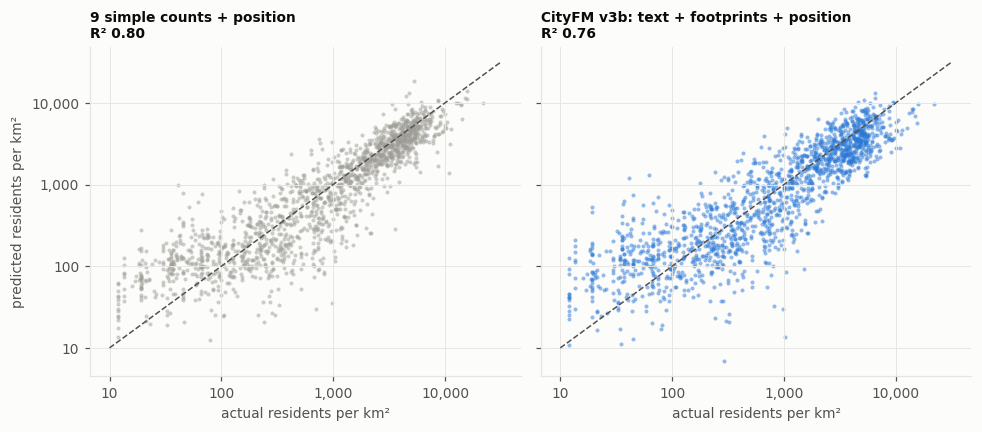

Typical miss (median absolute error): CityFM v3b x1.67, simple counts + position x1.51
Cells under 100 people per km² (282): CityFM over-predicts them by x2.6 on average


In [55]:
gr = UNITS['500 m grid']
actual = np.log10(gr.density.values + 1)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, (label, colour) in zip(axes, [('9 simple counts + position', OTHER),
                                      ('CityFM v3b: text + footprints + position', BLUE)]):
    pred = pop_preds[('500 m grid', label)]
    ax.scatter(actual, pred, s=7, color=colour, alpha=0.5, linewidths=0)
    ax.plot([1, 4.5], [1, 4.5], color=INK2, lw=1, ls='--')
    r2 = 1 - ((actual - pred) ** 2).sum() / ((actual - actual.mean()) ** 2).sum()
    ax.set_title(f'{label}\nR² {r2:.2f}', loc='left', fontsize=9)
    ticks = [1, 2, 3, 4]
    ax.set_xticks(ticks); ax.set_xticklabels([f'{10 ** t:,}' for t in ticks])
    ax.set_yticks(ticks); ax.set_yticklabels([f'{10 ** t:,}' for t in ticks])
    ax.set_xlabel('actual residents per km²')
axes[0].set_ylabel('predicted residents per km²')
plt.tight_layout()
plt.show()

# Where are the biggest misses for the CityFM model?
err = pop_preds[('500 m grid', 'CityFM v3b: text + footprints + position')] - actual
print(f'Typical miss (median absolute error): CityFM v3b x{10 ** np.median(np.abs(err)):.2f}, '
      f'simple counts + position x{10 ** np.median(np.abs(pop_preds[("500 m grid", "9 simple counts + position")] - actual)):.2f}')
low = actual < 2
print(f'Cells under 100 people per km² ({low.sum()}): CityFM over-predicts them by x{10 ** np.median(err[low]):.1f} on average')

**Reading F4a.** Both models do well in built-up Leeds, above about 1,000 people per km². Both struggle in the countryside. There, a cell may hold a few farms, a golf course or a business park, and the number of residents varies a lot for similar-looking OSM content. CityFM's typical miss is a factor of 1.67 (it predicts 1,670 or 600 where the truth is 1,000), against 1.51 for the counts. It over-predicts cells with fewer than 100 people per km² by a factor of 2.6 on average.

## F5. What this means

1. **The embeddings work, but in Leeds they don't add anything for population.** CityFM's features predict density well (R² 0.75-0.77 on the fair test), and its training improves on untuned BERT. But nine counts any analyst could compute do as well, and the embeddings add nothing to those counts. Whatever CityFM knows about where people live, it is already in "how many houses, flats and other buildings are there".
2. **Better training did not translate into a better embedding for this task.** The learning-rate fix and longer training clearly improved the training objectives (E3), especially the footprints, but the downstream score did not move.
3. **Population density may simply be too easy a test for Leeds.** UK OSM building data is close to complete, so counts are unusually strong. A task where counting is not enough would show better whether the embeddings capture anything more, for example deprivation (the Index of Multiple Deprivation), land use, or traffic flows.
4. **The training objectives still need work.** Stage 3 learns nothing (E3), and stage 2 mostly asks footprints to predict names (ToDo 3). Changing *what* the model is asked to learn is the more promising route than training the current objectives for longer.

**Reproducing.** `python CityFM_uk_pop.py -c Leeds` builds the target. `python CityFM_pop_eval.py -c Leeds -m Leeds Leeds_v2 Leeds_v3a Leeds_v3b` computes the features (cached in `Leeds/Analysis/pop_*.npz`, about 35 minutes per new model, mostly footprint images) and prints one split of each score. The repeated splits above are cached in `Leeds/Analysis/pop_cv_repeats.npz`. Delete it to recompute (about 15 minutes).